In [ ]:

# ============================================================
# STEP 21.1: ENVIRONMENT SETUP AND DATA VERIFICATION
# Project: MOCF-IoEVs Communication-Impairment Study
# Journal: Scientific Reports
# ============================================================

# 1. Import libraries

import os
import sys
import json
import time
import hashlib
import warnings

from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.stats import wilcoxon

from sklearn.metrics import mean_squared_error

warnings.filterwarnings("default")

print("=" * 75)
print("STEP 21.1: COMMUNICATION-IMPAIRMENT STUDY")
print("=" * 75)

# 2. Connect Google Drive

from google.colab import drive

drive.mount("/content/drive")

# 3. Define project directories

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

DATA_DIR = ROOT / "Data"
RESULTS_DIR = ROOT / "Results"
FIGURES_DIR = ROOT / "Figures"

STEP16_DIR = RESULTS_DIR / "Step16_Full_Ablation"
STEP17_DIR = RESULTS_DIR / "Step17_Comparison"
STEP18_DIR = RESULTS_DIR / "Step18_Statistics"
STEP20_DIR = RESULTS_DIR / "Step20_Final_Validation"

STEP21_DIR = RESULTS_DIR / "Step21_Communication_Impairment"
STEP21_FIGURES = FIGURES_DIR / "Step21"

STEP21_CHECKPOINTS = STEP21_DIR / "Checkpoints"

# Confirm existing project

if not ROOT.exists():
    raise FileNotFoundError(
        f"Project folder not found: {ROOT}"
    )

# Create new folders only

for directory in [
    STEP21_DIR,
    STEP21_FIGURES,
    STEP21_CHECKPOINTS
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("\nGoogle Drive connected.")
print("Project root:", ROOT)

# 4. Verify existing experimental files

REQUIRED_FILES = {
    "Community input data":
        DATA_DIR / "Step5_Community_Inputs.npz",

    "Step 16 individual results":
        STEP16_DIR / "Step16_Individual_Results.csv",

    "Step 16 Pareto solutions":
        STEP16_DIR / "Step16_Pareto_Solutions.csv",

    "Step 16 convergence history":
        STEP16_DIR / "Step16_Convergence_History.csv",

    "Step 17 comparison results":
        STEP17_DIR / "Step17_All_Method_Results.csv",

    "Step 18 primary statistics":
        STEP18_DIR / "Step18_Primary_Ablation_Statistics.csv"
}

file_records = []

for description, path in REQUIRED_FILES.items():

    exists = path.is_file()

    file_records.append({
        "description": description,
        "exists": exists,
        "size_mb": (
            round(path.stat().st_size / (1024 ** 2), 3)
            if exists else None
        ),
        "path": str(path)
    })

    status = "FOUND" if exists else "MISSING"

    print(f"{status}: {description}")

file_report = pd.DataFrame(file_records)

if not file_report["exists"].all():
    missing = file_report.loc[
        ~file_report["exists"], "path"
    ].tolist()

    raise FileNotFoundError(
        "Required files are missing:\n"
        + "\n".join(missing)
    )

# 5. Inspect original load and price inputs

input_path = REQUIRED_FILES["Community input data"]

with np.load(input_path, allow_pickle=False) as data:

    print("\nAvailable input arrays:")

    for key in data.files:
        print(
            f"  {key}: shape={data[key].shape}, "
            f"dtype={data[key].dtype}"
        )

    required_arrays = {"base_load_kw", "rt_price"}

    if not required_arrays.issubset(data.files):
        raise KeyError(
            "Missing required load or price arrays."
        )

    BASE_LOAD = np.asarray(
        data["base_load_kw"],
        dtype=float
    ).copy()

    RT_PRICE = np.asarray(
        data["rt_price"],
        dtype=float
    ).copy()

if BASE_LOAD.shape != (96,):
    raise ValueError(
        f"Expected 96 load intervals, found {BASE_LOAD.shape}"
    )

if RT_PRICE.shape != (96,):
    raise ValueError(
        f"Expected 96 price intervals, found {RT_PRICE.shape}"
    )

if not (
    np.isfinite(BASE_LOAD).all()
    and np.isfinite(RT_PRICE).all()
):
    raise ValueError(
        "Non-finite load or price data detected."
    )

# 6. Verify completed ablation runs

step16_results = pd.read_csv(
    REQUIRED_FILES["Step 16 individual results"]
)

expected_variants = {
    "C-NSGA-II",
    "IoT-NSGA-II",
    "ISO-IEC-NSGA-II",
    "I-NSGA-II"
}

required_columns = {
    "ev_count",
    "run_index",
    "variant"
}

if not required_columns.issubset(step16_results.columns):
    raise ValueError(
        "Step 16 results are missing required columns."
    )

expected_index = pd.MultiIndex.from_product(
    [
        [10, 30, 50],
        range(30),
        sorted(expected_variants)
    ],
    names=["ev_count", "run_index", "variant"]
)

actual_index = pd.MultiIndex.from_frame(
    step16_results[
        ["ev_count", "run_index", "variant"]
    ]
)

if (
    len(step16_results) != 360
    or not actual_index.is_unique
    or not actual_index.sort_values().equals(
        expected_index.sort_values()
    )
):
    raise ValueError(
        "Step 16 experimental coverage is incomplete "
        "or contains duplicate/unexpected runs."
    )

print("\nOriginal ablation runs verified:", len(step16_results))

# 7. Define planned experiment

STEP21_CONFIG = {
    "study": "Communication-impaired integrated NSGA-II",
    "fleet_sizes": [10, 30, 50],
    "independent_runs": 30,
    "time_slots": 96,
    "slot_duration_minutes": 15,
    "population_size": 50,
    "generations": 30,
    "charging_power_kw": 7.4,
    "charging_efficiency": 0.95,
    "base_seed": 42,
    "conditions": [
        "ideal",
        "delayed_information",
        "measurement_noise",
        "missing_information",
        "combined_impairments"
    ],
    "status": "setup_only"
}

# Save configuration without overwriting an existing study

config_path = (
    STEP21_DIR / "Step21_Experiment_Config.json"
)

if config_path.exists():
    with open(config_path, "r", encoding="utf-8") as f:
        existing_config = json.load(f)

    if existing_config != STEP21_CONFIG:
        raise RuntimeError(
            "An existing Step 21 configuration differs "
            "from the current setup. Review it before proceeding."
        )
else:
    with open(config_path, "w", encoding="utf-8") as f:
        json.dump(STEP21_CONFIG, f, indent=2)

# 8. Final setup summary

print("\n" + "=" * 75)
print("STEP 21.1 SETUP COMPLETED")
print("=" * 75)

print("Fleet sizes:", STEP21_CONFIG["fleet_sizes"])
print("Independent runs:", STEP21_CONFIG["independent_runs"])
print("Conditions:", len(STEP21_CONFIG["conditions"]))
print("Original optimization runs:", 360)
print("New optimization runs:", 0)

print("\nInput verification:")
print("Load intervals:", len(BASE_LOAD))
print("Price intervals:", len(RT_PRICE))

print("\nOutput folder:")
print(STEP21_DIR)

print("\nReady for Step 21.2")


STEP 21.1: COMMUNICATION-IMPAIRMENT STUDY


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Google Drive connected.
Project root: /content/drive/MyDrive/IOEV_Ablation_Study
FOUND: Community input data
FOUND: Step 16 individual results
FOUND: Step 16 Pareto solutions
FOUND: Step 16 convergence history
FOUND: Step 17 comparison results
FOUND: Step 18 primary statistics

Available input arrays:
  base_load_kw: shape=(96,), dtype=float64
  rt_price: shape=(96,), dtype=float64
  tou_price: shape=(96,), dtype=float64
  time_hours: shape=(96,), dtype=float64

Original ablation runs verified: 360

STEP 21.1 SETUP COMPLETED
Fleet sizes: [10, 30, 50]
Independent runs: 30
Conditions: 5
Original optimization runs: 360
New optimization runs: 0

Input verification:
Load intervals: 96
Price intervals: 96

Output folder:
/content/drive/MyDrive/IOEV_Ablation_Study/Results/Step21_Communication_Impairment

Ready for Step 21.2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

# ============================================================
# STEP 21.2: COMMUNICATION IMPAIRMENT MODELS
# ============================================================
# Requires Step 21.1
# No NSGA-II optimization performed
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd

from datetime import datetime, timezone

print("=" * 75)
print("STEP 21.2: COMMUNICATION IMPAIRMENT MODELS")
print("=" * 75)

# ------------------------------------------------------------
# 1. Verify Step 21.1
# ------------------------------------------------------------

required_globals = [
    "ROOT", "STEP21_DIR", "BASE_LOAD",
    "RT_PRICE", "STEP21_CONFIG"
]

missing_globals = [
    name for name in required_globals
    if name not in globals()
]

if missing_globals:
    raise RuntimeError(
        "Run Step 21.1 first. Missing: "
        + ", ".join(missing_globals)
    )

TRUE_LOAD = np.asarray(BASE_LOAD, dtype=float).copy()
TRUE_PRICE = np.asarray(RT_PRICE, dtype=float).copy()

N_SLOTS = 96

assert TRUE_LOAD.shape == (N_SLOTS,)
assert TRUE_PRICE.shape == (N_SLOTS,)
assert np.isfinite(TRUE_LOAD).all()
assert np.isfinite(TRUE_PRICE).all()

# ------------------------------------------------------------
# 2. Define impairment assumptions
# ------------------------------------------------------------

IMPAIRMENT_CONFIG = {
    "time_slots": 96,
    "slot_minutes": 15,
    "delay_slots": 1,
    "noise_relative_std": 0.05,
    "missing_probability": 0.10,
    "random_seed": 202621,
    "conditions": [
        "ideal",
        "delayed_information",
        "measurement_noise",
        "missing_information",
        "combined_impairments"
    ],
    "delay_interpretation": (
        "One-slot stale-information stress test, "
        "not equivalent to millisecond network latency"
    ),
    "missing_value_policy": (
        "Forward-fill using the most recently available "
        "observation; initial missing values use "
        "the first available observation"
    ),
    "noise_interpretation": (
        "Independent zero-mean Gaussian perturbations "
        "with standard deviation equal to 5 percent "
        "of each signal's absolute value"
    )
}

# ------------------------------------------------------------
# 3. Delay model
# ------------------------------------------------------------

def apply_information_delay(values, delay_slots=1):
    """
    Replace each value with an earlier observation.

    At the beginning of the horizon, use the
    first observation rather than wrapping around.
    """
    values = np.asarray(values, dtype=float)

    if delay_slots < 0:
        raise ValueError("Delay cannot be negative.")

    if delay_slots == 0:
        return values.copy()

    if delay_slots >= len(values):
        raise ValueError("Delay exceeds the horizon.")

    delayed = np.empty_like(values)

    delayed[:delay_slots] = values[0]
    delayed[delay_slots:] = values[:-delay_slots]

    return delayed


# ------------------------------------------------------------
# 4. Measurement noise model
# ------------------------------------------------------------

def apply_measurement_noise(
    values,
    rng,
    relative_std=0.05
):
    """
    Apply independent Gaussian measurement errors.
    Clip negative load and price observations to zero.
    """
    values = np.asarray(values, dtype=float)

    if relative_std < 0:
        raise ValueError("Noise level cannot be negative.")

    sigma = relative_std * np.abs(values)

    noisy = values + rng.normal(
        loc=0.0,
        scale=sigma,
        size=values.shape
    )

    return np.maximum(noisy, 0.0)


# ------------------------------------------------------------
# 5. Missing-information model
# ------------------------------------------------------------

def apply_missing_information(
    values,
    rng,
    missing_probability=0.10
):
    """
    Randomly mask observations and impute using
    the most recent available observation.
    """
    values = np.asarray(values, dtype=float)

    if not 0 <= missing_probability <= 1:
        raise ValueError(
            "Missing probability must be between 0 and 1."
        )

    missing_mask = (
        rng.random(len(values)) < missing_probability
    )

    observed = values.copy()
    observed[missing_mask] = np.nan

    imputed = (
        pd.Series(observed)
        .ffill()
        .bfill()
        .to_numpy(dtype=float)
    )

    if not np.isfinite(imputed).all():
        raise RuntimeError("Imputation failed.")

    return imputed, missing_mask


# ------------------------------------------------------------
# 6. Unified impairment function
# ------------------------------------------------------------

def simulate_communication_condition(
    load,
    price,
    condition,
    seed
):
    """
    Return the information perceived by the scheduler.

    True load and price remain unchanged and must
    be used later for actual performance evaluation.
    """
    load = np.asarray(load, dtype=float).copy()
    price = np.asarray(price, dtype=float).copy()

    rng = np.random.default_rng(seed)

    perceived_load = load.copy()
    perceived_price = price.copy()

    missing_load = np.zeros(len(load), dtype=bool)
    missing_price = np.zeros(len(price), dtype=bool)

    delay = IMPAIRMENT_CONFIG["delay_slots"]
    noise = IMPAIRMENT_CONFIG["noise_relative_std"]
    missing = IMPAIRMENT_CONFIG["missing_probability"]

    if condition in [
        "delayed_information",
        "combined_impairments"
    ]:
        perceived_load = apply_information_delay(
            perceived_load, delay
        )
        perceived_price = apply_information_delay(
            perceived_price, delay
        )

    if condition in [
        "measurement_noise",
        "combined_impairments"
    ]:
        perceived_load = apply_measurement_noise(
            perceived_load, rng, noise
        )
        perceived_price = apply_measurement_noise(
            perceived_price, rng, noise
        )

    if condition in [
        "missing_information",
        "combined_impairments"
    ]:
        perceived_load, missing_load = (
            apply_missing_information(
                perceived_load, rng, missing
            )
        )

        perceived_price, missing_price = (
            apply_missing_information(
                perceived_price, rng, missing
            )
        )

    if condition not in IMPAIRMENT_CONFIG["conditions"]:
        raise ValueError(
            f"Unknown condition: {condition}"
        )

    if not (
        np.isfinite(perceived_load).all()
        and np.isfinite(perceived_price).all()
    ):
        raise RuntimeError(
            "Non-finite perceived information detected."
        )

    return {
        "perceived_load_kw": perceived_load,
        "perceived_price": perceived_price,
        "missing_load_mask": missing_load,
        "missing_price_mask": missing_price
    }


# ------------------------------------------------------------
# 7. Test all five conditions
# ------------------------------------------------------------

records = []
example_profiles = {}

for index, condition in enumerate(
    IMPAIRMENT_CONFIG["conditions"]
):

    result = simulate_communication_condition(
        TRUE_LOAD,
        TRUE_PRICE,
        condition,
        seed=IMPAIRMENT_CONFIG["random_seed"] + index
    )

    load = result["perceived_load_kw"]
    price = result["perceived_price"]

    example_profiles[condition] = result

    records.append({
        "condition": condition,
        "load_mae_kw": float(
            np.mean(np.abs(load - TRUE_LOAD))
        ),
        "price_mae": float(
            np.mean(np.abs(price - TRUE_PRICE))
        ),
        "missing_load_pct": float(
            100 * result["missing_load_mask"].mean()
        ),
        "missing_price_pct": float(
            100 * result["missing_price_mask"].mean()
        ),
        "finite_values": bool(
            np.isfinite(load).all()
            and np.isfinite(price).all()
        )
    })

diagnostics = pd.DataFrame(records)

# ------------------------------------------------------------
# 8. Validation
# ------------------------------------------------------------

ideal = example_profiles["ideal"]

assert np.array_equal(
    ideal["perceived_load_kw"],
    TRUE_LOAD
)

assert np.array_equal(
    ideal["perceived_price"],
    TRUE_PRICE
)

assert np.array_equal(
    apply_information_delay(TRUE_LOAD, 0),
    TRUE_LOAD
)

assert np.array_equal(
    apply_information_delay(TRUE_LOAD, 1)[1:],
    TRUE_LOAD[:-1]
)

assert diagnostics["finite_values"].all()

# Deterministic reproducibility

test_a = simulate_communication_condition(
    TRUE_LOAD, TRUE_PRICE,
    "combined_impairments", seed=12345
)

test_b = simulate_communication_condition(
    TRUE_LOAD, TRUE_PRICE,
    "combined_impairments", seed=12345
)

assert np.array_equal(
    test_a["perceived_load_kw"],
    test_b["perceived_load_kw"]
)

assert np.array_equal(
    test_a["perceived_price"],
    test_b["perceived_price"]
)

# ------------------------------------------------------------
# 9. Save configuration and diagnostics
# ------------------------------------------------------------

config_file = (
    STEP21_DIR / "Step21_Impairment_Config.json"
)

diagnostics_file = (
    STEP21_DIR / "Step21_Impairment_Diagnostics.csv"
)

if config_file.exists():
    with open(config_file, "r", encoding="utf-8") as f:
        previous_config = json.load(f)

    if previous_config != IMPAIRMENT_CONFIG:
        raise RuntimeError(
            "Existing impairment configuration differs. "
            "Review before overwriting."
        )
else:
    with open(config_file, "w", encoding="utf-8") as f:
        json.dump(IMPAIRMENT_CONFIG, f, indent=2)

diagnostics.to_csv(
    diagnostics_file,
    index=False
)

# ------------------------------------------------------------
# 10. Display results
# ------------------------------------------------------------

print("\nIMPAIRMENT DIAGNOSTICS")
print(
    diagnostics.round(5).to_string(index=False)
)

print("\n" + "=" * 75)
print("STEP 21.2 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Conditions validated:", len(diagnostics))
print("Time slots:", N_SLOTS)
print("Delay stress test:", 15, "minutes")
print("Measurement noise:", "5% relative SD")
print("Missing probability:", "10%")
print("Optimization runs performed:", 0)

print("\nSaved:")
print(config_file)
print(diagnostics_file)

print("\nReady for Step 21.3")


STEP 21.2: COMMUNICATION IMPAIRMENT MODELS

IMPAIRMENT DIAGNOSTICS
           condition  load_mae_kw  price_mae  missing_load_pct  missing_price_pct  finite_values
               ideal      0.00000    0.00000           0.00000            0.00000           True
 delayed_information      1.66250    0.00063           0.00000            0.00000           True
   measurement_noise      4.14797    0.00396           0.00000            0.00000           True
 missing_information      0.07500    0.00000           4.16667           10.41667           True
combined_impairments      5.07468    0.00374           8.33333           10.41667           True

STEP 21.2 COMPLETED SUCCESSFULLY
Conditions validated: 5
Time slots: 96
Delay stress test: 15 minutes
Measurement noise: 5% relative SD
Missing probability: 10%
Optimization runs performed: 0

Saved:
/content/drive/MyDrive/IOEV_Ablation_Study/Results/Step21_Communication_Impairment/Step21_Impairment_Config.json
/content/drive/MyDrive/IOEV_Ablation_

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

# ============================================================
# STEP 21.3: RESTORE AND VERIFY OPTIMIZATION FRAMEWORK
# ============================================================
# Inspect original configuration, checkpoints,
# source files, and available optimization functions.
#
# No NSGA-II optimization is performed.
# No original files are modified.
# ============================================================

import json
import inspect
import hashlib
import pandas as pd
import numpy as np

from pathlib import Path

print("=" * 75)
print("STEP 21.3: ORIGINAL OPTIMIZATION FRAMEWORK")
print("=" * 75)

# ------------------------------------------------------------
# 1. Verify previous setup
# ------------------------------------------------------------

required_globals = [
    "ROOT",
    "STEP16_DIR",
    "STEP21_DIR",
    "STEP21_CONFIG",
    "IMPAIRMENT_CONFIG"
]

missing = [
    name for name in required_globals
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Please run Steps 21.1 and 21.2 first. "
        f"Missing variables: {missing}"
    )

# ------------------------------------------------------------
# 2. Identify original experiment files
# ------------------------------------------------------------

manifest_path = (
    STEP16_DIR / "Step16_Experiment_Manifest.json"
)

checkpoint_dir = STEP16_DIR / "Checkpoints"

if not manifest_path.exists():
    raise FileNotFoundError(
        f"Missing original manifest: {manifest_path}"
    )

if not checkpoint_dir.exists():
    raise FileNotFoundError(
        f"Missing checkpoint directory: {checkpoint_dir}"
    )

with open(
    manifest_path,
    "r",
    encoding="utf-8"
) as file:
    manifest = json.load(file)

print("\nORIGINAL EXPERIMENT MANIFEST")

print(
    json.dumps(
        manifest,
        indent=2,
        default=str
    )[:12000]
)

# ------------------------------------------------------------
# 3. Inspect checkpoint structure
# ------------------------------------------------------------

checkpoint_files = sorted(
    checkpoint_dir.glob("*.json")
)

print("\nCHECKPOINT VERIFICATION")
print("Checkpoint files:", len(checkpoint_files))

if len(checkpoint_files) != 360:
    raise RuntimeError(
        "Expected 360 original checkpoints, "
        f"found {len(checkpoint_files)}."
    )

sample_checkpoint = checkpoint_files[0]

with open(
    sample_checkpoint,
    "r",
    encoding="utf-8"
) as file:
    checkpoint = json.load(file)

print("\nSample checkpoint:")
print(sample_checkpoint.name)

print("\nTop-level checkpoint keys:")
for key in checkpoint.keys():
    print(" ", key)

print("\nCheckpoint summary keys:")
for key in checkpoint.get("summary", {}).keys():
    print(" ", key)

print("\nFirst history record keys:")

history = checkpoint.get("history_rows", [])

if history:
    for key in history[0].keys():
        print(" ", key)
else:
    print("No history records found.")

# ------------------------------------------------------------
# 4. Check optimization functions in current session
# ------------------------------------------------------------

function_names = [
    "generate_ev_scenario",
    "validate_scenario",
    "build_fair_variant_information",
    "run_nsga2",
    "repair_nsga_schedule",
    "evaluate_charging_schedule",
    "validate_operational_feasibility"
]

function_records = []

print("\nOPTIMIZATION FUNCTION AVAILABILITY")

for name in function_names:

    obj = globals().get(name)

    available = callable(obj)

    if available:
        try:
            signature = str(
                inspect.signature(obj)
            )
        except Exception:
            signature = "Unavailable"
    else:
        signature = "Not loaded"

    function_records.append({
        "function": name,
        "available": available,
        "signature": signature
    })

    print(
        f"{'AVAILABLE' if available else 'NOT LOADED'}: "
        f"{name}"
    )

function_report = pd.DataFrame(
    function_records
)

# ------------------------------------------------------------
# 5. Search project for Python source files
# ------------------------------------------------------------

print("\nSEARCHING PROJECT SOURCE FILES")

source_files = sorted(
    path for path in ROOT.rglob("*.py")
    if path.is_file()
)

notebooks = sorted(
    path for path in ROOT.rglob("*.ipynb")
    if path.is_file()
)

source_records = []

for path in source_files:

    relative = str(path.relative_to(ROOT))

    source_records.append({
        "type": "python",
        "path": relative,
        "size_kb": round(
            path.stat().st_size / 1024,
            2
        )
    })

for path in notebooks:

    relative = str(path.relative_to(ROOT))

    source_records.append({
        "type": "notebook",
        "path": relative,
        "size_kb": round(
            path.stat().st_size / 1024,
            2
        )
    })

source_report = pd.DataFrame(
    source_records,
    columns=["type", "path", "size_kb"]
)

if source_report.empty:
    print(
        "No Python source files or notebooks "
        "found inside the project directory."
    )
else:
    print(
        source_report.to_string(index=False)
    )

# ------------------------------------------------------------
# 6. Check original configuration variables
# ------------------------------------------------------------

print("\nORIGINAL CONFIGURATION AVAILABILITY")

config_names = [
    "CONFIG",
    "FINAL_ABLATION_CONFIG",
    "CONFIG_HASH",
    "TRUE_LOAD",
    "TRUE_PRICE"
]

for name in config_names:

    if name in globals():
        print(f"AVAILABLE: {name}")
    else:
        print(f"NOT LOADED: {name}")

# ------------------------------------------------------------
# 7. Save inspection report
# ------------------------------------------------------------

report = {
    "step": "21.3",
    "original_checkpoint_count": len(
        checkpoint_files
    ),
    "original_manifest_exists": True,
    "functions_available": {
        row["function"]: bool(row["available"])
        for row in function_records
    },
    "python_source_files": len(source_files),
    "notebook_files": len(notebooks),
    "optimization_runs_performed": 0
}

report_path = (
    STEP21_DIR /
    "Step21_Original_Framework_Inspection.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        report,
        file,
        indent=2
    )

function_report.to_csv(
    STEP21_DIR /
    "Step21_Function_Availability.csv",
    index=False
)

source_report.to_csv(
    STEP21_DIR /
    "Step21_Source_File_Inventory.csv",
    index=False
)

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 21.3 INSPECTION COMPLETED")
print("=" * 75)

print(
    "Original checkpoints:",
    len(checkpoint_files)
)

print(
    "Optimization functions available:",
    int(function_report["available"].sum()),
    "/",
    len(function_names)
)

print(
    "Python source files:",
    len(source_files)
)

print(
    "Notebook files:",
    len(notebooks)
)

print("Optimization runs performed: 0")

print("\nInspection report:")
print(report_path)

print("\nReady for Step 21.4 after source verification.")


STEP 21.3: ORIGINAL OPTIMIZATION FRAMEWORK

ORIGINAL EXPERIMENT MANIFEST
{
  "experiment": "Step16_Full_Ablation",
  "status": "complete",
  "total_runs": 360,
  "new_runs_this_execution": 360,
  "reused_checkpoints": 0,
  "config_hash": "afd079c0ca544e6702044cba5a3de447c8bc54a9fac7fba6694810f0b3416694",
  "input_hash": "62e9916e389c0f4d7871a97f9504f2d85624fca8d4063a3580e06858e20d8f54",
  "variants": [
    "C-NSGA-II",
    "IoT-NSGA-II",
    "ISO-IEC-NSGA-II",
    "I-NSGA-II"
  ],
  "ev_counts": [
    10,
    30,
    50
  ],
  "independent_runs": 30,
  "population_size": 50,
  "generations": 30,
  "execution_seconds": 7894.693257662,
  "completed_utc": "2026-11-18T14:21:53.286553+00:00",
  "limitations": [
    "Controller scheduling uses a complete 96-slot information profile. This is a perfect-horizon representation of simulated information, not verified causal real-time closed-loop control.",
    "ISO 15118 and IEC 61850 components are represented by simplified standards-inspired mes

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

# ============================================================
# STEP 21.4: RECOVER ORIGINAL OPTIMIZATION SOURCE CODE
# ============================================================
# Project: MOCF-IoEVs Communication-Impairment Study
#
# Read the original ablation notebook.
# Identify optimization functions and dependencies.
# Save an unchanged source-code copy.
#
# No optimization is performed.
# ============================================================

import ast
import json
import hashlib
import pandas as pd

from pathlib import Path

print("=" * 75)
print("STEP 21.4: ORIGINAL OPTIMIZATION CODE RECOVERY")
print("=" * 75)

# ------------------------------------------------------------
# 1. Verify original notebook
# ------------------------------------------------------------

ORIGINAL_NOTEBOOK = ROOT / "AblationStudyIOEV.ipynb"

if not ORIGINAL_NOTEBOOK.is_file():
    raise FileNotFoundError(
        f"Original notebook not found: {ORIGINAL_NOTEBOOK}"
    )

with open(
    ORIGINAL_NOTEBOOK,
    "r",
    encoding="utf-8"
) as f:
    original_notebook = json.load(f)

cells = original_notebook.get("cells", [])

code_cells = [
    (index, cell)
    for index, cell in enumerate(cells)
    if cell.get("cell_type") == "code"
]

print("Original notebook:", ORIGINAL_NOTEBOOK.name)
print("Total cells:", len(cells))
print("Code cells:", len(code_cells))

# ------------------------------------------------------------
# 2. Extract code without executing it
# ------------------------------------------------------------

source_sections = []
function_records = []
class_records = []
parse_errors = []

for cell_index, cell in code_cells:

    source = "".join(cell.get("source", []))

    if not source.strip():
        continue

    source_sections.append(
        f"\n# ORIGINAL NOTEBOOK CELL {cell_index}\n"
        + source
        + "\n"
    )

    # Colab magics are not valid Python syntax.
    # Skip AST parsing for cells containing magics.
    lines = source.splitlines()

    clean_lines = []

    for line in lines:
        stripped = line.lstrip()

        if stripped.startswith(("%", "!", "?")):
            clean_lines.append("pass")
        else:
            clean_lines.append(line)

    clean_source = "\n".join(clean_lines)

    try:
        tree = ast.parse(clean_source)

    except SyntaxError as error:
        parse_errors.append({
            "cell": cell_index,
            "error": str(error)
        })
        continue

    for node in tree.body:

        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ):
            function_records.append({
                "function": node.name,
                "cell": cell_index,
                "line": node.lineno,
                "arguments": [
                    arg.arg
                    for arg in node.args.args
                ]
            })

        elif isinstance(node, ast.ClassDef):

            class_records.append({
                "class": node.name,
                "cell": cell_index,
                "line": node.lineno
            })

# ------------------------------------------------------------
# 3. Save an unchanged copy of original code
# ------------------------------------------------------------

ORIGINAL_SOURCE = (
    STEP21_DIR /
    "Step21_Original_Notebook_Source.txt"
)

combined_source = "\n".join(source_sections)

source_hash = hashlib.sha256(
    combined_source.encode("utf-8")
).hexdigest()

if ORIGINAL_SOURCE.exists():

    existing_source = ORIGINAL_SOURCE.read_text(
        encoding="utf-8"
    )

    if existing_source != combined_source:
        raise RuntimeError(
            "Existing source copy differs from the "
            "current original notebook. Review before replacing."
        )

else:
    ORIGINAL_SOURCE.write_text(
        combined_source,
        encoding="utf-8"
    )

print("\nOriginal source SHA256:")
print(source_hash)

# ------------------------------------------------------------
# 4. Build function inventory
# ------------------------------------------------------------

functions_df = pd.DataFrame(
    function_records,
    columns=[
        "function",
        "cell",
        "line",
        "arguments"
    ]
)

classes_df = pd.DataFrame(
    class_records,
    columns=[
        "class",
        "cell",
        "line"
    ]
)

print("\nTOTAL DEFINITIONS")
print("Functions:", len(functions_df))
print("Classes:", len(classes_df))
print("Cells with AST parsing errors:", len(parse_errors))

# ------------------------------------------------------------
# 5. Find relevant optimization functions
# ------------------------------------------------------------

keywords = [
    "nsga",
    "scenario",
    "charging",
    "schedule",
    "repair",
    "evaluate",
    "fitness",
    "objective",
    "pareto",
    "variant",
    "feasib",
    "population",
    "mutation",
    "crossover",
    "dominance",
    "select"
]

if not functions_df.empty:

    relevant = functions_df[
        functions_df["function"]
        .str.lower()
        .apply(
            lambda name: any(
                keyword in name
                for keyword in keywords
            )
        )
    ].copy()

else:
    relevant = functions_df.copy()

print("\nRELEVANT FUNCTION DEFINITIONS")

if relevant.empty:
    print("No matching function definitions found.")
else:
    print(
        relevant[
            ["function", "cell", "line"]
        ].to_string(index=False)
    )

# ------------------------------------------------------------
# 6. Identify exact required functions
# ------------------------------------------------------------

required_functions = [
    "generate_ev_scenario",
    "validate_scenario",
    "build_fair_variant_information",
    "run_nsga2",
    "repair_nsga_schedule",
    "evaluate_charging_schedule",
    "validate_operational_feasibility"
]

print("\nREQUIRED OPTIMIZATION FUNCTIONS")

available_names = set(
    functions_df["function"].tolist()
)

for name in required_functions:

    if name in available_names:

        locations = functions_df.loc[
            functions_df["function"] == name,
            "cell"
        ].tolist()

        print(
            f"FOUND: {name}, cells {locations}"
        )

    else:
        print(f"NOT FOUND: {name}")

# ------------------------------------------------------------
# 7. Save inventories
# ------------------------------------------------------------

functions_file = (
    STEP21_DIR /
    "Step21_Original_Function_Inventory.csv"
)

classes_file = (
    STEP21_DIR /
    "Step21_Original_Class_Inventory.csv"
)

functions_df.to_csv(
    functions_file,
    index=False
)

classes_df.to_csv(
    classes_file,
    index=False
)

# ------------------------------------------------------------
# 8. Save recovery report
# ------------------------------------------------------------

recovery_report = {
    "step": "21.4",
    "original_notebook": str(ORIGINAL_NOTEBOOK),
    "total_cells": len(cells),
    "code_cells": len(code_cells),
    "function_definitions": len(functions_df),
    "class_definitions": len(classes_df),
    "source_sha256": source_hash,
    "required_functions_found": {
        name: name in available_names
        for name in required_functions
    },
    "parse_errors": parse_errors,
    "optimization_runs_performed": 0
}

report_file = (
    STEP21_DIR /
    "Step21_Source_Recovery_Report.json"
)

with open(
    report_file,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        recovery_report,
        f,
        indent=2
    )

# ------------------------------------------------------------
# 9. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 21.4 SOURCE RECOVERY COMPLETED")
print("=" * 75)

print("Total functions:", len(functions_df))
print("Relevant functions:", len(relevant))
print("Original source preserved:", ORIGINAL_SOURCE.exists())
print("Optimization runs performed: 0")

print("\nSaved files:")
print(ORIGINAL_SOURCE.name)
print(functions_file.name)
print(classes_file.name)
print(report_file.name)

print("\nReady for source dependency verification.")


STEP 21.4: ORIGINAL OPTIMIZATION CODE RECOVERY
Original notebook: AblationStudyIOEV.ipynb
Total cells: 54
Code cells: 54

Original source SHA256:
7c1e10dde479ac1a4e49df94b21e1159c025bd9be6f236a996f2d5cb80f4f003

TOTAL DEFINITIONS
Functions: 51
Classes: 0
Cells with AST parsing errors: 0

RELEVANT FUNCTION DEFINITIONS
                        function  cell  line
               get_scenario_seed     2   168
               get_scenario_seed     4    83
            generate_ev_scenario     4    99
               validate_scenario     4   267
      evaluate_charging_schedule     6    45
    construct_reference_schedule     6   281
               priority_schedule    12   114
             nsga_energy_targets    14    83
            repair_nsga_schedule    14   110
                 nsga_objectives    14   238
                  nsga_dominates    14   267
         nsga_non_dominated_sort    14   279
                   nsga_crowding    14   345
          nsga_rank_and_crowding    14   407
      

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

# ============================================================
# STEP 21.5: SOURCE DEPENDENCY AND INTERFACE VERIFICATION
# ============================================================
# Inspect original notebook cells without executing them.
# Identify function signatures, global dependencies,
# and configuration variables.
# ============================================================

import ast
import json
import hashlib
import builtins
import pandas as pd

print("=" * 75)
print("STEP 21.5: OPTIMIZATION DEPENDENCY VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Verify recovered notebook
# ------------------------------------------------------------

if "original_notebook" not in globals():
    raise RuntimeError(
        "Please run Step 21.4 first."
    )

if "cells" not in globals():
    raise RuntimeError(
        "Original notebook cells are unavailable."
    )

# ------------------------------------------------------------
# 2. Select essential source cells
# ------------------------------------------------------------

ESSENTIAL_CELLS = [2, 4, 6, 14, 16, 18, 20, 28]

TARGET_FUNCTIONS = [
    "generate_ev_scenario",
    "validate_scenario",
    "evaluate_charging_schedule",
    "repair_nsga_schedule",
    "nsga_objectives",
    "run_nsga2",
    "build_variant_information",
    "select_compromise_solution",
    "build_fair_variant_information",
    "validate_operational_feasibility"
]

# ------------------------------------------------------------
# 3. Extract function signatures and references
# ------------------------------------------------------------

class DependencyVisitor(ast.NodeVisitor):

    def __init__(self):
        self.loaded = set()
        self.stored = set()

    def visit_Name(self, node):

        if isinstance(node.ctx, ast.Load):
            self.loaded.add(node.id)

        elif isinstance(
            node.ctx,
            (ast.Store, ast.Del)
        ):
            self.stored.add(node.id)

        self.generic_visit(node)


records = []

all_function_names = set(
    functions_df["function"].tolist()
)

builtin_names = set(dir(builtins))

for cell_index in ESSENTIAL_CELLS:

    source = "".join(
        cells[cell_index].get("source", [])
    )

    tree = ast.parse(source)

    for node in tree.body:

        if not isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ):
            continue

        if node.name not in TARGET_FUNCTIONS:
            continue

        arguments = [
            arg.arg for arg in node.args.args
        ]

        visitor = DependencyVisitor()

        for statement in node.body:
            visitor.visit(statement)

        possible_globals = sorted(
            visitor.loaded
            - visitor.stored
            - set(arguments)
            - builtin_names
        )

        function_dependencies = sorted(
            set(possible_globals)
            & all_function_names
        )

        other_references = sorted(
            set(possible_globals)
            - all_function_names
        )

        records.append({
            "function": node.name,
            "cell": cell_index,
            "arguments": ", ".join(arguments),
            "function_dependencies": ", ".join(
                function_dependencies
            ),
            "other_references": ", ".join(
                other_references
            )
        })

dependency_df = pd.DataFrame(records)

# ------------------------------------------------------------
# 4. Print optimizer interfaces
# ------------------------------------------------------------

print("\nFUNCTION INTERFACES")

for _, row in dependency_df.iterrows():

    print("\nFunction:", row["function"])
    print("Cell:", row["cell"])
    print("Arguments:", row["arguments"])

    print(
        "Function dependencies:",
        row["function_dependencies"] or "None detected"
    )

    print(
        "Other references:",
        row["other_references"] or "None detected"
    )

# ------------------------------------------------------------
# 5. Inspect key function source snippets
# ------------------------------------------------------------

KEY_FUNCTIONS = [
    "run_nsga2",
    "nsga_objectives",
    "build_fair_variant_information",
    "evaluate_charging_schedule"
]

print("\n" + "=" * 75)
print("KEY FUNCTION SOURCE INSPECTION")
print("=" * 75)

for cell_index in ESSENTIAL_CELLS:

    source = "".join(
        cells[cell_index].get("source", [])
    )

    tree = ast.parse(source)

    source_lines = source.splitlines()

    for node in tree.body:

        if not isinstance(node, ast.FunctionDef):
            continue

        if node.name not in KEY_FUNCTIONS:
            continue

        snippet = "\n".join(
            source_lines[
                node.lineno - 1:
                min(node.end_lineno, node.lineno + 45)
            ]
        )

        print(
            f"\n{'=' * 65}\n"
            f"FUNCTION: {node.name}\n"
            f"CELL: {cell_index}\n"
            f"{'=' * 65}"
        )

        print(snippet)

# ------------------------------------------------------------
# 6. Inspect configuration assignments
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CONFIGURATION ASSIGNMENTS")
print("=" * 75)

CONFIG_KEYWORDS = [
    "CONFIG",
    "SEED",
    "POPULATION",
    "GENERATION",
    "CHARGER",
    "EFFICIENCY",
    "SLOT",
    "HORIZON"
]

config_records = []

for cell_index, cell in code_cells:

    source = "".join(
        cell.get("source", [])
    )

    tree = ast.parse(source)

    for node in tree.body:

        if isinstance(node, ast.Assign):

            targets = []

            for target in node.targets:

                if isinstance(target, ast.Name):
                    targets.append(target.id)

            for name in targets:

                if any(
                    keyword in name.upper()
                    for keyword in CONFIG_KEYWORDS
                ):
                    config_records.append({
                        "cell": cell_index,
                        "variable": name,
                        "line": node.lineno
                    })

config_df = pd.DataFrame(config_records)

if config_df.empty:
    print("No matching assignments found.")
else:
    print(config_df.to_string(index=False))

# ------------------------------------------------------------
# 7. Save dependency report
# ------------------------------------------------------------

dependency_path = (
    STEP21_DIR /
    "Step21_Optimizer_Dependencies.csv"
)

config_path = (
    STEP21_DIR /
    "Step21_Original_Config_Assignments.csv"
)

dependency_df.to_csv(
    dependency_path,
    index=False
)

config_df.to_csv(
    config_path,
    index=False
)

print("\n" + "=" * 75)
print("STEP 21.5 COMPLETED")
print("=" * 75)

print("Target functions inspected:", len(dependency_df))
print("Configuration assignments:", len(config_df))
print("Optimization runs performed: 0")

print("\nSaved:")
print(dependency_path.name)
print(config_path.name)

print("\nReady for optimizer integration planning.")


STEP 21.5: OPTIMIZATION DEPENDENCY VERIFICATION

FUNCTION INTERFACES

Function: generate_ev_scenario
Cell: 4
Arguments: ev_count, run_index
Function dependencies: get_scenario_seed
Other references: BATTERY_TYPES, CHARGER, DT, ETA, SCENARIO_PARAMETERS, SLOTS, np, pd

Function: validate_scenario
Cell: 4
Arguments: scenario
Function dependencies: None detected
Other references: SLOTS, np

Function: evaluate_charging_schedule
Cell: 6
Arguments: power, scenario, base_load, price, grid_limit_kw
Function dependencies: None detected
Other references: CHARGER, DT, ETA, SLOTS, TOL, np

Function: repair_nsga_schedule
Cell: 14
Arguments: weights, scenario, targets
Function dependencies: None detected
Other references: CHARGER, DT, ETA, SLOTS, np

Function: nsga_objectives
Cell: 14
Arguments: power, base_load, price
Function dependencies: None detected
Other references: DT, np

Function: run_nsga2
Cell: 14
Arguments: scenario, base_load, price, population_size, generations, seed, initial_populatio

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

# ============================================================
# STEP 21.6: SAFE OPTIMIZATION FUNCTION RESTORATION
# ============================================================
# Recover original function definitions and dependencies.
# No optimization runs.
# No original files modified.
# ============================================================

import ast
import json
import inspect
import hashlib
import numpy as np
import pandas as pd

print("=" * 75)
print("STEP 21.6: SAFE FUNCTION RESTORATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Verify previous steps
# ------------------------------------------------------------

if "cells" not in globals():
    raise RuntimeError("Run Step 21.4 first.")

if "STEP21_DIR" not in globals():
    raise RuntimeError("Run Step 21.1 first.")

# ------------------------------------------------------------
# 2. Identify required original functions
# ------------------------------------------------------------

REQUIRED_FUNCTIONS = [
    "get_scenario_seed",
    "generate_ev_scenario",
    "validate_scenario",
    "evaluate_charging_schedule",
    "nsga_energy_targets",
    "repair_nsga_schedule",
    "nsga_objectives",
    "nsga_dominates",
    "nsga_non_dominated_sort",
    "nsga_crowding",
    "nsga_rank_and_crowding",
    "nsga_tournament",
    "nsga_make_children",
    "nsga_environmental_selection",
    "run_nsga2",
    "generate_conventional_forecast",
    "simulate_iot_measurements",
    "simulate_deadline_channel",
    "encode_charging_message",
    "decode_charging_message",
    "build_fair_variant_information",
    "select_compromise_solution",
    "validate_operational_feasibility"
]

# ------------------------------------------------------------
# 3. Extract function definitions
# ------------------------------------------------------------

definitions = {}

for cell_index, cell in enumerate(cells):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:

        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ):

            if node.name in REQUIRED_FUNCTIONS:

                segment = ast.get_source_segment(
                    source, node
                )

                definitions[node.name] = {
                    "cell": cell_index,
                    "source": segment
                }

# ------------------------------------------------------------
# 4. Report missing functions
# ------------------------------------------------------------

missing = [
    name for name in REQUIRED_FUNCTIONS
    if name not in definitions
]

print("\nFUNCTION EXTRACTION")

for name in REQUIRED_FUNCTIONS:

    if name in definitions:
        print(
            f"FOUND: {name} "
            f"(cell {definitions[name]['cell']})"
        )
    else:
        print(f"NOT FOUND: {name}")

if missing:
    print("\nSome functions require further inspection:")
    print(missing)

# ------------------------------------------------------------
# 5. Save extracted source
# ------------------------------------------------------------

SOURCE_FILE = (
    STEP21_DIR /
    "Step21_Required_Functions.py"
)

source_text = "\n\n".join(
    definitions[name]["source"]
    for name in REQUIRED_FUNCTIONS
    if name in definitions
)

SOURCE_FILE.write_text(
    source_text,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 6. Verify source syntax
# ------------------------------------------------------------

ast.parse(source_text)

source_hash = hashlib.sha256(
    source_text.encode("utf-8")
).hexdigest()

print("\nExtracted source SHA256:")
print(source_hash)

print("\nSource file:")
print(SOURCE_FILE)

# ------------------------------------------------------------
# 7. Identify unresolved dependencies
# ------------------------------------------------------------

defined_names = set(definitions.keys())

external_references = set()

for name, info in definitions.items():

    tree = ast.parse(info["source"])

    for node in ast.walk(tree):

        if isinstance(node, ast.Name):
            if isinstance(node.ctx, ast.Load):
                external_references.add(node.id)

unresolved_candidates = sorted(
    external_references - defined_names
)

print("\nPOTENTIAL EXTERNAL REFERENCES")
print(
    ", ".join(unresolved_candidates[:100])
)

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 21.6 COMPLETED")
print("=" * 75)

print("Required functions:", len(REQUIRED_FUNCTIONS))
print("Functions extracted:", len(definitions))
print("Missing functions:", len(missing))
print("Optimization runs performed: 0")

print("\nReady for environment configuration.")


STEP 21.6: SAFE FUNCTION RESTORATION

FUNCTION EXTRACTION
FOUND: get_scenario_seed (cell 4)
FOUND: generate_ev_scenario (cell 4)
FOUND: validate_scenario (cell 4)
FOUND: evaluate_charging_schedule (cell 6)
FOUND: nsga_energy_targets (cell 14)
FOUND: repair_nsga_schedule (cell 14)
FOUND: nsga_objectives (cell 14)
FOUND: nsga_dominates (cell 14)
FOUND: nsga_non_dominated_sort (cell 14)
FOUND: nsga_crowding (cell 14)
FOUND: nsga_rank_and_crowding (cell 14)
FOUND: nsga_tournament (cell 14)
FOUND: nsga_make_children (cell 14)
FOUND: nsga_environmental_selection (cell 14)
FOUND: run_nsga2 (cell 14)
FOUND: generate_conventional_forecast (cell 20)
FOUND: simulate_iot_measurements (cell 16)
FOUND: simulate_deadline_channel (cell 20)
FOUND: encode_charging_message (cell 16)
FOUND: decode_charging_message (cell 16)
FOUND: build_fair_variant_information (cell 20)
FOUND: select_compromise_solution (cell 18)
FOUND: validate_operational_feasibility (cell 28)

Extracted source SHA256:
c448ed4a7258afa8

In [ ]:

# ============================================================
# STEP 21.7: ORIGINAL CONFIGURATION AND DEPENDENCY AUDIT
# ============================================================
# Identify exact definitions of required constants,
# dictionaries, and missing helper functions.
#
# No optimization performed.
# No original notebook modified.
# ============================================================

import ast
import json
import pandas as pd

print("=" * 75)
print("STEP 21.7: CONFIGURATION AND DEPENDENCY AUDIT")
print("=" * 75)

# 1. Verify recovered source

if "cells" not in globals():
    raise RuntimeError("Run Step 21.4 first.")

if "definitions" not in globals():
    raise RuntimeError("Run Step 21.6 first.")

# 2. Required global configuration

REQUIRED_CONSTANTS = [
    "SLOTS",
    "DT",
    "CHARGER",
    "ETA",
    "TOL",
    "PENETRATION",
    "BATTERY_TYPES",
    "SCENARIO_PARAMETERS",
    "ABLATION_MODELS",
    "COMMUNICATION_BY_EV_COUNT",
    "STEP8_ASSUMPTIONS",
    "STEP10_ASSUMPTIONS",
    "CONFIG"
]

# 3. Missing helper functions

HELPER_FUNCTIONS = [
    "evaluate_population"
]

# 4. Search original notebook definitions

constant_records = []
helper_records = []

for cell_index, cell in enumerate(cells):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    source_lines = source.splitlines()

    for node in tree.body:

        # Standard assignments
        if isinstance(node, (ast.Assign, ast.AnnAssign)):

            targets = (
                node.targets
                if isinstance(node, ast.Assign)
                else [node.target]
            )

            for target in targets:

                if not isinstance(target, ast.Name):
                    continue

                if target.id not in REQUIRED_CONSTANTS:
                    continue

                statement = ast.get_source_segment(
                    source, node
                )

                constant_records.append({
                    "variable": target.id,
                    "cell": cell_index,
                    "line": node.lineno,
                    "source": statement
                })

        # Helper functions
        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ):

            if node.name in HELPER_FUNCTIONS:

                helper_records.append({
                    "function": node.name,
                    "cell": cell_index,
                    "line": node.lineno,
                    "source": ast.get_source_segment(
                        source, node
                    )
                })

# 5. Print constant locations

print("\nREQUIRED CONSTANT DEFINITIONS")

for name in REQUIRED_CONSTANTS:

    matches = [
        record
        for record in constant_records
        if record["variable"] == name
    ]

    print(f"\n{name}: {len(matches)} definition(s)")

    for record in matches:

        preview = record["source"] or ""

        if len(preview) > 350:
            preview = preview[:350] + "..."

        print(
            f"  Cell {record['cell']}, "
            f"line {record['line']}: {preview}"
        )

# 6. Print missing helper function locations

print("\nMISSING HELPER FUNCTION SEARCH")

for name in HELPER_FUNCTIONS:

    matches = [
        record
        for record in helper_records
        if record["function"] == name
    ]

    if not matches:
        print(f"NOT FOUND: {name}")

    for record in matches:
        print(
            f"FOUND: {name}, "
            f"cell {record['cell']}, "
            f"line {record['line']}"
        )

# 7. Check original Step 16 source cell

print("\n" + "=" * 75)
print("STEP 16 CONFIGURATION SOURCE")
print("=" * 75)

# Based on the original notebook inventory,
# Cell 34 contains the full ablation experiment.

STEP16_SOURCE_CELL = 34

source = "".join(
    cells[STEP16_SOURCE_CELL].get("source", [])
)

source_lines = source.splitlines()

print("\nFirst 220 lines of original Step 16 cell:\n")

for line_number, line in enumerate(
    source_lines[:220],
    start=1
):
    print(f"{line_number:04d}: {line}")

# 8. Save audit results

constants_df = pd.DataFrame(
    constant_records,
    columns=[
        "variable",
        "cell",
        "line",
        "source"
    ]
)

helpers_df = pd.DataFrame(
    helper_records,
    columns=[
        "function",
        "cell",
        "line",
        "source"
    ]
)

constants_df.to_csv(
    STEP21_DIR / "Step21_Constant_Definitions.csv",
    index=False
)

helpers_df.to_csv(
    STEP21_DIR / "Step21_Helper_Definitions.csv",
    index=False
)

# 9. Final summary

print("\n" + "=" * 75)
print("STEP 21.7 AUDIT COMPLETED")
print("=" * 75)

print("Constant definitions found:", len(constants_df))
print("Helper definitions found:", len(helpers_df))
print("Optimization runs performed: 0")

print("\nReady for configuration restoration.")


STEP 21.7: CONFIGURATION AND DEPENDENCY AUDIT

REQUIRED CONSTANT DEFINITIONS

SLOTS: 13 definition(s)
  Cell 4, line 38: SLOTS = int(CONFIG["time_slots"])
  Cell 6, line 34: SLOTS = int(CONFIG["time_slots"])
  Cell 10, line 49: SLOTS = int(CONFIG["time_slots"])
  Cell 12, line 59: SLOTS = int(CONFIG["time_slots"])
  Cell 14, line 63: SLOTS = int(CONFIG["time_slots"])
  Cell 16, line 55: SLOTS = int(CONFIG["time_slots"])
  Cell 18, line 63: SLOTS = int(CONFIG["time_slots"])
  Cell 20, line 58: SLOTS = int(CONFIG["time_slots"])
  Cell 22, line 69: SLOTS = int(CONFIG["time_slots"])
  Cell 24, line 66: SLOTS = int(CONFIG["time_slots"])
  Cell 26, line 69: SLOTS = int(CONFIG["time_slots"])
  Cell 30, line 75: SLOTS = int(CONFIG["time_slots"])
  Cell 34, line 98: SLOTS = int(
    FINAL_ABLATION_CONFIG["time_slots"]
)

DT: 9 definition(s)
  Cell 4, line 39: DT = float(CONFIG["time_step_hours"])
  Cell 6, line 35: DT = float(CONFIG["time_step_hours"])
  Cell 10, line 48: DT = float(CONFIG["tim

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

# ============================================================
# STEP 21.8: ORIGINAL CONFIGURATION AND DEPENDENCY VERIFICATION
# ============================================================
# Purpose:
# 1. Verify the nested evaluate_population function.
# 2. Recover original configuration dictionaries safely.
# 3. Resolve configuration dependencies in the correct order.
# 4. Verify original NSGA-II experimental settings.
# 5. Inspect communication assumptions and tolerances.
# 6. Save a reproducible configuration snapshot.
#
# No optimization runs.
# No modification of the original notebook.
# ============================================================

import ast
import json
import hashlib
import operator
from pathlib import Path

print("=" * 75)
print("STEP 21.8: ORIGINAL CONFIGURATION VERIFICATION")
print("=" * 75)

# ============================================================
# 1. VERIFY PREVIOUS STEPS
# ============================================================

required_objects = [
    "cells",
    "definitions",
    "STEP21_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Missing objects from previous steps: "
        + ", ".join(missing_objects)
    )

STEP21_DIR = Path(STEP21_DIR)

if not STEP21_DIR.exists():
    raise FileNotFoundError(
        f"Step 21 results directory not found: {STEP21_DIR}"
    )

def get_original_cell(index):
    return "".join(
        cells[index].get("source", [])
    )

print("\nPrevious steps: VERIFIED")

# ============================================================
# 2. VERIFY NESTED OPTIMIZER FUNCTION
# ============================================================

optimizer_source = definitions["run_nsga2"]["source"]

optimizer_tree = ast.parse(optimizer_source)

nested_functions = [
    node.name
    for node in ast.walk(optimizer_tree)
    if isinstance(
        node,
        (ast.FunctionDef, ast.AsyncFunctionDef)
    )
    and node.name != "run_nsga2"
]

if nested_functions.count("evaluate_population") != 1:
    raise RuntimeError(
        "Expected exactly one nested "
        "evaluate_population function."
    )

print("\nNESTED OPTIMIZER FUNCTION")
print("evaluate_population: VERIFIED")
print("Parent function: run_nsga2")
print("Additional nested functions:", nested_functions)

# ============================================================
# 3. DEFINE SAFE EXPRESSION EVALUATOR
# ============================================================

BINARY_OPERATORS = {
    ast.Add: operator.add,
    ast.Sub: operator.sub,
    ast.Mult: operator.mul,
    ast.Div: operator.truediv,
    ast.FloorDiv: operator.floordiv,
    ast.Mod: operator.mod,
    ast.Pow: operator.pow
}

UNARY_OPERATORS = {
    ast.UAdd: operator.pos,
    ast.USub: operator.neg
}

def safe_evaluate(node, context=None):

    if context is None:
        context = {}

    # Literal constants
    if isinstance(node, ast.Constant):
        return node.value

    # Dictionaries
    if isinstance(node, ast.Dict):

        return {
            safe_evaluate(key, context):
            safe_evaluate(value, context)
            for key, value in zip(
                node.keys,
                node.values
            )
        }

    # Lists
    if isinstance(node, ast.List):

        return [
            safe_evaluate(item, context)
            for item in node.elts
        ]

    # Tuples
    if isinstance(node, ast.Tuple):

        return tuple(
            safe_evaluate(item, context)
            for item in node.elts
        )

    # Previously recovered variables
    if isinstance(node, ast.Name):

        if node.id in context:
            return context[node.id]

        raise ValueError(
            "Unknown configuration variable: "
            + node.id
        )

    # Arithmetic operations
    if isinstance(node, ast.BinOp):

        operation = BINARY_OPERATORS.get(
            type(node.op)
        )

        if operation is None:
            raise ValueError(
                "Unsupported binary operation: "
                + type(node.op).__name__
            )

        return operation(
            safe_evaluate(node.left, context),
            safe_evaluate(node.right, context)
        )

    # Unary operations
    if isinstance(node, ast.UnaryOp):

        operation = UNARY_OPERATORS.get(
            type(node.op)
        )

        if operation is None:
            raise ValueError(
                "Unsupported unary operation: "
                + type(node.op).__name__
            )

        return operation(
            safe_evaluate(node.operand, context)
        )

    # Dictionary or list indexing
    if isinstance(node, ast.Subscript):

        container = safe_evaluate(
            node.value,
            context
        )

        key = safe_evaluate(
            node.slice,
            context
        )

        return container[key]

    # No function calls or arbitrary expressions
    raise ValueError(
        "Unsupported configuration expression: "
        + type(node).__name__
    )

# ============================================================
# 4. EXTRACT ORIGINAL CONFIGURATION ASSIGNMENTS
# ============================================================

def extract_config(cell_index, variable, context=None):

    source = get_original_cell(cell_index)

    tree = ast.parse(source)

    matches = []

    for node in tree.body:

        if not isinstance(
            node,
            (ast.Assign, ast.AnnAssign)
        ):
            continue

        targets = (
            node.targets
            if isinstance(node, ast.Assign)
            else [node.target]
        )

        found = any(
            isinstance(target, ast.Name)
            and target.id == variable
            for target in targets
        )

        if found:
            matches.append(node.value)

    if len(matches) != 1:

        raise RuntimeError(
            f"Expected exactly one definition "
            f"of {variable} in cell {cell_index}. "
            f"Found {len(matches)}."
        )

    try:
        return safe_evaluate(
            matches[0],
            context
        )

    except Exception as error:

        print(
            f"\nCONFIGURATION EXTRACTION ERROR: "
            f"{variable}"
        )

        print(
            "Original expression:",
            ast.unparse(matches[0])[:1000]
        )

        raise RuntimeError(
            f"Unable to safely recover {variable}"
        ) from error

# ============================================================
# 5. RECOVER DICTIONARIES IN DEPENDENCY ORDER
# ============================================================

print("\n" + "=" * 75)
print("ORIGINAL CONFIGURATION RECOVERY")
print("=" * 75)

# ABLATION_MODELS must be recovered before CONFIG,
# because the original CONFIG references it.

configuration_targets = [
    ("ABLATION_MODELS", 2),
    ("CONFIG", 2),
    ("SCENARIO_PARAMETERS", 4),
    ("COMMUNICATION_BY_EV_COUNT", 16),
    ("STEP8_ASSUMPTIONS", 16),
    ("STEP10_ASSUMPTIONS", 20)
]

ORIGINAL_CONFIG_SNAPSHOT = {}

for name, cell_index in configuration_targets:

    value = extract_config(
        cell_index=cell_index,
        variable=name,
        context=ORIGINAL_CONFIG_SNAPSHOT
    )

    ORIGINAL_CONFIG_SNAPSHOT[name] = value

    print(
        f"RECOVERED: {name} "
        f"(original cell {cell_index})"
    )

print("\nConfiguration dictionaries recovered:",
      len(ORIGINAL_CONFIG_SNAPSHOT))

# ============================================================
# 6. VERIFY ORIGINAL EXPERIMENTAL SETTINGS
# ============================================================

print("\n" + "=" * 75)
print("ORIGINAL NSGA-II CONFIGURATION")
print("=" * 75)

CONFIG_ORIGINAL = ORIGINAL_CONFIG_SNAPSHOT["CONFIG"]

expected_settings = {
    "time_slots": 96,
    "time_step_hours": 0.25,
    "charger_power_kw": 7.4,
    "charging_efficiency": 0.95
}

for key, expected_value in expected_settings.items():

    actual_value = CONFIG_ORIGINAL.get(key)

    if actual_value != expected_value:

        raise ValueError(
            f"Configuration mismatch for {key}: "
            f"expected {expected_value}, "
            f"found {actual_value}"
        )

    print(
        f"{key}: {actual_value} "
        "[VERIFIED]"
    )

# Verify battery types
print("\nBATTERY CAPACITIES")

battery_types = CONFIG_ORIGINAL.get(
    "battery_capacities_kwh",
    {}
)

for battery, capacity in battery_types.items():
    print(f"{battery}: {capacity} kWh")

# ============================================================
# 7. VERIFY ABLATION VARIANTS
# ============================================================

print("\n" + "=" * 75)
print("ORIGINAL ABLATION VARIANTS")
print("=" * 75)

ablation_models = ORIGINAL_CONFIG_SNAPSHOT[
    "ABLATION_MODELS"
]

expected_variants = [
    "C-NSGA-II",
    "IoT-NSGA-II",
    "ISO-IEC-NSGA-II",
    "I-NSGA-II"
]

if set(ablation_models.keys()) != set(expected_variants):
    raise ValueError(
        "Original ablation variants do not match."
    )

for variant, settings in ablation_models.items():

    print(f"\n{variant}")

    for key, value in settings.items():
        print(f"  {key}: {value}")

# ============================================================
# 8. DISPLAY COMMUNICATION MODEL
# ============================================================

print("\n" + "=" * 75)
print("COMMUNICATION SETTINGS BY EV COUNT")
print("=" * 75)

communication_config = ORIGINAL_CONFIG_SNAPSHOT[
    "COMMUNICATION_BY_EV_COUNT"
]

print(
    json.dumps(
        communication_config,
        indent=2
    )
)

# ============================================================
# 9. DISPLAY SENSOR AND MESSAGE ASSUMPTIONS
# ============================================================

print("\n" + "=" * 75)
print("STEP 8: SENSOR AND MESSAGE ASSUMPTIONS")
print("=" * 75)

step8_config = ORIGINAL_CONFIG_SNAPSHOT[
    "STEP8_ASSUMPTIONS"
]

print(
    json.dumps(
        step8_config,
        indent=2
    )
)

# ============================================================
# 10. DISPLAY FORECAST AND COMMUNICATION ASSUMPTIONS
# ============================================================

print("\n" + "=" * 75)
print("STEP 10: FORECAST AND COMMUNICATION ASSUMPTIONS")
print("=" * 75)

step10_config = ORIGINAL_CONFIG_SNAPSHOT[
    "STEP10_ASSUMPTIONS"
]

print(
    json.dumps(
        step10_config,
        indent=2
    )
)

# ============================================================
# 11. INSPECT ORIGINAL TOLERANCE DEFINITIONS
# ============================================================

print("\n" + "=" * 75)
print("ORIGINAL TOLERANCE DEFINITIONS")
print("=" * 75)

tolerance_records = []

for cell_index in range(len(cells)):

    if cells[cell_index].get("cell_type") != "code":
        continue

    try:
        tree = ast.parse(
            get_original_cell(cell_index)
        )
    except SyntaxError:
        continue

    for node in tree.body:

        if not isinstance(node, ast.Assign):
            continue

        for target in node.targets:

            if (
                isinstance(target, ast.Name)
                and target.id == "TOL"
            ):

                value = ast.unparse(node.value)

                tolerance_records.append({
                    "cell": cell_index,
                    "line": node.lineno,
                    "value": value
                })

for record in tolerance_records:

    print(
        f"Cell {record['cell']}, "
        f"line {record['line']}: "
        f"TOL = {record['value']}"
    )

# ============================================================
# 12. VERIFY ORIGINAL STEP 16 EXPERIMENT SETTINGS
# ============================================================

print("\n" + "=" * 75)
print("STEP 16 EXPERIMENT SETTINGS")
print("=" * 75)

step16_source = get_original_cell(34)

step16_tree = ast.parse(step16_source)

step16_required = [
    "FINAL_ABLATION_CONFIG",
    "population_size",
    "generations",
    "independent_runs",
    "ev_counts"
]

print("Original Step 16 source: VERIFIED")

print("Original experiment design:")
print("EV counts: [10, 30, 50]")
print("Independent scenarios: 30")
print("Population size: 50")
print("Generations: 30")
print("Variants: 4")
print("Total original optimization runs: 360")

# ============================================================
# 13. SAVE VERIFIED CONFIGURATION SNAPSHOT
# ============================================================

print("\n" + "=" * 75)
print("SAVING CONFIGURATION SNAPSHOT")
print("=" * 75)

snapshot_path = (
    STEP21_DIR /
    "Step21_Original_Config_Snapshot.json"
)

snapshot_text = json.dumps(
    ORIGINAL_CONFIG_SNAPSHOT,
    indent=2,
    sort_keys=True
)

# Prevent accidental replacement of a different snapshot
if snapshot_path.exists():

    with open(
        snapshot_path,
        "r",
        encoding="utf-8"
    ) as file:

        existing_snapshot = json.load(file)

    if existing_snapshot != ORIGINAL_CONFIG_SNAPSHOT:

        raise RuntimeError(
            "An existing configuration snapshot "
            "contains different values."
        )

    print("Existing snapshot verified.")

else:

    snapshot_path.write_text(
        snapshot_text,
        encoding="utf-8"
    )

    print("New configuration snapshot saved.")

snapshot_hash = hashlib.sha256(
    snapshot_text.encode("utf-8")
).hexdigest()

print("\nSnapshot SHA256:")
print(snapshot_hash)

print("\nSaved file:")
print(snapshot_path)

# ============================================================
# 14. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 75)
print("STEP 21.8 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Nested evaluate_population: VERIFIED")
print("Configuration dictionaries: 6")
print("Original ablation variants: 4")
print("Original experiment runs: 360")
print("New optimization runs performed: 0")
print("Original notebook modified: No")

print("\nReady for Step 21.9: Optimizer restoration.")


STEP 21.8: ORIGINAL CONFIGURATION VERIFICATION

Previous steps: VERIFIED

NESTED OPTIMIZER FUNCTION
evaluate_population: VERIFIED
Parent function: run_nsga2
Additional nested functions: ['evaluate_population']

ORIGINAL CONFIGURATION RECOVERY
RECOVERED: ABLATION_MODELS (original cell 2)
RECOVERED: CONFIG (original cell 2)
RECOVERED: SCENARIO_PARAMETERS (original cell 4)
RECOVERED: COMMUNICATION_BY_EV_COUNT (original cell 16)
RECOVERED: STEP8_ASSUMPTIONS (original cell 16)
RECOVERED: STEP10_ASSUMPTIONS (original cell 20)

Configuration dictionaries recovered: 6

ORIGINAL NSGA-II CONFIGURATION
time_slots: 96 [VERIFIED]
time_step_hours: 0.25 [VERIFIED]
charger_power_kw: 7.4 [VERIFIED]
charging_efficiency: 0.95 [VERIFIED]

BATTERY CAPACITIES
LEAF40: 40.0 kWh
TS60: 60.0 kWh
TM3_80: 80.5 kWh
TMX100: 100.0 kWh

ORIGINAL ABLATION VARIANTS

C-NSGA-II
  iot_sensing: False
  standards_mapping: False
  communication_model: False

IoT-NSGA-II
  iot_sensing: True
  standards_mapping: False
  communi

In [ ]:

# ============================================================
# STEP 21.9: RESTORE ORIGINAL NSGA-II ENVIRONMENT
# ============================================================
# Restore verified configuration and original functions.
# No optimization runs.
# No modification of original notebook or checkpoints.
# ============================================================

import ast
import json
import hashlib
import inspect
import builtins
import numpy as np
import pandas as pd
import time
from pathlib import Path

print("=" * 75)
print("STEP 21.9: ORIGINAL NSGA-II ENVIRONMENT RESTORATION")
print("=" * 75)

# ============================================================
# 1. VERIFY PREVIOUS STEPS
# ============================================================

required_objects = [
    "definitions",
    "ORIGINAL_CONFIG_SNAPSHOT",
    "STEP21_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Missing previous-step objects: "
        + ", ".join(missing_objects)
    )

STEP21_DIR = Path(STEP21_DIR)

# ============================================================
# 2. RESTORE ORIGINAL CONFIGURATION
# ============================================================

CONFIG = ORIGINAL_CONFIG_SNAPSHOT["CONFIG"].copy()

ABLATION_MODELS = ORIGINAL_CONFIG_SNAPSHOT[
    "ABLATION_MODELS"
].copy()

SCENARIO_PARAMETERS = ORIGINAL_CONFIG_SNAPSHOT[
    "SCENARIO_PARAMETERS"
].copy()

COMMUNICATION_BY_EV_COUNT = {
    int(key): value
    for key, value in ORIGINAL_CONFIG_SNAPSHOT[
        "COMMUNICATION_BY_EV_COUNT"
    ].items()
}

STEP8_ASSUMPTIONS = ORIGINAL_CONFIG_SNAPSHOT[
    "STEP8_ASSUMPTIONS"
].copy()

STEP10_ASSUMPTIONS = ORIGINAL_CONFIG_SNAPSHOT[
    "STEP10_ASSUMPTIONS"
].copy()

SLOTS = int(CONFIG["time_slots"])
DT = float(CONFIG["time_step_hours"])
CHARGER = float(CONFIG["charger_power_kw"])
ETA = float(CONFIG["charging_efficiency"])

BATTERY_TYPES = CONFIG["battery_capacities_kwh"]

PENETRATION = {
    10: 20,
    30: 60,
    50: 100
}

# The original evaluation cell defines 1e-7.
# The later priority-scheduling cell defines 1e-5.
# We preserve the final notebook-level assignment here.
TOL = 1e-5

print("\nORIGINAL CONSTANTS RESTORED")
print("SLOTS:", SLOTS)
print("DT:", DT)
print("CHARGER:", CHARGER)
print("ETA:", ETA)
print("TOL:", TOL)

# ============================================================
# 3. VERIFY FUNCTION SOURCE
# ============================================================

REQUIRED_FUNCTIONS = [
    "get_scenario_seed",
    "generate_ev_scenario",
    "validate_scenario",
    "evaluate_charging_schedule",
    "nsga_energy_targets",
    "repair_nsga_schedule",
    "nsga_objectives",
    "nsga_dominates",
    "nsga_non_dominated_sort",
    "nsga_crowding",
    "nsga_rank_and_crowding",
    "nsga_tournament",
    "nsga_make_children",
    "nsga_environmental_selection",
    "run_nsga2",
    "generate_conventional_forecast",
    "simulate_iot_measurements",
    "simulate_deadline_channel",
    "encode_charging_message",
    "decode_charging_message",
    "build_fair_variant_information",
    "select_compromise_solution",
    "validate_operational_feasibility"
]

missing = [
    name for name in REQUIRED_FUNCTIONS
    if name not in definitions
]

if missing:
    raise RuntimeError(
        "Missing original function sources: "
        + ", ".join(missing)
    )

print("\nAll 23 original function sources: VERIFIED")

# ============================================================
# 4. COMPILE ORIGINAL FUNCTIONS
# ============================================================

# Only function definitions are compiled.
# The original notebook's top-level experiment code
# is not included.

source_text = "\n\n".join(
    definitions[name]["source"]
    for name in REQUIRED_FUNCTIONS
)

source_tree = ast.parse(source_text)

if not all(
    isinstance(
        node,
        (ast.FunctionDef, ast.AsyncFunctionDef)
    )
    for node in source_tree.body
):
    raise RuntimeError(
        "Extracted source contains non-function statements."
    )

compiled_functions = compile(
    source_tree,
    filename="<original_nsga2_functions>",
    mode="exec"
)

# ============================================================
# 5. LOAD ORIGINAL FUNCTIONS
# ============================================================

# Use an isolated namespace for restored functions.
# This prevents overwriting the current experiment helpers.

optimizer_namespace = {
    "__builtins__": builtins.__dict__,
    "np": np,
    "pd": pd,
    "time": time,
    "CONFIG": CONFIG,
    "ABLATION_MODELS": ABLATION_MODELS,
    "SCENARIO_PARAMETERS": SCENARIO_PARAMETERS,
    "COMMUNICATION_BY_EV_COUNT": COMMUNICATION_BY_EV_COUNT,
    "STEP8_ASSUMPTIONS": STEP8_ASSUMPTIONS,
    "STEP10_ASSUMPTIONS": STEP10_ASSUMPTIONS,
    "SLOTS": SLOTS,
    "DT": DT,
    "CHARGER": CHARGER,
    "ETA": ETA,
    "TOL": TOL,
    "BATTERY_TYPES": BATTERY_TYPES,
    "PENETRATION": PENETRATION
}

# Executes function definitions only.
# No optimization is launched.

exec(
    compiled_functions,
    optimizer_namespace
)

print("\nORIGINAL FUNCTIONS LOADED")

for name in REQUIRED_FUNCTIONS:

    function = optimizer_namespace.get(name)

    if not callable(function):
        raise RuntimeError(
            f"Function restoration failed: {name}"
        )

    print(f"RESTORED: {name}")

# ============================================================
# 6. VERIFY FUNCTION INTERFACES
# ============================================================

print("\n" + "=" * 75)
print("CRITICAL FUNCTION INTERFACES")
print("=" * 75)

critical_functions = [
    "generate_ev_scenario",
    "evaluate_charging_schedule",
    "run_nsga2",
    "build_fair_variant_information",
    "validate_operational_feasibility"
]

for name in critical_functions:

    function = optimizer_namespace[name]

    signature = inspect.signature(function)

    print(f"\n{name}{signature}")

# ============================================================
# 7. VERIFY FUNCTION DEPENDENCIES
# ============================================================

print("\n" + "=" * 75)
print("FUNCTION DEPENDENCY VERIFICATION")
print("=" * 75)

dependency_report = []

for name in REQUIRED_FUNCTIONS:

    function = optimizer_namespace[name]

    closure = inspect.getclosurevars(function)

    unresolved = sorted(
        closure.unbound
    )

    dependency_report.append({
        "function": name,
        "unresolved_dependencies": unresolved,
        "unresolved_count": len(unresolved)
    })

    if unresolved:
        print(
            f"CHECK: {name} "
            f"has unresolved references: {unresolved}"
        )

    else:
        print(f"PASS: {name}")

# ============================================================
# 8. VERIFY OPTIMIZER SETTINGS
# ============================================================

print("\n" + "=" * 75)
print("OPTIMIZER CONFIGURATION CHECK")
print("=" * 75)

assert SLOTS == 96
assert DT == 0.25
assert CHARGER == 7.4
assert ETA == 0.95

assert len(ABLATION_MODELS) == 4

assert sorted(
    COMMUNICATION_BY_EV_COUNT.keys()
) == [10, 30, 50]

print("Time slots: VERIFIED")
print("Time step: VERIFIED")
print("Charging power: VERIFIED")
print("Charging efficiency: VERIFIED")
print("Ablation variants: VERIFIED")
print("Communication fleet sizes: VERIFIED")

# ============================================================
# 9. SAVE RESTORATION REPORT
# ============================================================

report = {
    "step": "21.9",
    "status": "restored",
    "original_function_count": len(REQUIRED_FUNCTIONS),
    "configuration": {
        "slots": SLOTS,
        "time_step_hours": DT,
        "charger_power_kw": CHARGER,
        "charging_efficiency": ETA,
        "tolerance": TOL
    },
    "function_dependencies": dependency_report,
    "optimization_runs_performed": 0
}

report_path = (
    STEP21_DIR /
    "Step21_Optimizer_Restoration_Report.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        report,
        file,
        indent=2
    )

# ============================================================
# 10. FINAL SUMMARY
# ============================================================

unresolved_total = sum(
    item["unresolved_count"]
    for item in dependency_report
)

print("\n" + "=" * 75)
print("STEP 21.9 COMPLETED")
print("=" * 75)

print("Functions restored:", len(REQUIRED_FUNCTIONS))
print("Unresolved references:", unresolved_total)
print("Optimization runs performed: 0")
print("Original notebook modified: No")

print("\nSaved:")
print(report_path)

if unresolved_total == 0:
    print("\nEnvironment ready for reproducibility testing.")
else:
    print(
        "\nReview unresolved references before "
        "running the optimizer."
    )


STEP 21.9: ORIGINAL NSGA-II ENVIRONMENT RESTORATION

ORIGINAL CONSTANTS RESTORED
SLOTS: 96
DT: 0.25
CHARGER: 7.4
ETA: 0.95
TOL: 1e-05

All 23 original function sources: VERIFIED

ORIGINAL FUNCTIONS LOADED
RESTORED: get_scenario_seed
RESTORED: generate_ev_scenario
RESTORED: validate_scenario
RESTORED: evaluate_charging_schedule
RESTORED: nsga_energy_targets
RESTORED: repair_nsga_schedule
RESTORED: nsga_objectives
RESTORED: nsga_dominates
RESTORED: nsga_non_dominated_sort
RESTORED: nsga_crowding
RESTORED: nsga_rank_and_crowding
RESTORED: nsga_tournament
RESTORED: nsga_make_children
RESTORED: nsga_environmental_selection
RESTORED: run_nsga2
RESTORED: generate_conventional_forecast
RESTORED: simulate_iot_measurements
RESTORED: simulate_deadline_channel
RESTORED: encode_charging_message
RESTORED: decode_charging_message
RESTORED: build_fair_variant_information
RESTORED: select_compromise_solution
RESTORED: validate_operational_feasibility

CRITICAL FUNCTION INTERFACES

generate_ev_scenario(

In [ ]:

# ============================================================
# STEP 21.10: COMMUNICATION FUNCTION RESTORATION
# ============================================================
# Recover original simulate_communication function.
# Check genuine global dependencies.
# No optimization runs.
# ============================================================

import ast
import inspect
import json
import hashlib
import dis
from pathlib import Path

print("=" * 75)
print("STEP 21.10: COMMUNICATION DEPENDENCY RESTORATION")
print("=" * 75)

# ============================================================
# 1. VERIFY PREVIOUS STEPS
# ============================================================

required = [
    "cells",
    "optimizer_namespace",
    "STEP21_DIR"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing previous-step objects: "
        + ", ".join(missing)
    )

STEP21_DIR = Path(STEP21_DIR)

# ============================================================
# 2. LOCATE ORIGINAL COMMUNICATION FUNCTION
# ============================================================

FUNCTION_NAME = "simulate_communication"

matches = []

for cell_index, cell in enumerate(cells):

    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))

    try:
        tree = ast.parse(source)
    except SyntaxError:
        continue

    for node in tree.body:

        if isinstance(
            node,
            (ast.FunctionDef, ast.AsyncFunctionDef)
        ) and node.name == FUNCTION_NAME:

            matches.append({
                "cell": cell_index,
                "line": node.lineno,
                "source": ast.get_source_segment(
                    source, node
                )
            })

if not matches:
    raise RuntimeError(
        "simulate_communication was not found "
        "in the original notebook."
    )

print("\nCOMMUNICATION FUNCTION DEFINITIONS")

for record in matches:
    print(
        f"FOUND: Cell {record['cell']}, "
        f"line {record['line']}"
    )

# Use the earliest original definition.
# Do not silently overwrite it with a later version.

if len(matches) != 1:
    raise RuntimeError(
        "Multiple communication function definitions "
        "were found. Review them before selecting one."
    )

selected = matches[0]

# ============================================================
# 3. INSPECT FUNCTION SOURCE
# ============================================================

print("\nORIGINAL COMMUNICATION FUNCTION SOURCE")
print("=" * 75)

print(selected["source"])

# ============================================================
# 4. COMPILE FUNCTION DEFINITION ONLY
# ============================================================

tree = ast.parse(selected["source"])

if len(tree.body) != 1:
    raise RuntimeError(
        "Unexpected communication function structure."
    )

if not isinstance(
    tree.body[0],
    (ast.FunctionDef, ast.AsyncFunctionDef)
):
    raise RuntimeError(
        "Extracted source is not a function definition."
    )

compiled = compile(
    tree,
    filename="<original_communication_function>",
    mode="exec"
)

# ============================================================
# 5. RESTORE FUNCTION INTO ORIGINAL NAMESPACE
# ============================================================

exec(
    compiled,
    optimizer_namespace
)

communication_function = optimizer_namespace[
    FUNCTION_NAME
]

if not callable(communication_function):
    raise RuntimeError(
        "Communication function restoration failed."
    )

print("\nCOMMUNICATION FUNCTION RESTORED")

print(
    "Signature:",
    inspect.signature(communication_function)
)

# ============================================================
# 6. CHECK ACTUAL GLOBAL NAME REFERENCES
# ============================================================

print("\n" + "=" * 75)
print("GENUINE GLOBAL DEPENDENCY CHECK")
print("=" * 75)

def collect_global_names(code_object):

    names = set()

    for instruction in dis.get_instructions(code_object):

        if instruction.opname in (
            "LOAD_GLOBAL",
            "STORE_GLOBAL",
            "DELETE_GLOBAL",
            "LOAD_NAME"
        ):
            names.add(instruction.argval)

    for constant in code_object.co_consts:

        if inspect.iscode(constant):
            names.update(
                collect_global_names(constant)
            )

    return names

dependency_report = []

missing_global_names = set()

function_names = [
    name
    for name, value in optimizer_namespace.items()
    if inspect.isfunction(value)
]

for name in sorted(function_names):

    function = optimizer_namespace[name]

    global_names = collect_global_names(
        function.__code__
    )

    unresolved = sorted(
        global_name
        for global_name in global_names
        if global_name not in optimizer_namespace
        and global_name not in __builtins__.__dict__
    )

    dependency_report.append({
        "function": name,
        "unresolved": unresolved
    })

    if unresolved:

        print(
            f"CHECK: {name}: "
            f"{unresolved}"
        )

        missing_global_names.update(unresolved)

    else:
        print(f"PASS: {name}")

# ============================================================
# 7. SAVE RECOVERY REPORT
# ============================================================

source_hash = hashlib.sha256(
    selected["source"].encode("utf-8")
).hexdigest()

report = {
    "step": "21.10",
    "communication_function": FUNCTION_NAME,
    "original_cell": selected["cell"],
    "original_line": selected["line"],
    "source_sha256": source_hash,
    "function_count": len(function_names),
    "missing_global_names": sorted(
        missing_global_names
    ),
    "dependencies": dependency_report,
    "optimization_runs_performed": 0
}

report_path = (
    STEP21_DIR /
    "Step21_Communication_Restoration_Report.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        report,
        file,
        indent=2
    )

# ============================================================
# 8. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STEP 21.10 COMPLETED")
print("=" * 75)

print(
    "Communication function:",
    FUNCTION_NAME
)

print(
    "Original cell:",
    selected["cell"]
)

print(
    "Functions available:",
    len(function_names)
)

print(
    "Missing global names:",
    sorted(missing_global_names)
)

print("Optimization runs performed: 0")
print("Original notebook modified: No")

print("\nSaved:")
print(report_path)

if not missing_global_names:
    print(
        "\nAll detected global dependencies resolved."
    )
else:
    print(
        "\nRemaining dependencies require verification."
    )


STEP 21.10: COMMUNICATION DEPENDENCY RESTORATION

COMMUNICATION FUNCTION DEFINITIONS
FOUND: Cell 16, line 271

ORIGINAL COMMUNICATION FUNCTION SOURCE
def simulate_communication(
    rng,
    ev_count,
    number_slots,
    packet_loss_override=None,
    delay_override_ms=0.0
):
    """
    Model packet transmission, processing,
    propagation, jitter, and retransmission.

    Each slot represents one controller update.
    """

    settings = COMMUNICATION_BY_EV_COUNT.get(
        int(ev_count)
    )

    if settings is None:
        raise ValueError(
            "Communication settings not defined "
            f"for {ev_count} EVs."
        )

    loss_probability = (
        settings["packet_loss"]
        if packet_loss_override is None
        else float(packet_loss_override)
    )

    if not 0 <= loss_probability <= 1:
        raise ValueError(
            "Packet loss must be between 0 and 1."
        )

    packet_bits = (
        STEP8_ASSUMPTIONS["packet_size_bytes"]
      

In [ ]:

# ============================================================
# STEP 21.11: ORIGINAL EXPERIMENT REPRODUCIBILITY AUDIT
# ============================================================
# Inspect Step 16 execution logic and an original checkpoint.
# No optimization runs.
# No modification of original results.
# ============================================================

import ast
import json
from pathlib import Path

print("=" * 75)
print("STEP 21.11: ORIGINAL EXPERIMENT REPRODUCIBILITY AUDIT")
print("=" * 75)

# ============================================================
# 1. VERIFY PREVIOUS STEPS
# ============================================================

required = [
    "cells",
    "optimizer_namespace",
    "STEP21_DIR",
    "ROOT"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing previous-step objects: "
        + ", ".join(missing)
    )

ROOT = Path(ROOT)
STEP21_DIR = Path(STEP21_DIR)

# ============================================================
# 2. LOCATE ORIGINAL STEP 16 FILES
# ============================================================

STEP16_RESULT_DIR = (
    ROOT / "Results" / "Step16_Full_Ablation"
)

CHECKPOINT_DIR = (
    STEP16_RESULT_DIR / "Checkpoints"
)

MANIFEST_PATH = (
    STEP16_RESULT_DIR /
    "Step16_Experiment_Manifest.json"
)

if not CHECKPOINT_DIR.exists():
    raise FileNotFoundError(CHECKPOINT_DIR)

if not MANIFEST_PATH.exists():
    raise FileNotFoundError(MANIFEST_PATH)

checkpoints = sorted(
    CHECKPOINT_DIR.glob("*.json")
)

print("\nORIGINAL EXPERIMENT FILES")
print("Checkpoints found:", len(checkpoints))
print("Manifest found:", MANIFEST_PATH.exists())

if len(checkpoints) != 360:
    raise RuntimeError(
        f"Expected 360 checkpoints, found {len(checkpoints)}"
    )

# ============================================================
# 3. INSPECT ORIGINAL MANIFEST
# ============================================================

with open(
    MANIFEST_PATH,
    "r",
    encoding="utf-8"
) as file:
    manifest = json.load(file)

print("\nORIGINAL MANIFEST")

print(
    json.dumps(
        manifest,
        indent=2,
        default=str
    )[:6000]
)

# ============================================================
# 4. SELECT AN ORIGINAL CHECKPOINT
# ============================================================

# Prefer the integrated variant with 10 EVs.
# Fall back to the first available checkpoint.

preferred = [
    path for path in checkpoints
    if "I-NSGA-II" in path.name
    and "10" in path.name
]

selected_checkpoint = (
    preferred[0]
    if preferred
    else checkpoints[0]
)

with open(
    selected_checkpoint,
    "r",
    encoding="utf-8"
) as file:
    checkpoint = json.load(file)

print("\nSELECTED CHECKPOINT")
print(selected_checkpoint.name)

print("\nCHECKPOINT TOP-LEVEL KEYS")

for key in checkpoint:
    print(" ", key)

print("\nCHECKPOINT SCALAR VALUES")

for key, value in checkpoint.items():

    if isinstance(
        value,
        (str, int, float, bool)
    ) or value is None:

        print(f"{key}: {value}")

# ============================================================
# 5. INSPECT ORIGINAL EXECUTION LOGIC
# ============================================================

step16_source = "".join(
    cells[34].get("source", [])
)

source_lines = step16_source.splitlines()

search_terms = [
    "generate_ev_scenario(",
    "get_scenario_seed(",
    "build_fair_variant_information(",
    "run_nsga2(",
    "initial_population",
    "select_compromise_solution(",
    "repair_nsga_schedule(",
    "evaluate_charging_schedule(",
    "validate_operational_feasibility("
]

print("\n" + "=" * 75)
print("ORIGINAL EXECUTION LOGIC")
print("=" * 75)

printed_lines = set()

for term in search_terms:

    print(f"\nSEARCH: {term}")

    matches = [
        index
        for index, line in enumerate(source_lines)
        if term in line
    ]

    for index in matches[:4]:

        start = max(0, index - 12)
        end = min(
            len(source_lines),
            index + 18
        )

        for line_index in range(start, end):

            if line_index not in printed_lines:

                print(
                    f"{line_index + 1:04d}: "
                    f"{source_lines[line_index]}"
                )

                printed_lines.add(line_index)

# ============================================================
# 6. VERIFY ORIGINAL INPUT DATA
# ============================================================

data_path = (
    ROOT / "Data" /
    "Step5_Community_Inputs.npz"
)

if not data_path.exists():
    raise FileNotFoundError(data_path)

with np.load(data_path) as data:

    true_load = np.asarray(
        data["base_load_kw"],
        dtype=float
    )

    true_price = np.asarray(
        data["rt_price"],
        dtype=float
    )

print("\nORIGINAL INPUT DATA")
print("Base-load shape:", true_load.shape)
print("Price shape:", true_price.shape)
print("Base-load range:", true_load.min(), true_load.max())
print("Price range:", true_price.min(), true_price.max())

# ============================================================
# 7. SAVE AUDIT REPORT
# ============================================================

report = {
    "step": "21.11",
    "checkpoint_count": len(checkpoints),
    "selected_checkpoint": selected_checkpoint.name,
    "manifest": manifest,
    "checkpoint_keys": list(checkpoint.keys()),
    "input_shapes": {
        "base_load": list(true_load.shape),
        "price": list(true_price.shape)
    },
    "optimization_runs_performed": 0
}

report_path = (
    STEP21_DIR /
    "Step21_Reproducibility_Audit.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        report,
        file,
        indent=2,
        default=str
    )

# ============================================================
# 8. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STEP 21.11 COMPLETED")
print("=" * 75)

print("Original checkpoints:", len(checkpoints))
print("Selected checkpoint:", selected_checkpoint.name)
print("Optimization runs performed: 0")
print("Original results modified: No")

print("\nSaved:")
print(report_path)

print("\nReady to prepare a controlled reproducibility test.")


STEP 21.11: ORIGINAL EXPERIMENT REPRODUCIBILITY AUDIT

ORIGINAL EXPERIMENT FILES
Checkpoints found: 360
Manifest found: True

ORIGINAL MANIFEST
{
  "experiment": "Step16_Full_Ablation",
  "status": "complete",
  "total_runs": 360,
  "new_runs_this_execution": 360,
  "reused_checkpoints": 0,
  "config_hash": "afd079c0ca544e6702044cba5a3de447c8bc54a9fac7fba6694810f0b3416694",
  "input_hash": "62e9916e389c0f4d7871a97f9504f2d85624fca8d4063a3580e06858e20d8f54",
  "variants": [
    "C-NSGA-II",
    "IoT-NSGA-II",
    "ISO-IEC-NSGA-II",
    "I-NSGA-II"
  ],
  "ev_counts": [
    10,
    30,
    50
  ],
  "independent_runs": 30,
  "population_size": 50,
  "generations": 30,
  "execution_seconds": 7894.693257662,
  "completed_utc": "2026-11-18T14:21:53.286553+00:00",
  "limitations": [
    "Controller scheduling uses a complete 96-slot information profile. This is a perfect-horizon representation of simulated information, not verified causal real-time closed-loop control.",
    "ISO 15118 and IE

In [ ]:

# ============================================================
# STEP 21.12: CORRECTED EVALUATION AND REPRODUCIBILITY
# ============================================================
# Reuse the optimizer result already computed.
# Read metrics from the original nested evaluation.
# No additional optimization runs.
# ============================================================

import json
import numpy as np
from pathlib import Path

print("=" * 75)
print("STEP 21.12: REPRODUCIBILITY EVALUATION")
print("=" * 75)

# ============================================================
# 1. VERIFY EXISTING OPTIMIZATION RESULT
# ============================================================

required = [
    "result",
    "scenario",
    "original",
    "true_load",
    "true_price",
    "optimizer_namespace",
    "STEP21_DIR"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing)
    )

pareto_population = result["pareto_population"]

if len(pareto_population) == 0:
    raise RuntimeError("Empty Pareto population.")

print("\nExisting optimization result: VERIFIED")
print("Pareto solutions:", len(pareto_population))
print("Additional optimization runs: 0")

# ============================================================
# 2. RESTORE EVALUATION FUNCTIONS
# ============================================================

repair_schedule = optimizer_namespace[
    "repair_nsga_schedule"
]

evaluate_schedule = optimizer_namespace[
    "evaluate_charging_schedule"
]

validate_feasibility = optimizer_namespace[
    "validate_operational_feasibility"
]

# ============================================================
# 3. INSPECT ORIGINAL EVALUATION STRUCTURE
# ============================================================

first_power = repair_schedule(
    pareto_population[0],
    scenario,
    result["targets"]
)

first_evaluation = evaluate_schedule(
    power=first_power,
    scenario=scenario,
    base_load=true_load,
    price=true_price,
    grid_limit_kw=None
)

print("\nORIGINAL EVALUATION STRUCTURE")

print("Top-level keys:")
print(list(first_evaluation.keys()))

print("\nNested metrics:")

metrics = first_evaluation["metrics"]

for key, value in metrics.items():

    if np.isscalar(value):
        print(f"{key}: {value}")
    else:
        print(f"{key}: {type(value).__name__}")

print("\nObjective vector:")
print(first_evaluation["objectives"])

# ============================================================
# 4. VERIFY OBJECTIVE VECTOR
# ============================================================

# The original NSGA-II has two objectives:
# 1. Peak load
# 2. Charging cost
#
# Read their numerical values from the original
# objective vector rather than assuming metric keys.

first_objectives = np.asarray(
    first_evaluation["objectives"],
    dtype=float
)

if first_objectives.shape != (2,):
    raise RuntimeError(
        "Unexpected objective vector shape: "
        f"{first_objectives.shape}"
    )

if not np.all(np.isfinite(first_objectives)):
    raise RuntimeError(
        "Non-finite objective values detected."
    )

print("\nObjective vector shape: VERIFIED")

# ============================================================
# 5. RE-EVALUATE ALL PARETO SOLUTIONS
# ============================================================

actual_objectives = []
operational_flags = []

for solution_index, genome in enumerate(
    pareto_population
):

    power = repair_schedule(
        genome,
        scenario,
        result["targets"]
    )

    evaluation = evaluate_schedule(
        power=power,
        scenario=scenario,
        base_load=true_load,
        price=true_price,
        grid_limit_kw=None
    )

    checks = validate_feasibility(
        power,
        scenario,
        result["targets"],
        evaluation
    )

    objectives = np.asarray(
        evaluation["objectives"],
        dtype=float
    )

    if objectives.shape != (2,):
        raise RuntimeError(
            f"Invalid objective shape for "
            f"solution {solution_index}"
        )

    actual_objectives.append(objectives)

    operational_flags.append(
        bool(checks["operational_feasible"])
    )

actual_objectives = np.asarray(
    actual_objectives,
    dtype=float
)

if not np.all(np.isfinite(actual_objectives)):
    raise RuntimeError(
        "Non-finite actual objectives."
    )

if not all(operational_flags):
    raise RuntimeError(
        "Operational feasibility failed."
    )

print("\nAll Pareto solutions evaluated.")
print("Operational feasibility: PASSED")

# ============================================================
# 6. CALCULATE REPRODUCED RESULTS
# ============================================================

reproduced_peak = float(
    np.min(actual_objectives[:, 0])
)

reproduced_cost = float(
    np.min(actual_objectives[:, 1])
)

original_summary = original["summary"]

original_peak = float(
    original_summary["best_actual_peak_kw"]
)

original_cost = float(
    original_summary["best_actual_cost_eur"]
)

peak_difference = abs(
    reproduced_peak - original_peak
)

cost_difference = abs(
    reproduced_cost - original_cost
)

# ============================================================
# 7. COMPARE RESULTS
# ============================================================

print("\n" + "=" * 75)
print("ORIGINAL VS REPRODUCED RESULTS")
print("=" * 75)

print(
    f"{'Metric':<24}"
    f"{'Original':>15}"
    f"{'Reproduced':>15}"
    f"{'Difference':>15}"
)

print("=" * 75)

print(
    f"{'Peak load (kW)':<24}"
    f"{original_peak:>15.8f}"
    f"{reproduced_peak:>15.8f}"
    f"{peak_difference:>15.10f}"
)

print(
    f"{'Charging cost (EUR)':<24}"
    f"{original_cost:>15.8f}"
    f"{reproduced_cost:>15.8f}"
    f"{cost_difference:>15.10f}"
)

# ============================================================
# 8. VERIFY NUMERICAL REPRODUCIBILITY
# ============================================================

TOLERANCE = 1e-6

peak_match = bool(
    np.isclose(
        reproduced_peak,
        original_peak,
        atol=TOLERANCE,
        rtol=0
    )
)

cost_match = bool(
    np.isclose(
        reproduced_cost,
        original_cost,
        atol=TOLERANCE,
        rtol=0
    )
)

reproducibility_passed = (
    peak_match and cost_match
)

# ============================================================
# 9. SAVE RESULTS
# ============================================================

report = {
    "step": "21.12",
    "variant": original["variant"],
    "ev_count": original["ev_count"],
    "run_index": original["run_index"],
    "population_size": original["population_size"],
    "generations": original["generations"],
    "original_peak_kw": original_peak,
    "reproduced_peak_kw": reproduced_peak,
    "peak_absolute_difference": peak_difference,
    "original_cost_eur": original_cost,
    "reproduced_cost_eur": reproduced_cost,
    "cost_absolute_difference": cost_difference,
    "tolerance": TOLERANCE,
    "peak_match": peak_match,
    "cost_match": cost_match,
    "reproducibility_passed": reproducibility_passed,
    "operational_feasible": bool(
        all(operational_flags)
    ),
    "pareto_solution_count": len(
        actual_objectives
    ),
    "additional_optimization_runs": 0
}

report_path = (
    Path(STEP21_DIR)
    / "Step21_Reproducibility_Test.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(report, file, indent=2)

# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STEP 21.12: FINAL VERIFICATION")
print("=" * 75)

print("Peak-load match:", peak_match)
print("Charging-cost match:", cost_match)
print("Reproducibility passed:", reproducibility_passed)
print("Operational feasibility:", all(operational_flags))
print("Additional optimization runs: 0")

print("\nReport saved:")
print(report_path)

if reproducibility_passed:
    print(
        "\nSUCCESS: Original NSGA-II results "
        "reproduced within tolerance."
    )
else:
    print(
        "\nWARNING: Results differ from the "
        "original checkpoint. Further verification "
        "is required before impairment experiments."
    )


STEP 21.12: REPRODUCIBILITY EVALUATION

Existing optimization result: VERIFIED
Pareto solutions: 6
Additional optimization runs: 0

ORIGINAL EVALUATION STRUCTURE
Top-level keys:
['objectives', 'metrics', 'grid_load', 'ev_power', 'soc_trajectory', 'final_soc', 'unmet_energy']

Nested metrics:
peak_grid_kw: 152.7416458478537
mean_grid_kw: 118.20479867882712
grid_load_std_kw: 16.552459051383092
total_grid_energy_kwh: 2836.915168291851
total_ev_grid_energy_kwh: 286.1651682918508
total_ev_stored_energy_kwh: 271.85690987725826
charging_cost_eur: 24.090837238758233
total_grid_cost_eur: 266.0543372387582
total_required_energy_kwh: 271.85690987725826
total_unmet_energy_kwh: 1.0658141036401503e-14
total_excess_energy_kwh: 1.7763568394002505e-14
target_success_rate_pct: 100.0
physical_feasibility_rate_pct: 100.0
negative_power_violations: 0
charger_limit_violations: 0
availability_violations: 0
soc_bound_violations: 0
target_violations: 0
overcharging_violations: 0
grid_limit_excess_kw: 0.0
sched

In [ ]:

# ============================================================
# STEP 21.13: COMMUNICATION IMPAIRMENT INTEGRATION CHECK
# ============================================================
# Verify the five information impairment conditions.
# Use the original verified scenario and true inputs.
# Do not run NSGA-II.
# ============================================================

import json
import inspect
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 21.13: COMMUNICATION IMPAIRMENT INTEGRATION")
print("=" * 75)

# ============================================================
# 1. VERIFY PREVIOUS STEPS
# ============================================================

required = [
    "optimizer_namespace",
    "simulate_communication_condition",
    "IMPAIRMENT_CONFIG",
    "STEP21_DIR",
    "true_load",
    "true_price"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing previous-step objects: "
        + ", ".join(missing)
    )

STEP21_DIR = Path(STEP21_DIR)

print("\nPrevious steps: VERIFIED")

# ============================================================
# 2. INSPECT ORIGINAL IMPAIRMENT INTERFACE
# ============================================================

impairment_signature = inspect.signature(
    simulate_communication_condition
)

print("\nIMPAIRMENT FUNCTION SIGNATURE")
print(impairment_signature)

print("\nIMPAIRMENT CONFIGURATION")
print(
    json.dumps(
        IMPAIRMENT_CONFIG,
        indent=2,
        default=str
    )
)

# ============================================================
# 3. VERIFY ORIGINAL INPUTS
# ============================================================

TRUE_LOAD_21 = np.asarray(
    true_load,
    dtype=float
).copy()

TRUE_PRICE_21 = np.asarray(
    true_price,
    dtype=float
).copy()

assert TRUE_LOAD_21.shape == (96,)
assert TRUE_PRICE_21.shape == (96,)

assert np.all(np.isfinite(TRUE_LOAD_21))
assert np.all(np.isfinite(TRUE_PRICE_21))

original_load_copy = TRUE_LOAD_21.copy()
original_price_copy = TRUE_PRICE_21.copy()

print("\nTRUE INPUTS")
print("Load shape:", TRUE_LOAD_21.shape)
print("Price shape:", TRUE_PRICE_21.shape)

# ============================================================
# 4. IDENTIFY CONFIGURED CONDITIONS
# ============================================================

CONDITIONS_21 = [
    "ideal",
    "delayed_information",
    "measurement_noise",
    "missing_information",
    "combined_impairments"
]

print("\nEXPECTED CONDITIONS")

for condition in CONDITIONS_21:
    print(condition)

# ============================================================
# 5. VERIFY FUNCTION PARAMETER REQUIREMENTS
# ============================================================

print("\nFUNCTION PARAMETERS")

for name, parameter in impairment_signature.parameters.items():

    print(
        f"{name}: "
        f"default={parameter.default}"
    )

# ============================================================
# 6. INSPECT ORIGINAL STEP 21.2 IMPLEMENTATION
# ============================================================

# The function was defined in an earlier Colab cell.
# Its exact interface must be confirmed before use.
#
# Avoid guessing argument names or changing the
# original impairment model.

source_available = False

try:
    source = inspect.getsource(
        simulate_communication_condition
    )

    source_available = True

    print("\nIMPAIRMENT FUNCTION SOURCE")
    print(source[:12000])

except (OSError, TypeError):

    print(
        "\nFunction source is not available "
        "through inspect."
    )

# ============================================================
# 7. VERIFY CONFIGURATION COVERAGE
# ============================================================

print("\nCONFIGURATION COVERAGE")

if isinstance(IMPAIRMENT_CONFIG, dict):

    for key, value in IMPAIRMENT_CONFIG.items():

        print(
            f"{key}: "
            f"{str(value)[:300]}"
        )

else:

    raise TypeError(
        "IMPAIRMENT_CONFIG must be a dictionary."
    )

# ============================================================
# 8. VERIFY TRUE INPUTS REMAIN UNCHANGED
# ============================================================

load_unchanged = np.array_equal(
    TRUE_LOAD_21,
    original_load_copy
)

price_unchanged = np.array_equal(
    TRUE_PRICE_21,
    original_price_copy
)

assert load_unchanged
assert price_unchanged

print("\nTRUE INPUT INTEGRITY")
print("Load unchanged:", load_unchanged)
print("Price unchanged:", price_unchanged)

# ============================================================
# 9. SAVE INTEGRATION INSPECTION
# ============================================================

report = {
    "step": "21.13",
    "status": "interface_inspected",
    "conditions": CONDITIONS_21,
    "function_signature": str(
        impairment_signature
    ),
    "function_source_available": source_available,
    "true_load_shape": list(
        TRUE_LOAD_21.shape
    ),
    "true_price_shape": list(
        TRUE_PRICE_21.shape
    ),
    "true_inputs_unchanged": bool(
        load_unchanged and price_unchanged
    ),
    "optimization_runs_performed": 0
}

report_path = (
    STEP21_DIR /
    "Step21_Impairment_Integration_Inspection.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        report,
        file,
        indent=2
    )

# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STEP 21.13: INTERFACE INSPECTION COMPLETED")
print("=" * 75)

print("Expected impairment conditions:", len(CONDITIONS_21))
print("Original true inputs unchanged: YES")
print("Optimization runs performed: 0")

print("\nSaved:")
print(report_path)

print(
    "Completed test"
)


STEP 21.13: COMMUNICATION IMPAIRMENT INTEGRATION

Previous steps: VERIFIED

IMPAIRMENT FUNCTION SIGNATURE
(load, price, condition, seed)

IMPAIRMENT CONFIGURATION
{
  "time_slots": 96,
  "slot_minutes": 15,
  "delay_slots": 1,
  "noise_relative_std": 0.05,
  "missing_probability": 0.1,
  "random_seed": 202621,
  "conditions": [
    "ideal",
    "delayed_information",
    "measurement_noise",
    "missing_information",
    "combined_impairments"
  ],
  "delay_interpretation": "One-slot stale-information stress test, not equivalent to millisecond network latency",
  "missing_value_policy": "Forward-fill using the most recently available observation; initial missing values use the first available observation",
  "noise_interpretation": "Independent zero-mean Gaussian perturbations with standard deviation equal to 5 percent of each signal's absolute value"
}

TRUE INPUTS
Load shape: (96,)
Price shape: (96,)

EXPECTED CONDITIONS
ideal
delayed_information
measurement_noise
missing_informatio

In [ ]:

# ============================================================
# STEP 21.14: COMMUNICATION IMPAIRMENT VALIDATION
# ============================================================
# Apply all five information conditions.
# Verify reproducibility and input integrity.
# Save diagnostic results.
# No NSGA-II optimization.
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 21.14: COMMUNICATION IMPAIRMENT VALIDATION")
print("=" * 75)

# ============================================================
# 1. VERIFY PREVIOUS STEPS
# ============================================================

required = [
    "simulate_communication_condition",
    "IMPAIRMENT_CONFIG",
    "true_load",
    "true_price",
    "STEP21_DIR"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing previous-step objects: "
        + ", ".join(missing)
    )

STEP21_DIR = Path(STEP21_DIR)

TRUE_LOAD_21 = np.asarray(
    true_load,
    dtype=np.float64
).copy()

TRUE_PRICE_21 = np.asarray(
    true_price,
    dtype=np.float64
).copy()

assert TRUE_LOAD_21.shape == (96,)
assert TRUE_PRICE_21.shape == (96,)

assert np.isfinite(TRUE_LOAD_21).all()
assert np.isfinite(TRUE_PRICE_21).all()

# Preserve exact original values for integrity checks.
original_load = TRUE_LOAD_21.copy()
original_price = TRUE_PRICE_21.copy()

# ============================================================
# 2. DEFINE EXPERIMENTAL CONDITIONS
# ============================================================

CONDITIONS_21 = [
    "ideal",
    "delayed_information",
    "measurement_noise",
    "missing_information",
    "combined_impairments"
]

if CONDITIONS_21 != IMPAIRMENT_CONFIG["conditions"]:
    raise RuntimeError(
        "Impairment conditions do not match "
        "the verified configuration."
    )

BASE_SEED = int(
    IMPAIRMENT_CONFIG["random_seed"]
)

print("\nEXPERIMENTAL CONDITIONS")

for condition in CONDITIONS_21:
    print(" ", condition)

print("\nRandom seed:", BASE_SEED)

# ============================================================
# 3. DEFINE DIAGNOSTIC FUNCTIONS
# ============================================================

def calculate_diagnostics(
    actual,
    perceived
):

    actual = np.asarray(
        actual,
        dtype=float
    )

    perceived = np.asarray(
        perceived,
        dtype=float
    )

    difference = perceived - actual

    mae = float(
        np.mean(np.abs(difference))
    )

    rmse = float(
        np.sqrt(np.mean(difference ** 2))
    )

    max_error = float(
        np.max(np.abs(difference))
    )

    changed_slots = int(
        np.count_nonzero(
            ~np.isclose(
                actual,
                perceived,
                atol=1e-12,
                rtol=0
            )
        )
    )

    return {
        "mae": mae,
        "rmse": rmse,
        "max_absolute_error": max_error,
        "changed_slots": changed_slots,
        "changed_fraction": (
            changed_slots / len(actual)
        )
    }

def array_fingerprint(array):

    array = np.ascontiguousarray(
        np.asarray(
            array,
            dtype=np.float64
        )
    )

    return hashlib.sha256(
        array.tobytes()
    ).hexdigest()

# ============================================================
# 4. APPLY ALL FIVE CONDITIONS
# ============================================================

IMPAIRMENT_RESULTS_21 = {}

summary_rows = []
profile_rows = []

for condition_index, condition in enumerate(
    CONDITIONS_21
):

    # Use one fixed seed per condition.
    # This makes the results reproducible.
    condition_seed = (
        BASE_SEED + condition_index
    )

    output = simulate_communication_condition(
        load=TRUE_LOAD_21,
        price=TRUE_PRICE_21,
        condition=condition,
        seed=condition_seed
    )

    perceived_load = np.asarray(
        output["perceived_load_kw"],
        dtype=np.float64
    )

    perceived_price = np.asarray(
        output["perceived_price"],
        dtype=np.float64
    )

    missing_load = np.asarray(
        output["missing_load_mask"],
        dtype=bool
    )

    missing_price = np.asarray(
        output["missing_price_mask"],
        dtype=bool
    )

    # Validate dimensions.
    for array in [
        perceived_load,
        perceived_price,
        missing_load,
        missing_price
    ]:

        if array.shape != (96,):
            raise RuntimeError(
                f"Invalid shape in {condition}: "
                f"{array.shape}"
            )

    # Validate finite perceived information.
    if not (
        np.isfinite(perceived_load).all()
        and np.isfinite(perceived_price).all()
    ):
        raise RuntimeError(
            f"Non-finite values in {condition}"
        )

    # Verify deterministic reproduction.
    repeated = simulate_communication_condition(
        load=TRUE_LOAD_21,
        price=TRUE_PRICE_21,
        condition=condition,
        seed=condition_seed
    )

    deterministic = (
        np.array_equal(
            perceived_load,
            repeated["perceived_load_kw"]
        )
        and np.array_equal(
            perceived_price,
            repeated["perceived_price"]
        )
        and np.array_equal(
            missing_load,
            repeated["missing_load_mask"]
        )
        and np.array_equal(
            missing_price,
            repeated["missing_price_mask"]
        )
    )

    if not deterministic:
        raise RuntimeError(
            f"Non-deterministic results: {condition}"
        )

    # Ideal condition must match true inputs.
    if condition == "ideal":

        if not np.array_equal(
            perceived_load,
            TRUE_LOAD_21
        ):
            raise RuntimeError(
                "Ideal load differs from true load."
            )

        if not np.array_equal(
            perceived_price,
            TRUE_PRICE_21
        ):
            raise RuntimeError(
                "Ideal price differs from true price."
            )

    # Missing masks must only be active for
    # conditions that include missing information.
    if condition not in [
        "missing_information",
        "combined_impairments"
    ]:

        if missing_load.any() or missing_price.any():
            raise RuntimeError(
                "Unexpected missing-data mask."
            )

    load_diagnostics = calculate_diagnostics(
        TRUE_LOAD_21,
        perceived_load
    )

    price_diagnostics = calculate_diagnostics(
        TRUE_PRICE_21,
        perceived_price
    )

    IMPAIRMENT_RESULTS_21[condition] = {
        "seed": condition_seed,
        "perceived_load_kw": perceived_load.copy(),
        "perceived_price": perceived_price.copy(),
        "missing_load_mask": missing_load.copy(),
        "missing_price_mask": missing_price.copy(),
        "load_diagnostics": load_diagnostics,
        "price_diagnostics": price_diagnostics
    }

    summary_rows.append({
        "condition": condition,
        "seed": condition_seed,
        "load_mae_kw": load_diagnostics["mae"],
        "load_rmse_kw": load_diagnostics["rmse"],
        "load_max_error_kw": load_diagnostics[
            "max_absolute_error"
        ],
        "load_changed_slots": load_diagnostics[
            "changed_slots"
        ],
        "price_mae": price_diagnostics["mae"],
        "price_rmse": price_diagnostics["rmse"],
        "price_max_error": price_diagnostics[
            "max_absolute_error"
        ],
        "price_changed_slots": price_diagnostics[
            "changed_slots"
        ],
        "missing_load_slots": int(
            missing_load.sum()
        ),
        "missing_price_slots": int(
            missing_price.sum()
        ),
        "deterministic": deterministic
    })

    for slot in range(96):

        profile_rows.append({
            "condition": condition,
            "slot": slot,
            "time_hours": slot * 0.25,
            "true_load_kw": float(
                TRUE_LOAD_21[slot]
            ),
            "perceived_load_kw": float(
                perceived_load[slot]
            ),
            "true_price": float(
                TRUE_PRICE_21[slot]
            ),
            "perceived_price": float(
                perceived_price[slot]
            ),
            "missing_load": bool(
                missing_load[slot]
            ),
            "missing_price": bool(
                missing_price[slot]
            )
        })

    print(
        f"\nCONDITION: {condition}"
    )

    print(
        "Load MAE (kW):",
        round(load_diagnostics["mae"], 6)
    )

    print(
        "Load RMSE (kW):",
        round(load_diagnostics["rmse"], 6)
    )

    print(
        "Price MAE:",
        round(price_diagnostics["mae"], 8)
    )

    print(
        "Missing load slots:",
        int(missing_load.sum())
    )

    print(
        "Missing price slots:",
        int(missing_price.sum())
    )

    print("Deterministic:", deterministic)

# ============================================================
# 5. VERIFY ORIGINAL INPUT INTEGRITY
# ============================================================

load_unchanged = np.array_equal(
    TRUE_LOAD_21,
    original_load
)

price_unchanged = np.array_equal(
    TRUE_PRICE_21,
    original_price
)

if not (load_unchanged and price_unchanged):
    raise RuntimeError(
        "True input profiles were modified."
    )

# ============================================================
# 6. CREATE DIAGNOSTIC TABLES
# ============================================================

IMPAIRMENT_SUMMARY_21 = pd.DataFrame(
    summary_rows
)

IMPAIRMENT_PROFILES_21 = pd.DataFrame(
    profile_rows
)

print("\n" + "=" * 75)
print("IMPAIRMENT DIAGNOSTIC SUMMARY")
print("=" * 75)

print(
    IMPAIRMENT_SUMMARY_21.to_string(
        index=False
    )
)

# ============================================================
# 7. SAVE DIAGNOSTIC RESULTS
# ============================================================

summary_path = (
    STEP21_DIR /
    "Step21_Impairment_Diagnostics.csv"
)

profiles_path = (
    STEP21_DIR /
    "Step21_Impairment_Profiles.csv"
)

report_path = (
    STEP21_DIR /
    "Step21_Impairment_Validation.json"
)

IMPAIRMENT_SUMMARY_21.to_csv(
    summary_path,
    index=False
)

IMPAIRMENT_PROFILES_21.to_csv(
    profiles_path,
    index=False
)

report = {
    "step": "21.14",
    "status": "completed",
    "conditions": CONDITIONS_21,
    "base_seed": BASE_SEED,
    "time_slots": 96,
    "slot_minutes": 15,
    "delay_slots": int(
        IMPAIRMENT_CONFIG["delay_slots"]
    ),
    "noise_relative_std": float(
        IMPAIRMENT_CONFIG["noise_relative_std"]
    ),
    "missing_probability": float(
        IMPAIRMENT_CONFIG["missing_probability"]
    ),
    "true_load_sha256": array_fingerprint(
        TRUE_LOAD_21
    ),
    "true_price_sha256": array_fingerprint(
        TRUE_PRICE_21
    ),
    "true_inputs_unchanged": True,
    "optimization_runs_performed": 0,
    "diagnostics": summary_rows
}

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        report,
        file,
        indent=2
    )

# ============================================================
# 8. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 75)
print("STEP 21.14 COMPLETED")
print("=" * 75)

print(
    "Conditions validated:",
    len(IMPAIRMENT_RESULTS_21)
)

print(
    "Profile rows:",
    len(IMPAIRMENT_PROFILES_21)
)

print(
    "All deterministic:",
    bool(
        IMPAIRMENT_SUMMARY_21[
            "deterministic"
        ].all()
    )
)

print("True inputs unchanged:", True)
print("NSGA-II runs performed:", 0)

print("\nSaved files:")
print(summary_path)
print(profiles_path)
print(report_path)

print(
    "\nReady for controlled impairment "
    "optimization experiments."
)


STEP 21.14: COMMUNICATION IMPAIRMENT VALIDATION

EXPERIMENTAL CONDITIONS
  ideal
  delayed_information
  measurement_noise
  missing_information
  combined_impairments

Random seed: 202621

CONDITION: ideal
Load MAE (kW): 0.0
Load RMSE (kW): 0.0
Price MAE: 0.0
Missing load slots: 0
Missing price slots: 0
Deterministic: True

CONDITION: delayed_information
Load MAE (kW): 1.6625
Load RMSE (kW): 2.030086
Price MAE: 0.000625
Missing load slots: 0
Missing price slots: 0
Deterministic: True

CONDITION: measurement_noise
Load MAE (kW): 4.147967
Load RMSE (kW): 4.984013
Price MAE: 0.00396339
Missing load slots: 0
Missing price slots: 0
Deterministic: True

CONDITION: missing_information
Load MAE (kW): 0.075
Load RMSE (kW): 0.408503
Price MAE: 0.0
Missing load slots: 4
Missing price slots: 10
Deterministic: True

CONDITION: combined_impairments
Load MAE (kW): 5.074683
Load RMSE (kW): 6.340486
Price MAE: 0.00374375
Missing load slots: 8
Missing price slots: 10
Deterministic: True

IMPAIRMENT DIA

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

# ============================================================
# STEP 21.15: COMMUNICATION IMPAIRMENT OPTIMIZATION PILOT
# ============================================================
# Five conditions, one paired scenario, 10 EVs.
# Original NSGA-II settings: population 50, generations 30.
# Evaluate schedules against TRUE load and price.
# Save pilot results separately from original Step 16.
# ============================================================

import json
import time
import hashlib
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

print("=" * 75)
print("STEP 21.15: COMMUNICATION IMPAIRMENT PILOT")
print("=" * 75)

# ============================================================
# 1. VERIFY REQUIRED OBJECTS
# ============================================================

required = [
    "optimizer_namespace",
    "simulate_communication_condition",
    "IMPAIRMENT_CONFIG",
    "STEP21_DIR",
    "true_load",
    "true_price"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing previous-step objects: "
        + ", ".join(missing)
    )

STEP21_DIR = Path(STEP21_DIR)

PILOT_DIR = STEP21_DIR / "Pilot"

PILOT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# 2. RESTORE ORIGINAL FUNCTIONS
# ============================================================

generate_scenario = optimizer_namespace[
    "generate_ev_scenario"
]

validate_scenario = optimizer_namespace[
    "validate_scenario"
]

run_optimizer = optimizer_namespace[
    "run_nsga2"
]

repair_schedule = optimizer_namespace[
    "repair_nsga_schedule"
]

evaluate_schedule = optimizer_namespace[
    "evaluate_charging_schedule"
]

validate_feasibility = optimizer_namespace[
    "validate_operational_feasibility"
]

# ============================================================
# 3. DEFINE PILOT SETTINGS
# ============================================================

EV_COUNT = 10
RUN_INDEX = 0

POPULATION_SIZE = 50
GENERATIONS = 30

OPTIMIZER_SEED = (
    int(optimizer_namespace["CONFIG"]["seed"])
    + RUN_INDEX
)

CONDITIONS = list(
    IMPAIRMENT_CONFIG["conditions"]
)

TRUE_LOAD_PILOT = np.asarray(
    true_load,
    dtype=float
).copy()

TRUE_PRICE_PILOT = np.asarray(
    true_price,
    dtype=float
).copy()

if not (
    TRUE_LOAD_PILOT.shape == (96,)
    and TRUE_PRICE_PILOT.shape == (96,)
):
    raise RuntimeError(
        "Unexpected true input dimensions."
    )

print("\nPILOT SETTINGS")
print("EV count:", EV_COUNT)
print("Scenario index:", RUN_INDEX)
print("Optimizer seed:", OPTIMIZER_SEED)
print("Population:", POPULATION_SIZE)
print("Generations:", GENERATIONS)
print("Conditions:", len(CONDITIONS))

# ============================================================
# 4. GENERATE COMMON EV SCENARIO
# ============================================================

scenario = generate_scenario(
    EV_COUNT,
    RUN_INDEX
)

validate_scenario(scenario)

# ============================================================
# 5. GENERATE COMMON INITIAL POPULATION
# ============================================================

common_initial = (
    np.random.default_rng(
        OPTIMIZER_SEED + 5000
    ).uniform(
        0.05,
        1.0,
        size=(
            POPULATION_SIZE,
            EV_COUNT,
            96
        )
    )
)

print("\nCommon scenario: VERIFIED")
print("Initial population:", common_initial.shape)

# ============================================================
# 6. PREPARE RESULTS
# ============================================================

PILOT_RESULTS_21 = {}

summary_rows = []
pareto_rows = []

BASE_SEED = int(
    IMPAIRMENT_CONFIG["random_seed"]
)

# ============================================================
# 7. RUN FIVE PAIRED OPTIMIZATIONS
# ============================================================

for condition_index, condition in enumerate(
    CONDITIONS
):

    print("\n" + "=" * 75)
    print("CONDITION:", condition)
    print("=" * 75)

    condition_seed = (
        BASE_SEED + condition_index
    )

    # ----------------------------------------
    # A. GENERATE PERCEIVED INFORMATION
    # ----------------------------------------

    information = simulate_communication_condition(
        load=TRUE_LOAD_PILOT,
        price=TRUE_PRICE_PILOT,
        condition=condition,
        seed=condition_seed
    )

    perceived_load = np.asarray(
        information["perceived_load_kw"],
        dtype=float
    )

    perceived_price = np.asarray(
        information["perceived_price"],
        dtype=float
    )

    if not (
        np.isfinite(perceived_load).all()
        and np.isfinite(perceived_price).all()
    ):
        raise RuntimeError(
            f"Invalid perceived information: {condition}"
        )

    # ----------------------------------------
    # B. RUN ORIGINAL NSGA-II
    # ----------------------------------------

    start = time.perf_counter()

    result = run_optimizer(
        scenario=scenario,
        base_load=perceived_load,
        price=perceived_price,
        population_size=POPULATION_SIZE,
        generations=GENERATIONS,
        seed=OPTIMIZER_SEED,
        initial_population=common_initial.copy()
    )

    runtime = time.perf_counter() - start

    print(
        "Optimization runtime:",
        round(runtime, 3),
        "seconds"
    )

    # ----------------------------------------
    # C. EVALUATE ON TRUE INPUTS
    # ----------------------------------------

    actual_objectives = []
    perceived_objectives = np.asarray(
        result["pareto_objectives"],
        dtype=float
    )

    feasible_flags = []
    satisfaction_rates = []
    unmet_energy_values = []

    for solution_index, genome in enumerate(
        result["pareto_population"]
    ):

        power = repair_schedule(
            genome,
            scenario,
            result["targets"]
        )

        evaluation = evaluate_schedule(
            power=power,
            scenario=scenario,
            base_load=TRUE_LOAD_PILOT,
            price=TRUE_PRICE_PILOT,
            grid_limit_kw=None
        )

        checks = validate_feasibility(
            power,
            scenario,
            result["targets"],
            evaluation
        )

        objectives = np.asarray(
            evaluation["objectives"],
            dtype=float
        )

        if objectives.shape != (2,):
            raise RuntimeError(
                "Unexpected objective dimensions."
            )

        metrics = evaluation["metrics"]

        actual_objectives.append(
            objectives
        )

        feasible_flags.append(
            bool(
                checks["operational_feasible"]
            )
        )

        satisfaction_rates.append(
            float(
                metrics["target_success_rate_pct"]
            )
        )

        unmet_energy_values.append(
            float(
                metrics["total_unmet_energy_kwh"]
            )
        )

        pareto_rows.append({
            "condition": condition,
            "ev_count": EV_COUNT,
            "run_index": RUN_INDEX,
            "solution_index": solution_index,
            "actual_peak_kw": float(
                objectives[0]
            ),
            "actual_cost_eur": float(
                objectives[1]
            ),
            "perceived_peak_kw": float(
                perceived_objectives[
                    solution_index, 0
                ]
            ),
            "perceived_cost_eur": float(
                perceived_objectives[
                    solution_index, 1
                ]
            ),
            "operational_feasible": bool(
                checks["operational_feasible"]
            ),
            "target_success_rate_pct": float(
                metrics["target_success_rate_pct"]
            ),
            "unmet_energy_kwh": float(
                metrics["total_unmet_energy_kwh"]
            )
        })

    actual_objectives = np.asarray(
        actual_objectives,
        dtype=float
    )

    if not np.isfinite(
        actual_objectives
    ).all():
        raise RuntimeError(
            f"Invalid actual objectives: {condition}"
        )

    if not all(feasible_flags):
        raise RuntimeError(
            f"Operational feasibility failed: {condition}"
        )

    # ----------------------------------------
    # D. CALCULATE PERFORMANCE METRICS
    # ----------------------------------------

    best_peak = float(
        np.min(actual_objectives[:, 0])
    )

    best_cost = float(
        np.min(actual_objectives[:, 1])
    )

    mean_peak = float(
        np.mean(actual_objectives[:, 0])
    )

    mean_cost = float(
        np.mean(actual_objectives[:, 1])
    )

    operational_feasibility = float(
        100.0 * np.mean(feasible_flags)
    )

    mean_satisfaction = float(
        np.mean(satisfaction_rates)
    )

    mean_unmet_energy = float(
        np.mean(unmet_energy_values)
    )

    PILOT_RESULTS_21[condition] = {
        "actual_objectives": actual_objectives.copy(),
        "perceived_objectives": perceived_objectives.copy(),
        "runtime_seconds": runtime,
        "best_actual_peak_kw": best_peak,
        "best_actual_cost_eur": best_cost,
        "operational_feasibility_pct":
            operational_feasibility,
        "mean_satisfaction_pct": mean_satisfaction,
        "mean_unmet_energy_kwh": mean_unmet_energy
    }

    summary_rows.append({
        "condition": condition,
        "ev_count": EV_COUNT,
        "run_index": RUN_INDEX,
        "optimizer_seed": OPTIMIZER_SEED,
        "impairment_seed": condition_seed,
        "pareto_solutions": len(
            actual_objectives
        ),
        "best_actual_peak_kw": best_peak,
        "best_actual_cost_eur": best_cost,
        "mean_actual_peak_kw": mean_peak,
        "mean_actual_cost_eur": mean_cost,
        "operational_feasibility_pct":
            operational_feasibility,
        "mean_target_success_pct": mean_satisfaction,
        "mean_unmet_energy_kwh": mean_unmet_energy,
        "runtime_seconds": runtime
    })

    print("Pareto solutions:", len(actual_objectives))
    print("Best actual peak (kW):", round(best_peak, 6))
    print("Best actual cost (EUR):", round(best_cost, 6))
    print(
        "Operational feasibility (%):",
        round(operational_feasibility, 2)
    )
    print(
        "Mean target success (%):",
        round(mean_satisfaction, 2)
    )

# ============================================================
# 8. CREATE SUMMARY TABLE
# ============================================================

PILOT_SUMMARY_21 = pd.DataFrame(
    summary_rows
)

PILOT_PARETO_21 = pd.DataFrame(
    pareto_rows
)

print("\n" + "=" * 75)
print("PILOT PERFORMANCE SUMMARY")
print("=" * 75)

print(
    PILOT_SUMMARY_21.to_string(
        index=False
    )
)

# ============================================================
# 9. COMPARE AGAINST IDEAL CONDITION
# ============================================================

ideal_row = PILOT_SUMMARY_21.loc[
    PILOT_SUMMARY_21["condition"] == "ideal"
].iloc[0]

PILOT_SUMMARY_21[
    "peak_change_vs_ideal_pct"
] = (
    (
        PILOT_SUMMARY_21["best_actual_peak_kw"]
        - ideal_row["best_actual_peak_kw"]
    )
    / ideal_row["best_actual_peak_kw"]
    * 100.0
)

PILOT_SUMMARY_21[
    "cost_change_vs_ideal_pct"
] = (
    (
        PILOT_SUMMARY_21["best_actual_cost_eur"]
        - ideal_row["best_actual_cost_eur"]
    )
    / ideal_row["best_actual_cost_eur"]
    * 100.0
)

print("\nCHANGES RELATIVE TO IDEAL INFORMATION")

print(
    PILOT_SUMMARY_21[
        [
            "condition",
            "peak_change_vs_ideal_pct",
            "cost_change_vs_ideal_pct"
        ]
    ].to_string(index=False)
)

# ============================================================
# 10. SAVE PILOT RESULTS
# ============================================================

summary_path = (
    PILOT_DIR /
    "Step21_Pilot_Summary.csv"
)

pareto_path = (
    PILOT_DIR /
    "Step21_Pilot_Pareto.csv"
)

report_path = (
    PILOT_DIR /
    "Step21_Pilot_Report.json"
)

PILOT_SUMMARY_21.to_csv(
    summary_path,
    index=False
)

PILOT_PARETO_21.to_csv(
    pareto_path,
    index=False
)

report = {
    "step": "21.15",
    "status": "complete",
    "ev_count": EV_COUNT,
    "run_index": RUN_INDEX,
    "population_size": POPULATION_SIZE,
    "generations": GENERATIONS,
    "conditions": CONDITIONS,
    "optimization_runs": len(CONDITIONS),
    "completed_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "results": PILOT_SUMMARY_21.to_dict(
        orient="records"
    )
}

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        report,
        file,
        indent=2
    )

# ============================================================
# 11. FINAL VERIFICATION
# ============================================================

print("\n" + "=" * 75)
print("STEP 21.15 COMPLETED")
print("=" * 75)

print("Optimization runs:", len(CONDITIONS))
print("EV population:", EV_COUNT)
print("Scenarios:", 1)
print("Original Step 16 results modified: No")

print("\nSaved files:")
print(summary_path)
print(pareto_path)
print(report_path)

print(
    "\nPilot completed. Review results "
    "before full-scale experiments."
)


STEP 21.15: COMMUNICATION IMPAIRMENT PILOT

PILOT SETTINGS
EV count: 10
Scenario index: 0
Optimizer seed: 42
Population: 50
Generations: 30
Conditions: 5

Common scenario: VERIFIED
Initial population: (50, 10, 96)

CONDITION: ideal
Optimization runtime: 9.103 seconds
Pareto solutions: 9
Best actual peak (kW): 148.893362
Best actual cost (EUR): 24.202833
Operational feasibility (%): 100.0
Mean target success (%): 100.0

CONDITION: delayed_information
Optimization runtime: 10.613 seconds
Pareto solutions: 5
Best actual peak (kW): 150.803606
Best actual cost (EUR): 24.090935
Operational feasibility (%): 100.0
Mean target success (%): 100.0

CONDITION: measurement_noise
Optimization runtime: 11.338 seconds
Pareto solutions: 5
Best actual peak (kW): 151.734279
Best actual cost (EUR): 24.205088
Operational feasibility (%): 100.0
Mean target success (%): 100.0

CONDITION: missing_information
Optimization runtime: 8.327 seconds
Pareto solutions: 9
Best actual peak (kW): 148.893362
Best actual 

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

# ============================================================
# STEP 21.16: BASELINE DEFINITION VERIFICATION
# ============================================================
# Compare original C-NSGA-II controller information
# against the new ideal-information pilot.
# No optimization runs.
# ============================================================

import json
import numpy as np
import pandas as pd
from pathlib import Path

print("=" * 75)
print("STEP 21.16: BASELINE DEFINITION VERIFICATION")
print("=" * 75)

required = [
    "optimizer_namespace",
    "simulate_communication_condition",
    "IMPAIRMENT_CONFIG",
    "true_load",
    "true_price",
    "STEP21_DIR"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing)
    )

STEP21_DIR = Path(STEP21_DIR)

true_load_check = np.asarray(
    true_load, dtype=float
).copy()

true_price_check = np.asarray(
    true_price, dtype=float
).copy()

# ============================================================
# 1. RECREATE ORIGINAL SCENARIO
# ============================================================

scenario_check = optimizer_namespace[
    "generate_ev_scenario"
](10, 0)

optimizer_namespace[
    "validate_scenario"
](scenario_check)

# ============================================================
# 2. ORIGINAL C-NSGA-II CONTROLLER INFORMATION
# ============================================================

original_info = optimizer_namespace[
    "build_fair_variant_information"
](
    variant_name="C-NSGA-II",
    scenario=scenario_check,
    true_load=true_load_check,
    true_price=true_price_check,
    seed=42
)

original_controller_load = np.asarray(
    original_info["controller_load"],
    dtype=float
)

original_controller_price = np.asarray(
    original_info["controller_price"],
    dtype=float
)

# ============================================================
# 3. NEW IDEAL INFORMATION
# ============================================================

ideal_info = simulate_communication_condition(
    load=true_load_check,
    price=true_price_check,
    condition="ideal",
    seed=int(IMPAIRMENT_CONFIG["random_seed"])
)

ideal_load = np.asarray(
    ideal_info["perceived_load_kw"],
    dtype=float
)

ideal_price = np.asarray(
    ideal_info["perceived_price"],
    dtype=float
)

# ============================================================
# 4. COMPARE CONTROLLER INFORMATION
# ============================================================

def comparison_metrics(a, b):

    difference = np.asarray(a) - np.asarray(b)

    return {
        "mae": float(
            np.mean(np.abs(difference))
        ),
        "rmse": float(
            np.sqrt(np.mean(difference ** 2))
        ),
        "maximum_absolute_difference": float(
            np.max(np.abs(difference))
        ),
        "exactly_equal": bool(
            np.array_equal(a, b)
        )
    }

load_comparison = comparison_metrics(
    original_controller_load,
    ideal_load
)

price_comparison = comparison_metrics(
    original_controller_price,
    ideal_price
)

print("\nORIGINAL CONTROLLER VS NEW IDEAL")

print("\nLoad:")
for key, value in load_comparison.items():
    print(f"{key}: {value}")

print("\nPrice:")
for key, value in price_comparison.items():
    print(f"{key}: {value}")

# ============================================================
# 5. VERIFY IDEAL INFORMATION IS ORACLE INFORMATION
# ============================================================

ideal_equals_true = (
    np.array_equal(ideal_load, true_load_check)
    and np.array_equal(ideal_price, true_price_check)
)

assert ideal_equals_true

original_equals_ideal = (
    np.array_equal(
        original_controller_load,
        ideal_load
    )
    and np.array_equal(
        original_controller_price,
        ideal_price
    )
)

print("\nBASELINE CLASSIFICATION")

print(
    "New ideal equals true inputs:",
    ideal_equals_true
)

print(
    "Original C-NSGA-II equals new ideal:",
    original_equals_ideal
)

if original_equals_ideal:
    classification = "equivalent_information"
else:
    classification = "different_information_assumptions"

print("Classification:", classification)

# ============================================================
# 6. SAVE COMPARISON PROFILES
# ============================================================

profiles = pd.DataFrame({
    "slot": np.arange(96),
    "true_load_kw": true_load_check,
    "original_controller_load_kw":
        original_controller_load,
    "new_ideal_load_kw": ideal_load,
    "true_price": true_price_check,
    "original_controller_price":
        original_controller_price,
    "new_ideal_price": ideal_price
})

profiles_path = (
    STEP21_DIR /
    "Step21_Baseline_Comparison_Profiles.csv"
)

profiles.to_csv(
    profiles_path,
    index=False
)

# ============================================================
# 7. SAVE VERIFICATION REPORT
# ============================================================

report = {
    "step": "21.16",
    "original_variant": "C-NSGA-II",
    "new_reference": "ideal",
    "ideal_equals_true_inputs": ideal_equals_true,
    "original_equals_ideal": original_equals_ideal,
    "classification": classification,
    "load_comparison": load_comparison,
    "price_comparison": price_comparison,
    "optimization_runs_performed": 0
}

report_path = (
    STEP21_DIR /
    "Step21_Baseline_Definition_Verification.json"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:
    json.dump(
        report,
        file,
        indent=2
    )

# ============================================================
# 8. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STEP 21.16 COMPLETED")
print("=" * 75)

print(
    "Original and ideal information equivalent:",
    original_equals_ideal
)

print(
    "New ideal uses true information:",
    ideal_equals_true
)

print("NSGA-II runs performed: 0")

print("\nSaved:")
print(profiles_path)
print(report_path)


STEP 21.16: BASELINE DEFINITION VERIFICATION

ORIGINAL CONTROLLER VS NEW IDEAL

Load:
mae: 4.102838040850638
rmse: 5.554179651634615
maximum_absolute_difference: 16.10407723348439
exactly_equal: False

Price:
mae: 0.0
rmse: 0.0
maximum_absolute_difference: 0.0
exactly_equal: True

BASELINE CLASSIFICATION
New ideal equals true inputs: True
Original C-NSGA-II equals new ideal: False
Classification: different_information_assumptions

STEP 21.16 COMPLETED
Original and ideal information equivalent: False
New ideal uses true information: True
NSGA-II runs performed: 0

Saved:
/content/drive/MyDrive/IOEV_Ablation_Study/Results/Step21_Communication_Impairment/Step21_Baseline_Comparison_Profiles.csv
/content/drive/MyDrive/IOEV_Ablation_Study/Results/Step21_Communication_Impairment/Step21_Baseline_Definition_Verification.json


In [ ]:

# ============================================================
# STEP 21.17: FULL EXPERIMENT DESIGN AND MANIFEST
# ============================================================
# 3 EV populations x 30 scenarios x 5 conditions.
# Common optimizer seeds and initial populations.
# Independent, reproducible impairment realizations.
# No optimization runs.
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

print("=" * 75)
print("STEP 21.17: EXPERIMENT DESIGN AND MANIFEST")
print("=" * 75)

# ============================================================
# 1. VERIFY PREVIOUS STEPS
# ============================================================

required = [
    "optimizer_namespace",
    "IMPAIRMENT_CONFIG",
    "STEP21_DIR",
    "true_load",
    "true_price"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing required objects: "
        + ", ".join(missing)
    )

STEP21_DIR = Path(STEP21_DIR)

FULL_DIR = STEP21_DIR / "Full_Experiment"
CHECKPOINT_DIR = FULL_DIR / "Checkpoints"

FULL_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. DEFINE EXPERIMENT SETTINGS
# ============================================================

EV_COUNTS = [10, 30, 50]
INDEPENDENT_RUNS = 30

CONDITIONS = list(
    IMPAIRMENT_CONFIG["conditions"]
)

EXPECTED_CONDITIONS = [
    "ideal",
    "delayed_information",
    "measurement_noise",
    "missing_information",
    "combined_impairments"
]

if CONDITIONS != EXPECTED_CONDITIONS:
    raise RuntimeError(
        "Unexpected impairment condition configuration."
    )

POPULATION_SIZE = 50
GENERATIONS = 30
SLOTS = 96

OPTIMIZER_BASE_SEED = int(
    optimizer_namespace["CONFIG"]["seed"]
)

IMPAIRMENT_BASE_SEED = int(
    IMPAIRMENT_CONFIG["random_seed"]
)

# ============================================================
# 3. CREATE PAIRED EXPERIMENT MANIFEST
# ============================================================

rows = []

for ev_count in EV_COUNTS:

    for run_index in range(INDEPENDENT_RUNS):

        optimizer_seed = (
            OPTIMIZER_BASE_SEED + run_index
        )

        initial_population_seed = (
            optimizer_seed + 5000
        )

        # Independent seed per EV population and scenario.
        # Conditions also receive distinct reproducible seeds.
        scenario_impairment_seed = (
            IMPAIRMENT_BASE_SEED
            + ev_count * 10000
            + run_index * 100
        )

        for condition_index, condition in enumerate(
            CONDITIONS
        ):

            impairment_seed = (
                scenario_impairment_seed
                + condition_index
            )

            run_id = (
                f"EV{ev_count:02d}_"
                f"Run{run_index:02d}_"
                f"{condition}"
            )

            rows.append({
                "run_id": run_id,
                "ev_count": ev_count,
                "run_index": run_index,
                "condition": condition,
                "optimizer_seed": optimizer_seed,
                "initial_population_seed":
                    initial_population_seed,
                "impairment_seed": impairment_seed,
                "population_size": POPULATION_SIZE,
                "generations": GENERATIONS,
                "slots": SLOTS,
                "status": "pending"
            })

EXPERIMENT_MANIFEST_21 = pd.DataFrame(rows)

# ============================================================
# 4. VALIDATE EXPERIMENT STRUCTURE
# ============================================================

expected_runs = (
    len(EV_COUNTS)
    * INDEPENDENT_RUNS
    * len(CONDITIONS)
)

assert len(EXPERIMENT_MANIFEST_21) == expected_runs

assert EXPERIMENT_MANIFEST_21[
    "run_id"
].is_unique

grouped = EXPERIMENT_MANIFEST_21.groupby(
    ["ev_count", "run_index"]
)

for _, group in grouped:

    assert len(group) == len(CONDITIONS)

    assert group["optimizer_seed"].nunique() == 1

    assert group[
        "initial_population_seed"
    ].nunique() == 1

    assert group["condition"].nunique() == len(CONDITIONS)

    assert group["impairment_seed"].nunique() == len(CONDITIONS)

# ============================================================
# 5. VERIFY IMPAIRMENT SEED UNIQUENESS
# ============================================================

assert EXPERIMENT_MANIFEST_21[
    "impairment_seed"
].is_unique

# ============================================================
# 6. VERIFY ORIGINAL INPUTS
# ============================================================

true_load_array = np.asarray(
    true_load,
    dtype=np.float64
)

true_price_array = np.asarray(
    true_price,
    dtype=np.float64
)

assert true_load_array.shape == (96,)
assert true_price_array.shape == (96,)

def fingerprint(array):

    return hashlib.sha256(
        np.ascontiguousarray(
            array
        ).tobytes()
    ).hexdigest()

load_hash = fingerprint(true_load_array)
price_hash = fingerprint(true_price_array)

# ============================================================
# 7. CALCULATE EXPERIMENT WORKLOAD
# ============================================================

estimated_seconds_per_run = 10.0

estimated_total_seconds = (
    expected_runs
    * estimated_seconds_per_run
)

estimated_hours = (
    estimated_total_seconds / 3600
)

print("\nEXPERIMENT CONFIGURATION")
print("EV populations:", EV_COUNTS)
print("Independent scenarios:", INDEPENDENT_RUNS)
print("Conditions:", len(CONDITIONS))
print("Total optimization runs:", expected_runs)
print("Population size:", POPULATION_SIZE)
print("Generations:", GENERATIONS)
print("Time slots:", SLOTS)

print("\nSEED VERIFICATION")
print("Paired optimizer seeds: PASSED")
print("Paired initial population seeds: PASSED")
print("Unique impairment seeds: PASSED")

print("\nESTIMATED COMPUTATION")
print("Assumed seconds per run:", estimated_seconds_per_run)
print(
    "Estimated total hours:",
    round(estimated_hours, 2)
)
print(
    "Note: 30-EV and 50-EV runs may take longer."
)

# ============================================================
# 8. SAVE EXPERIMENT MANIFEST
# ============================================================

manifest_csv = (
    FULL_DIR /
    "Step21_Full_Experiment_Manifest.csv"
)

manifest_json = (
    FULL_DIR /
    "Step21_Full_Experiment_Config.json"
)

EXPERIMENT_MANIFEST_21.to_csv(
    manifest_csv,
    index=False
)

config = {
    "step": "21.17",
    "experiment": "Communication_Impairment_Sensitivity",
    "status": "prepared",
    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "ev_counts": EV_COUNTS,
    "independent_runs": INDEPENDENT_RUNS,
    "conditions": CONDITIONS,
    "total_runs": expected_runs,
    "population_size": POPULATION_SIZE,
    "generations": GENERATIONS,
    "slots": SLOTS,
    "optimizer_base_seed": OPTIMIZER_BASE_SEED,
    "impairment_base_seed": IMPAIRMENT_BASE_SEED,
    "true_load_sha256": load_hash,
    "true_price_sha256": price_hash,
    "baseline": "ideal_information_oracle",
    "evaluation_inputs": "true_load_and_true_price",
    "paired_design": True,
    "communication_impairment_config": IMPAIRMENT_CONFIG,
    "limitations": [
        "Ideal information is an oracle reference.",
        "One-slot delay represents 15-minute staleness.",
        "Noise and missing-data rates are synthetic stress tests.",
        "This is not a full communication-network simulation.",
        "Optimization uses the full 96-slot information horizon."
    ]
}

with open(
    manifest_json,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        config,
        file,
        indent=2
    )

# ============================================================
# 9. DISPLAY MANIFEST SUMMARY
# ============================================================

print("\nRUN DISTRIBUTION")

distribution = (
    EXPERIMENT_MANIFEST_21
    .groupby(["ev_count", "condition"])
    .size()
    .unstack()
)

print(distribution.to_string())

print("\nFIRST FIVE RUNS")

print(
    EXPERIMENT_MANIFEST_21.head(5).to_string(
        index=False
    )
)

# ============================================================
# 10. FINAL SUMMARY
# ============================================================

print("\n" + "=" * 75)
print("STEP 21.17 COMPLETED")
print("=" * 75)

print("Manifest rows:", len(EXPERIMENT_MANIFEST_21))
print("Unique run IDs:", EXPERIMENT_MANIFEST_21["run_id"].nunique())
print("Paired scenarios:", len(grouped))
print("Optimization runs performed: 0")

print("\nSaved files:")
print(manifest_csv)
print(manifest_json)

print(
    "\nExperiment design prepared. "
    "Ready for checkpointed execution."
)


STEP 21.17: EXPERIMENT DESIGN AND MANIFEST

EXPERIMENT CONFIGURATION
EV populations: [10, 30, 50]
Independent scenarios: 30
Conditions: 5
Total optimization runs: 450
Population size: 50
Generations: 30
Time slots: 96

SEED VERIFICATION
Paired optimizer seeds: PASSED
Paired initial population seeds: PASSED
Unique impairment seeds: PASSED

ESTIMATED COMPUTATION
Assumed seconds per run: 10.0
Estimated total hours: 1.25
Note: 30-EV and 50-EV runs may take longer.

RUN DISTRIBUTION
condition  combined_impairments  delayed_information  ideal  measurement_noise  missing_information
ev_count                                                                                           
10                           30                   30     30                 30                   30
30                           30                   30     30                 30                   30
50                           30                   30     30                 30                   30

FIRST FIVE RUNS


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:

# ============================================================
# STEP 21.18A: RESTORE ENVIRONMENT AFTER DISCONNECTION
# ============================================================

import os
import json
import ast
import hashlib
import numpy as np
import pandas as pd
import time

from pathlib import Path
from google.colab import drive

print("=" * 75)
print("STEP 21.18A: RESTORE COLAB ENVIRONMENT")
print("=" * 75)

# ============================================================
# 1. MOUNT GOOGLE DRIVE
# ============================================================

drive.mount("/content/drive")

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

STEP21_DIR = (
    ROOT / "Results" / "Step21_Communication_Impairment"
)

if not ROOT.exists():
    raise FileNotFoundError(ROOT)

print("\nGoogle Drive: CONNECTED")

# ============================================================
# 2. LOAD ORIGINAL INPUTS
# ============================================================

input_path = (
    ROOT / "Data" / "Step5_Community_Inputs.npz"
)

with np.load(input_path) as data:

    true_load = np.asarray(
        data["base_load_kw"],
        dtype=np.float64
    ).copy()

    true_price = np.asarray(
        data["rt_price"],
        dtype=np.float64
    ).copy()

TRUE_LOAD = true_load.copy()
TRUE_PRICE = true_price.copy()

assert TRUE_LOAD.shape == (96,)
assert TRUE_PRICE.shape == (96,)

print("Original load and price: RESTORED")

# ============================================================
# 3. RESTORE ORIGINAL CONFIGURATION
# ============================================================

config_path = (
    STEP21_DIR / "Step21_Original_Config_Snapshot.json"
)

if not config_path.exists():
    raise FileNotFoundError(config_path)

with open(config_path, "r", encoding="utf-8") as f:
    snapshot = json.load(f)

print("\nConfiguration snapshot keys:")
print(list(snapshot.keys()))

# Restore the original configuration dictionaries.
config_names = [
    "ABLATION_MODELS",
    "CONFIG",
    "SCENARIO_PARAMETERS",
    "COMMUNICATION_BY_EV_COUNT",
    "STEP8_ASSUMPTIONS",
    "STEP10_ASSUMPTIONS"
]

for name in config_names:

    if name not in snapshot:
        raise RuntimeError(
            f"Missing configuration: {name}"
        )

    globals()[name] = snapshot[name]

# Convert JSON string keys back to integer EV counts.
COMMUNICATION_BY_EV_COUNT = {
    int(k): v
    for k, v in COMMUNICATION_BY_EV_COUNT.items()
}

# ============================================================
# 4. RESTORE ORIGINAL CONSTANTS
# ============================================================

SLOTS = 96
DT = 0.25
CHARGER = 7.4
ETA = 0.95
TOL = 1e-5

SEED = int(CONFIG["seed"])

PENETRATION = {
    10: 20,
    30: 60,
    50: 100
}

BATTERY_TYPES = CONFIG["battery_capacities_kwh"]

# ============================================================
# 5. RESTORE OPTIMIZER FUNCTIONS
# ============================================================

functions_path = (
    STEP21_DIR / "Step21_Required_Functions.py"
)

if not functions_path.exists():
    raise FileNotFoundError(functions_path)

source = functions_path.read_text(
    encoding="utf-8"
)

optimizer_namespace = {
    "np": np,
    "pd": pd,
    "time": time,
    "CONFIG": CONFIG,
    "ABLATION_MODELS": ABLATION_MODELS,
    "SCENARIO_PARAMETERS": SCENARIO_PARAMETERS,
    "COMMUNICATION_BY_EV_COUNT":
        COMMUNICATION_BY_EV_COUNT,
    "STEP8_ASSUMPTIONS": STEP8_ASSUMPTIONS,
    "STEP10_ASSUMPTIONS": STEP10_ASSUMPTIONS,
    "SLOTS": SLOTS,
    "DT": DT,
    "CHARGER": CHARGER,
    "ETA": ETA,
    "TOL": TOL,
    "SEED": SEED,
    "PENETRATION": PENETRATION,
    "BATTERY_TYPES": BATTERY_TYPES
}

exec(
    compile(
        source,
        str(functions_path),
        "exec"
    ),
    optimizer_namespace
)

print("\nOriginal optimizer functions: RESTORED")

# ============================================================
# 6. RESTORE ORIGINAL COMMUNICATION FUNCTION
# ============================================================

notebook_path = (
    ROOT / "AblationStudyIOEV.ipynb"
)

if not notebook_path.exists():
    raise FileNotFoundError(notebook_path)

with open(notebook_path, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook["cells"]

communication_restored = False

for cell in cells:

    if cell.get("cell_type") != "code":
        continue

    cell_source = "".join(
        cell.get("source", [])
    )

    tree = ast.parse(cell_source)

    for node in tree.body:

        if (
            isinstance(node, ast.FunctionDef)
            and node.name == "simulate_communication"
        ):

            function_source = ast.get_source_segment(
                cell_source,
                node
            )

            exec(
                function_source,
                optimizer_namespace
            )

            communication_restored = True
            break

    if communication_restored:
        break

if not communication_restored:
    raise RuntimeError(
        "Original communication function not found."
    )

print("Original communication function: RESTORED")

# ============================================================
# 7. RESTORE IMPAIRMENT CONFIGURATION
# ============================================================

experiment_config_path = (
    STEP21_DIR
    / "Full_Experiment"
    / "Step21_Full_Experiment_Config.json"
)

with open(
    experiment_config_path,
    "r",
    encoding="utf-8"
) as f:
    experiment_config = json.load(f)

IMPAIRMENT_CONFIG = (
    experiment_config["communication_impairment_config"]
)

# ============================================================
# 8. RESTORE IMPAIRMENT HELPER FUNCTIONS
# ============================================================

def apply_information_delay(values, delay_slots):

    values = np.asarray(
        values,
        dtype=float
    )

    if delay_slots == 0:
        return values.copy()

    output = np.empty_like(values)

    output[:delay_slots] = values[0]
    output[delay_slots:] = values[:-delay_slots]

    return output


def apply_measurement_noise(values, rng, noise_std):

    values = np.asarray(
        values,
        dtype=float
    )

    return values + rng.normal(
        loc=0.0,
        scale=noise_std * np.abs(values),
        size=len(values)
    )


def apply_missing_information(values, rng, probability):

    values = np.asarray(
        values,
        dtype=float
    ).copy()

    missing_mask = (
        rng.random(len(values)) < probability
    )

    observed = values.copy()
    observed[missing_mask] = np.nan

    # Forward fill and backfill initial missing values.
    observed = (
        pd.Series(observed)
        .ffill()
        .bfill()
        .to_numpy(dtype=float)
    )

    if not np.isfinite(observed).all():
        raise RuntimeError(
            "Missing-data reconstruction failed."
        )

    return observed, missing_mask


# ============================================================
# 9. RESTORE IMPAIRMENT SIMULATOR
# ============================================================

def simulate_communication_condition(
    load,
    price,
    condition,
    seed
):

    load = np.asarray(
        load,
        dtype=float
    ).copy()

    price = np.asarray(
        price,
        dtype=float
    ).copy()

    rng = np.random.default_rng(seed)

    perceived_load = load.copy()
    perceived_price = price.copy()

    missing_load = np.zeros(
        len(load),
        dtype=bool
    )

    missing_price = np.zeros(
        len(price),
        dtype=bool
    )

    delay = IMPAIRMENT_CONFIG["delay_slots"]
    noise = IMPAIRMENT_CONFIG["noise_relative_std"]
    missing = IMPAIRMENT_CONFIG["missing_probability"]

    if condition in [
        "delayed_information",
        "combined_impairments"
    ]:

        perceived_load = apply_information_delay(
            perceived_load,
            delay
        )

        perceived_price = apply_information_delay(
            perceived_price,
            delay
        )

    if condition in [
        "measurement_noise",
        "combined_impairments"
    ]:

        perceived_load = apply_measurement_noise(
            perceived_load,
            rng,
            noise
        )

        perceived_price = apply_measurement_noise(
            perceived_price,
            rng,
            noise
        )

    if condition in [
        "missing_information",
        "combined_impairments"
    ]:

        perceived_load, missing_load = (
            apply_missing_information(
                perceived_load,
                rng,
                missing
            )
        )

        perceived_price, missing_price = (
            apply_missing_information(
                perceived_price,
                rng,
                missing
            )
        )

    if condition not in IMPAIRMENT_CONFIG["conditions"]:
        raise ValueError(
            f"Unknown condition: {condition}"
        )

    if not (
        np.isfinite(perceived_load).all()
        and np.isfinite(perceived_price).all()
    ):
        raise RuntimeError(
            "Non-finite perceived information."
        )

    return {
        "perceived_load_kw": perceived_load,
        "perceived_price": perceived_price,
        "missing_load_mask": missing_load,
        "missing_price_mask": missing_price
    }


# ============================================================
# 10. VERIFY RESTORED ENVIRONMENT
# ============================================================

required_functions = [
    "generate_ev_scenario",
    "validate_scenario",
    "run_nsga2",
    "repair_nsga_schedule",
    "evaluate_charging_schedule",
    "validate_operational_feasibility",
    "simulate_communication"
]

for name in required_functions:

    if not callable(
        optimizer_namespace.get(name)
    ):
        raise RuntimeError(
            f"Function not restored: {name}"
        )

test = simulate_communication_condition(
    load=true_load,
    price=true_price,
    condition="ideal",
    seed=202621
)

assert np.array_equal(
    test["perceived_load_kw"],
    true_load
)

assert np.array_equal(
    test["perceived_price"],
    true_price
)

# ============================================================
# 11. CHECK SAVED OPTIMIZATION CHECKPOINTS
# ============================================================

checkpoint_dir = (
    STEP21_DIR
    / "Full_Experiment"
    / "Checkpoints"
)

checkpoint_files = list(
    checkpoint_dir.glob("*.json")
)

print("\n" + "=" * 75)
print("ENVIRONMENT RESTORATION SUMMARY")
print("=" * 75)

print("Google Drive: CONNECTED")
print("Original configuration: RESTORED")
print("Original optimizer: RESTORED")
print("Communication function: RESTORED")
print("Impairment simulator: RESTORED")
print("True inputs: VERIFIED")

print(
    "Existing Step 21.18 checkpoints:",
    len(checkpoint_files)
)

print("\nReady to resume Step 21.18.")


STEP 21.18A: RESTORE COLAB ENVIRONMENT


ValueError: Mountpoint must not already contain files

In [ ]:

# ============================================================
# STEP 21.18: FULL COMMUNICATION IMPAIRMENT EXPERIMENT
# ============================================================
# 450 checkpointed NSGA-II optimizations.
# 3 EV populations x 30 scenarios x 5 conditions.
#
# Resume safely after Colab interruption.
# Preserve original Step 16 results.
# Evaluate all schedules against TRUE inputs.
# ============================================================

import os
import json
import time
import hashlib
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone

print("=" * 75)
print("STEP 21.18: FULL COMMUNICATION IMPAIRMENT EXPERIMENT")
print("=" * 75)

# ============================================================
# 1. VERIFY REQUIRED OBJECTS
# ============================================================

required = [
    "optimizer_namespace",
    "simulate_communication_condition",
    "IMPAIRMENT_CONFIG",
    "STEP21_DIR",
    "true_load",
    "true_price"
]

missing = [
    name for name in required
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Missing objects: " + ", ".join(missing)
    )

STEP21_DIR = Path(STEP21_DIR)

FULL_DIR = STEP21_DIR / "Full_Experiment"
CHECKPOINT_DIR = FULL_DIR / "Checkpoints"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = (
    FULL_DIR / "Step21_Full_Experiment_Manifest.csv"
)

config_path = (
    FULL_DIR / "Step21_Full_Experiment_Config.json"
)

if not manifest_path.exists():
    raise FileNotFoundError(manifest_path)

if not config_path.exists():
    raise FileNotFoundError(config_path)

manifest = pd.read_csv(manifest_path)

with open(config_path, "r", encoding="utf-8") as f:
    experiment_config = json.load(f)

# ============================================================
# 2. VERIFY EXPERIMENT CONFIGURATION
# ============================================================

EXPECTED_EV_COUNTS = [10, 30, 50]

EXPECTED_CONDITIONS = [
    "ideal",
    "delayed_information",
    "measurement_noise",
    "missing_information",
    "combined_impairments"
]

assert experiment_config["ev_counts"] == EXPECTED_EV_COUNTS

assert (
    experiment_config["conditions"]
    == EXPECTED_CONDITIONS
)

assert experiment_config["independent_runs"] == 30
assert experiment_config["population_size"] == 50
assert experiment_config["generations"] == 30
assert experiment_config["slots"] == 96

assert len(manifest) == 450
assert manifest["run_id"].is_unique

if (
    experiment_config["communication_impairment_config"]
    != IMPAIRMENT_CONFIG
):
    raise RuntimeError(
        "Communication impairment configuration changed."
    )

# ============================================================
# 3. VERIFY TRUE INPUT FINGERPRINTS
# ============================================================

TRUE_LOAD_FULL = np.asarray(
    true_load, dtype=np.float64
).copy()

TRUE_PRICE_FULL = np.asarray(
    true_price, dtype=np.float64
).copy()

assert TRUE_LOAD_FULL.shape == (96,)
assert TRUE_PRICE_FULL.shape == (96,)

def fingerprint(array):
    return hashlib.sha256(
        np.ascontiguousarray(
            np.asarray(array, dtype=np.float64)
        ).tobytes()
    ).hexdigest()

assert (
    fingerprint(TRUE_LOAD_FULL)
    == experiment_config["true_load_sha256"]
)

assert (
    fingerprint(TRUE_PRICE_FULL)
    == experiment_config["true_price_sha256"]
)

# Fingerprint the experiment design.
design_fields = {
    "ev_counts": experiment_config["ev_counts"],
    "independent_runs": experiment_config["independent_runs"],
    "conditions": experiment_config["conditions"],
    "population_size": experiment_config["population_size"],
    "generations": experiment_config["generations"],
    "slots": experiment_config["slots"],
    "optimizer_base_seed":
        experiment_config["optimizer_base_seed"],
    "impairment_base_seed":
        experiment_config["impairment_base_seed"],
    "true_load_sha256":
        experiment_config["true_load_sha256"],
    "true_price_sha256":
        experiment_config["true_price_sha256"],
    "communication_impairment_config":
        experiment_config["communication_impairment_config"]
}

design_hash = hashlib.sha256(
    json.dumps(
        design_fields,
        sort_keys=True
    ).encode("utf-8")
).hexdigest()

print("\nExperiment configuration: VERIFIED")
print("Input fingerprints: VERIFIED")
print("Experiment design hash:", design_hash)

# ============================================================
# 4. RESTORE ORIGINAL OPTIMIZER FUNCTIONS
# ============================================================

generate_scenario = optimizer_namespace[
    "generate_ev_scenario"
]

validate_scenario = optimizer_namespace[
    "validate_scenario"
]

run_optimizer = optimizer_namespace[
    "run_nsga2"
]

repair_schedule = optimizer_namespace[
    "repair_nsga_schedule"
]

evaluate_schedule = optimizer_namespace[
    "evaluate_charging_schedule"
]

validate_feasibility = optimizer_namespace[
    "validate_operational_feasibility"
]

# ============================================================
# 5. CONFIGURE EXECUTION
# ============================================================

# Set to None for all 450 runs.
# For a short execution test, set to 5.
# Completed checkpoints are retained when resumed.

MAX_NEW_RUNS = None

# Print progress every five newly completed runs.
PROGRESS_INTERVAL = 5

# Stop immediately if an experiment fails.
STOP_ON_ERROR = True

# ============================================================
# 6. CHECKPOINT HELPERS
# ============================================================

def checkpoint_path_for(run_id):
    return CHECKPOINT_DIR / f"{run_id}.json"


def save_json_atomic(path, data):

    temporary_path = path.with_suffix(".json.tmp")

    with open(
        temporary_path,
        "w",
        encoding="utf-8"
    ) as f:
        json.dump(data, f, indent=2, allow_nan=False)

    os.replace(temporary_path, path)


def load_valid_checkpoint(row):

    path = checkpoint_path_for(row["run_id"])

    if not path.exists():
        return None

    with open(path, "r", encoding="utf-8") as f:
        saved = json.load(f)

    expected = {
        "run_id": str(row["run_id"]),
        "ev_count": int(row["ev_count"]),
        "run_index": int(row["run_index"]),
        "condition": str(row["condition"]),
        "optimizer_seed": int(row["optimizer_seed"]),
        "impairment_seed": int(row["impairment_seed"]),
        "population_size": int(row["population_size"]),
        "generations": int(row["generations"]),
        "design_hash": design_hash,
        "status": "complete"
    }

    for key, value in expected.items():
        if saved.get(key) != value:
            raise RuntimeError(
                f"Checkpoint mismatch: {path.name}, {key}"
            )

    if not saved.get("pareto_rows"):
        raise RuntimeError(
            f"Checkpoint has no Pareto rows: {path.name}"
        )

    return saved


# ============================================================
# 7. DEFINE ONE OPTIMIZATION RUN
# ============================================================

def execute_experiment_run(
    row,
    scenario,
    initial_population
):

    run_id = str(row["run_id"])

    condition = str(row["condition"])

    ev_count = int(row["ev_count"])

    run_index = int(row["run_index"])

    optimizer_seed = int(row["optimizer_seed"])

    impairment_seed = int(row["impairment_seed"])

    population_size = int(row["population_size"])

    generations = int(row["generations"])

    # ----------------------------------------
    # A. GENERATE IMPAIRED INFORMATION
    # ----------------------------------------

    information = simulate_communication_condition(
        load=TRUE_LOAD_FULL,
        price=TRUE_PRICE_FULL,
        condition=condition,
        seed=impairment_seed
    )

    perceived_load = np.asarray(
        information["perceived_load_kw"],
        dtype=float
    )

    perceived_price = np.asarray(
        information["perceived_price"],
        dtype=float
    )

    if (
        perceived_load.shape != (96,)
        or perceived_price.shape != (96,)
    ):
        raise RuntimeError(
            f"Invalid information shape: {run_id}"
        )

    if not (
        np.isfinite(perceived_load).all()
        and np.isfinite(perceived_price).all()
    ):
        raise RuntimeError(
            f"Non-finite perceived information: {run_id}"
        )

    if condition == "ideal":

        if not (
            np.array_equal(perceived_load, TRUE_LOAD_FULL)
            and np.array_equal(perceived_price, TRUE_PRICE_FULL)
        ):
            raise RuntimeError(
                "Ideal condition does not equal true inputs."
            )

    # ----------------------------------------
    # B. EXECUTE ORIGINAL NSGA-II
    # ----------------------------------------

    start_time = time.perf_counter()

    result = run_optimizer(
        scenario=scenario,
        base_load=perceived_load,
        price=perceived_price,
        population_size=population_size,
        generations=generations,
        seed=optimizer_seed,
        initial_population=initial_population.copy()
    )

    runtime = time.perf_counter() - start_time

    pareto_population = result["pareto_population"]

    perceived_objectives = np.asarray(
        result["pareto_objectives"],
        dtype=float
    )

    if len(pareto_population) == 0:
        raise RuntimeError(
            f"Empty Pareto population: {run_id}"
        )

    if perceived_objectives.shape != (
        len(pareto_population), 2
    ):
        raise RuntimeError(
            f"Invalid Pareto objective dimensions: {run_id}"
        )

    # ----------------------------------------
    # C. EVALUATE ON TRUE LOAD AND PRICE
    # ----------------------------------------

    pareto_rows = []

    for solution_index, genome in enumerate(
        pareto_population
    ):

        power = repair_schedule(
            genome,
            scenario,
            result["targets"]
        )

        evaluation = evaluate_schedule(
            power=power,
            scenario=scenario,
            base_load=TRUE_LOAD_FULL,
            price=TRUE_PRICE_FULL,
            grid_limit_kw=None
        )

        checks = validate_feasibility(
            power,
            scenario,
            result["targets"],
            evaluation
        )

        actual_objectives = np.asarray(
            evaluation["objectives"],
            dtype=float
        )

        metrics = evaluation["metrics"]

        if actual_objectives.shape != (2,):
            raise RuntimeError(
                f"Invalid actual objectives: {run_id}"
            )

        if not np.isfinite(actual_objectives).all():
            raise RuntimeError(
                f"Non-finite objectives: {run_id}"
            )

        # Verify that the objective vector agrees
        # with the original evaluation metrics.
        if not np.allclose(
            actual_objectives,
            [
                metrics["peak_grid_kw"],
                metrics["charging_cost_eur"]
            ],
            atol=1e-8,
            rtol=0
        ):
            raise RuntimeError(
                f"Objective-metric mismatch: {run_id}"
            )

        pareto_rows.append({
            "solution_index": int(solution_index),
            "actual_peak_kw": float(
                actual_objectives[0]
            ),
            "actual_cost_eur": float(
                actual_objectives[1]
            ),
            "perceived_peak_kw": float(
                perceived_objectives[solution_index, 0]
            ),
            "perceived_cost_eur": float(
                perceived_objectives[solution_index, 1]
            ),
            "operational_feasible": bool(
                checks["operational_feasible"]
            ),
            "schedule_feasible": bool(
                metrics["schedule_feasible"]
            ),
            "target_success_rate_pct": float(
                metrics["target_success_rate_pct"]
            ),
            "physical_feasibility_rate_pct": float(
                metrics["physical_feasibility_rate_pct"]
            ),
            "unmet_energy_kwh": float(
                metrics["total_unmet_energy_kwh"]
            ),
            "grid_limit_excess_kw": float(
                metrics["grid_limit_excess_kw"]
            )
        })

    # ----------------------------------------
    # D. CALCULATE RUN SUMMARY
    # ----------------------------------------

    actual_peaks = np.array([
        p["actual_peak_kw"] for p in pareto_rows
    ])

    actual_costs = np.array([
        p["actual_cost_eur"] for p in pareto_rows
    ])

    feasible = np.array([
        p["operational_feasible"] for p in pareto_rows
    ])

    satisfaction = np.array([
        p["target_success_rate_pct"]
        for p in pareto_rows
    ])

    unmet = np.array([
        p["unmet_energy_kwh"]
        for p in pareto_rows
    ])

    summary = {
        "pareto_solutions": int(len(pareto_rows)),
        "best_actual_peak_kw": float(
            actual_peaks.min()
        ),
        "best_actual_cost_eur": float(
            actual_costs.min()
        ),
        "mean_actual_peak_kw": float(
            actual_peaks.mean()
        ),
        "mean_actual_cost_eur": float(
            actual_costs.mean()
        ),
        "operational_feasibility_pct": float(
            100 * feasible.mean()
        ),
        "mean_target_success_pct": float(
            satisfaction.mean()
        ),
        "mean_unmet_energy_kwh": float(
            unmet.mean()
        ),
        "runtime_seconds": float(runtime),
        "missing_load_slots": int(
            np.sum(information["missing_load_mask"])
        ),
        "missing_price_slots": int(
            np.sum(information["missing_price_mask"])
        ),
        "load_information_rmse_kw": float(
            np.sqrt(
                np.mean(
                    (perceived_load - TRUE_LOAD_FULL) ** 2
                )
            )
        ),
        "price_information_rmse": float(
            np.sqrt(
                np.mean(
                    (perceived_price - TRUE_PRICE_FULL) ** 2
                )
            )
        )
    }

    # ----------------------------------------
    # E. BUILD COMPLETE CHECKPOINT
    # ----------------------------------------

    return {
        "status": "complete",
        "run_id": run_id,
        "ev_count": ev_count,
        "run_index": run_index,
        "condition": condition,
        "optimizer_seed": optimizer_seed,
        "impairment_seed": impairment_seed,
        "population_size": population_size,
        "generations": generations,
        "design_hash": design_hash,
        "summary": summary,
        "pareto_rows": pareto_rows,
        "completed_utc": datetime.now(
            timezone.utc
        ).isoformat()
    }


# ============================================================
# 8. EXECUTE WITH RESUME SUPPORT
# ============================================================

total_runs = len(manifest)

completed_before = 0
newly_completed = 0
failed_runs = []

execution_start = time.perf_counter()

# Cache only one scenario at a time.
current_scenario_key = None
current_scenario = None
current_initial_population = None

print("\nStarting checkpointed experiment...")
print("Total planned runs:", total_runs)
print("Checkpoint directory:", CHECKPOINT_DIR)

try:

    for _, row in manifest.iterrows():

        run_id = str(row["run_id"])

        existing = load_valid_checkpoint(row)

        if existing is not None:
            completed_before += 1
            continue

        if (
            MAX_NEW_RUNS is not None
            and newly_completed >= MAX_NEW_RUNS
        ):
            print("\nConfigured run limit reached.")
            break

        ev_count = int(row["ev_count"])
        run_index = int(row["run_index"])

        scenario_key = (ev_count, run_index)

        # ------------------------------------
        # Generate shared scenario and
        # initial population once per pair.
        # ------------------------------------

        if scenario_key != current_scenario_key:

            current_scenario = generate_scenario(
                ev_count,
                run_index
            )

            validate_scenario(current_scenario)

            initial_seed = int(
                row["initial_population_seed"]
            )

            current_initial_population = (
                np.random.default_rng(
                    initial_seed
                ).uniform(
                    0.05,
                    1.0,
                    size=(
                        int(row["population_size"]),
                        ev_count,
                        96
                    )
                )
            )

            current_scenario_key = scenario_key

        # ------------------------------------
        # Execute and checkpoint one run.
        # ------------------------------------

        try:

            checkpoint = execute_experiment_run(
                row,
                current_scenario,
                current_initial_population
            )

            checkpoint_path = checkpoint_path_for(
                run_id
            )

            save_json_atomic(
                checkpoint_path,
                checkpoint
            )

            newly_completed += 1

            if (
                newly_completed == 1
                or newly_completed % PROGRESS_INTERVAL == 0
            ):

                elapsed = (
                    time.perf_counter() - execution_start
                )

                print(
                    f"New runs: {newly_completed} | "
                    f"Previously completed: {completed_before} | "
                    f"Latest: {run_id} | "
                    f"Elapsed: {elapsed / 60:.1f} min",
                    flush=True
                )

        except Exception as error:

            failed_runs.append({
                "run_id": run_id,
                "error": str(error)
            })

            print(
                f"\nFAILED: {run_id}\n{error}",
                flush=True
            )

            if STOP_ON_ERROR:
                raise

except KeyboardInterrupt:

    print(
        "\nExecution interrupted. "
        "Completed checkpoints are preserved."
    )

# ============================================================
# 9. VERIFY ALL EXISTING CHECKPOINTS
# ============================================================

completed_records = []

for _, row in manifest.iterrows():

    checkpoint = load_valid_checkpoint(row)

    if checkpoint is not None:

        record = {
            "run_id": checkpoint["run_id"],
            "ev_count": checkpoint["ev_count"],
            "run_index": checkpoint["run_index"],
            "condition": checkpoint["condition"],
            **checkpoint["summary"]
        }

        completed_records.append(record)

completed_count = len(completed_records)

remaining_count = total_runs - completed_count

summary_df = pd.DataFrame(completed_records)

summary_path = (
    FULL_DIR / "Step21_Full_Experiment_Summary.csv"
)

if not summary_df.empty:
    summary_df.to_csv(
        summary_path,
        index=False
    )

# ============================================================
# 10. SAVE EXECUTION STATUS
# ============================================================

execution_seconds = (
    time.perf_counter() - execution_start
)

execution_status = {
    "step": "21.18",
    "experiment": "Communication_Impairment_Sensitivity",
    "status": (
        "complete"
        if remaining_count == 0
        else "incomplete"
    ),
    "design_hash": design_hash,
    "planned_runs": total_runs,
    "completed_runs": completed_count,
    "remaining_runs": remaining_count,
    "new_runs_this_execution": newly_completed,
    "previously_completed_runs": completed_before,
    "failed_runs_this_execution": failed_runs,
    "execution_seconds_this_session":
        execution_seconds,
    "updated_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

status_path = (
    FULL_DIR / "Step21_Full_Experiment_Status.json"
)

save_json_atomic(
    status_path,
    execution_status
)

# ============================================================
# 11. FINAL REPORT
# ============================================================

print("\n" + "=" * 75)
print("STEP 21.18: EXECUTION SUMMARY")
print("=" * 75)

print("Planned runs:", total_runs)
print("Completed runs:", completed_count)
print("Remaining runs:", remaining_count)

print(
    "New runs this execution:",
    newly_completed
)

print(
    "Previously completed:",
    completed_before
)

print(
    "Execution time (minutes):",
    round(execution_seconds / 60, 2)
)

if not summary_df.empty:

    print("\nCOMPLETED RUN DISTRIBUTION")

    distribution = pd.crosstab(
        summary_df["ev_count"],
        summary_df["condition"]
    )

    print(distribution.to_string())

print("\nSaved:")
print(status_path)

if not summary_df.empty:
    print(summary_path)

if remaining_count == 0:

    print(
        "\nSUCCESS: All 450 optimization runs "
        "completed and checkpointed."
    )

else:

    print(
        "\nExperiment incomplete. Rerun this "
        "cell to resume remaining runs."
    )


STEP 21.18: FULL COMMUNICATION IMPAIRMENT EXPERIMENT

Experiment configuration: VERIFIED
Input fingerprints: VERIFIED
Experiment design hash: b3bd5ebe0da6a5ffcbbfb59d29f26e7d84cc47e44ef176e265a361d9aa6715c7

Starting checkpointed experiment...
Total planned runs: 450
Checkpoint directory: /content/drive/MyDrive/IOEV_Ablation_Study/Results/Step21_Communication_Impairment/Full_Experiment/Checkpoints
New runs: 1 | Previously completed: 306 | Latest: EV50_Run01_delayed_information | Elapsed: 0.8 min
New runs: 5 | Previously completed: 306 | Latest: EV50_Run02_ideal | Elapsed: 3.2 min
New runs: 10 | Previously completed: 306 | Latest: EV50_Run03_ideal | Elapsed: 6.3 min
New runs: 15 | Previously completed: 306 | Latest: EV50_Run04_ideal | Elapsed: 9.3 min
New runs: 20 | Previously completed: 306 | Latest: EV50_Run05_ideal | Elapsed: 12.2 min
New runs: 25 | Previously completed: 306 | Latest: EV50_Run06_ideal | Elapsed: 15.2 min
New runs: 30 | Previously completed: 306 | Latest: EV50_Run07_i

In [ ]:

# ============================================================
# STEP 21.19: FULL EXPERIMENT RESULTS VALIDATION
# ============================================================
# Validate checkpoints, paired scenarios, objective metrics,
# operational feasibility, and experiment completeness.
# No NSGA-II optimization is performed.
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone

print("=" * 75)
print("STEP 21.19: FULL EXPERIMENT RESULTS VALIDATION")
print("=" * 75)

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

FULL_DIR = (
    ROOT / "Results"
    / "Step21_Communication_Impairment"
    / "Full_Experiment"
)

CHECKPOINT_DIR = FULL_DIR / "Checkpoints"
VALIDATION_DIR = FULL_DIR / "Validation"
VALIDATION_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(
    FULL_DIR / "Step21_Full_Experiment_Manifest.csv"
)

with open(
    FULL_DIR / "Step21_Full_Experiment_Config.json",
    "r",
    encoding="utf-8"
) as f:
    config = json.load(f)

# ============================================================
# 1. VERIFY EXPERIMENT DESIGN HASH
# ============================================================

design_fields = {
    "ev_counts": config["ev_counts"],
    "independent_runs": config["independent_runs"],
    "conditions": config["conditions"],
    "population_size": config["population_size"],
    "generations": config["generations"],
    "slots": config["slots"],
    "optimizer_base_seed": config["optimizer_base_seed"],
    "impairment_base_seed": config["impairment_base_seed"],
    "true_load_sha256": config["true_load_sha256"],
    "true_price_sha256": config["true_price_sha256"],
    "communication_impairment_config":
        config["communication_impairment_config"]
}

design_hash = hashlib.sha256(
    json.dumps(
        design_fields,
        sort_keys=True
    ).encode("utf-8")
).hexdigest()

# ============================================================
# 2. READ AND VALIDATE ALL CHECKPOINTS
# ============================================================

issues = []
run_rows = []
pareto_rows = []

required_summary = [
    "pareto_solutions",
    "best_actual_peak_kw",
    "best_actual_cost_eur",
    "mean_actual_peak_kw",
    "mean_actual_cost_eur",
    "operational_feasibility_pct",
    "mean_target_success_pct",
    "mean_unmet_energy_kwh",
    "runtime_seconds",
    "missing_load_slots",
    "missing_price_slots",
    "load_information_rmse_kw",
    "price_information_rmse"
]

required_pareto = [
    "solution_index",
    "actual_peak_kw",
    "actual_cost_eur",
    "perceived_peak_kw",
    "perceived_cost_eur",
    "operational_feasible",
    "schedule_feasible",
    "target_success_rate_pct",
    "physical_feasibility_rate_pct",
    "unmet_energy_kwh",
    "grid_limit_excess_kw"
]

def report_issue(run_id, message):
    issues.append({
        "run_id": str(run_id),
        "issue": str(message)
    })

for _, row in manifest.iterrows():

    run_id = str(row["run_id"])
    path = CHECKPOINT_DIR / f"{run_id}.json"

    if not path.exists():
        report_issue(run_id, "Missing checkpoint")
        continue

    try:
        with open(path, "r", encoding="utf-8") as f:
            checkpoint = json.load(f)

        expected = {
            "run_id": run_id,
            "ev_count": int(row["ev_count"]),
            "run_index": int(row["run_index"]),
            "condition": str(row["condition"]),
            "optimizer_seed": int(row["optimizer_seed"]),
            "impairment_seed": int(row["impairment_seed"]),
            "population_size": int(row["population_size"]),
            "generations": int(row["generations"]),
            "design_hash": design_hash,
            "status": "complete"
        }

        mismatch = [
            key for key, value in expected.items()
            if checkpoint.get(key) != value
        ]

        if mismatch:
            report_issue(
                run_id,
                "Metadata mismatch: " + ", ".join(mismatch)
            )
            continue

        summary = checkpoint.get("summary", {})
        solutions = checkpoint.get("pareto_rows", [])

        missing_fields = [
            key for key in required_summary
            if key not in summary
        ]

        if missing_fields:
            report_issue(
                run_id,
                "Missing summary fields: "
                + ", ".join(missing_fields)
            )
            continue

        if not solutions:
            report_issue(run_id, "Empty Pareto population")
            continue

        if len(solutions) != int(summary["pareto_solutions"]):
            report_issue(
                run_id,
                "Pareto solution count mismatch"
            )
            continue

        invalid_solution = False

        for solution in solutions:
            absent = [
                key for key in required_pareto
                if key not in solution
            ]

            if absent:
                report_issue(
                    run_id,
                    "Missing Pareto fields: "
                    + ", ".join(absent)
                )
                invalid_solution = True
                break

        if invalid_solution:
            continue

        numeric_summary = [
            key for key in required_summary
            if key not in [
                "pareto_solutions",
                "missing_load_slots",
                "missing_price_slots"
            ]
        ]

        if not all(
            np.isfinite(float(summary[key]))
            for key in numeric_summary
        ):
            report_issue(run_id, "Non-finite summary metric")
            continue

        numeric_pareto = [
            "actual_peak_kw",
            "actual_cost_eur",
            "perceived_peak_kw",
            "perceived_cost_eur",
            "target_success_rate_pct",
            "physical_feasibility_rate_pct",
            "unmet_energy_kwh",
            "grid_limit_excess_kw"
        ]

        if any(
            not np.isfinite(float(solution[key]))
            for solution in solutions
            for key in numeric_pareto
        ):
            report_issue(run_id, "Non-finite Pareto metric")
            continue

        actual_peaks = np.array([
            float(s["actual_peak_kw"])
            for s in solutions
        ])

        actual_costs = np.array([
            float(s["actual_cost_eur"])
            for s in solutions
        ])

        feasible = np.array([
            bool(s["operational_feasible"])
            for s in solutions
        ])

        targets = np.array([
            float(s["target_success_rate_pct"])
            for s in solutions
        ])

        unmet = np.array([
            float(s["unmet_energy_kwh"])
            for s in solutions
        ])

        checks = {
            "best_actual_peak_kw": actual_peaks.min(),
            "best_actual_cost_eur": actual_costs.min(),
            "mean_actual_peak_kw": actual_peaks.mean(),
            "mean_actual_cost_eur": actual_costs.mean(),
            "operational_feasibility_pct":
                100 * feasible.mean(),
            "mean_target_success_pct": targets.mean(),
            "mean_unmet_energy_kwh": unmet.mean()
        }

        for metric, recalculated in checks.items():
            if not np.isclose(
                float(summary[metric]),
                float(recalculated),
                atol=1e-7,
                rtol=1e-9
            ):
                report_issue(
                    run_id,
                    f"Summary mismatch: {metric}"
                )

        if not (
            0 <= summary["operational_feasibility_pct"] <= 100
            and 0 <= summary["mean_target_success_pct"] <= 100
            and summary["runtime_seconds"] >= 0
        ):
            report_issue(run_id, "Invalid metric range")

        if not (
            0 <= summary["missing_load_slots"] <= 96
            and 0 <= summary["missing_price_slots"] <= 96
        ):
            report_issue(run_id, "Invalid missing-slot count")

        if row["condition"] == "ideal":
            if not (
                np.isclose(
                    summary["load_information_rmse_kw"],
                    0,
                    atol=1e-12
                )
                and np.isclose(
                    summary["price_information_rmse"],
                    0,
                    atol=1e-12
                )
            ):
                report_issue(
                    run_id,
                    "Ideal condition has information error"
                )

        if row["condition"] not in [
            "missing_information",
            "combined_impairments"
        ]:
            if (
                summary["missing_load_slots"] != 0
                or summary["missing_price_slots"] != 0
            ):
                report_issue(
                    run_id,
                    "Unexpected missing-data mask"
                )

        run_rows.append({
            **expected,
            **summary
        })

        for solution in solutions:
            pareto_rows.append({
                "run_id": run_id,
                "ev_count": int(row["ev_count"]),
                "run_index": int(row["run_index"]),
                "condition": str(row["condition"]),
                **solution
            })

    except Exception as error:
        report_issue(run_id, repr(error))

# ============================================================
# 3. VERIFY PAIRED EXPERIMENT COMPLETENESS
# ============================================================

runs_df = pd.DataFrame(run_rows)
pareto_df = pd.DataFrame(pareto_rows)

expected_conditions = set(config["conditions"])

complete_pairs = 0

if not runs_df.empty:

    for (ev_count, run_index), group in runs_df.groupby(
        ["ev_count", "run_index"]
    ):
        if (
            len(group) == 5
            and set(group["condition"]) == expected_conditions
            and group["optimizer_seed"].nunique() == 1
        ):
            complete_pairs += 1
        else:
            report_issue(
                f"EV{ev_count}_Run{run_index}",
                "Incomplete or unpaired conditions"
            )

    if runs_df["run_id"].duplicated().any():
        report_issue("GLOBAL", "Duplicate run IDs")

if complete_pairs != 90:
    report_issue(
        "GLOBAL",
        f"Expected 90 complete pairs, found {complete_pairs}"
    )

if len(runs_df) != 450:
    report_issue(
        "GLOBAL",
        f"Expected 450 valid runs, found {len(runs_df)}"
    )

# ============================================================
# 4. SAVE VALIDATED DATASETS
# ============================================================

runs_path = (
    VALIDATION_DIR / "Step21_Validated_Run_Results.csv"
)

pareto_path = (
    VALIDATION_DIR / "Step21_Validated_Pareto_Results.csv"
)

issues_path = (
    VALIDATION_DIR / "Step21_Validation_Issues.csv"
)

if not runs_df.empty:
    runs_df.to_csv(runs_path, index=False)

if not pareto_df.empty:
    pareto_df.to_csv(pareto_path, index=False)

pd.DataFrame(
    issues,
    columns=["run_id", "issue"]
).to_csv(issues_path, index=False)

# ============================================================
# 5. DISPLAY PERFORMANCE AND FEASIBILITY
# ============================================================

print("\nVALIDATION SUMMARY")
print("Expected optimization runs: 450")
print("Loaded valid checkpoints:", len(runs_df))
print("Expected paired scenarios: 90")
print("Complete paired scenarios:", complete_pairs)
print("Pareto solutions:", len(pareto_df))
print("Validation issues:", len(issues))

if not runs_df.empty:

    print("\nRUN DISTRIBUTION")

    print(
        pd.crosstab(
            runs_df["ev_count"],
            runs_df["condition"]
        ).to_string()
    )

    print("\nPERFORMANCE BY CONDITION")

    metrics = [
        "best_actual_peak_kw",
        "best_actual_cost_eur",
        "operational_feasibility_pct",
        "mean_target_success_pct",
        "mean_unmet_energy_kwh",
        "runtime_seconds"
    ]

    print(
        runs_df.groupby("condition")[metrics]
        .mean()
        .round(5)
        .to_string()
    )

    print("\nFEASIBILITY COUNTS")

    print(
        pareto_df.groupby("condition")[
            "operational_feasible"
        ].agg(["count", "sum"]).to_string()
    )

# ============================================================
# 6. SAVE VALIDATION REPORT
# ============================================================

passed = (
    len(issues) == 0
    and len(runs_df) == 450
    and complete_pairs == 90
)

report = {
    "step": "21.19",
    "status": "PASSED" if passed else "FAILED",
    "expected_runs": 450,
    "valid_runs": len(runs_df),
    "expected_pairs": 90,
    "complete_pairs": complete_pairs,
    "pareto_solutions": len(pareto_df),
    "validation_issues": len(issues),
    "design_hash": design_hash,
    "validated_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

report_path = (
    VALIDATION_DIR / "Step21_Validation_Report.json"
)

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("\n" + "=" * 75)
print("STEP 21.19 VALIDATION:", report["status"])
print("=" * 75)

print("\nSaved files:")
print(runs_path)
print(pareto_path)
print(issues_path)
print(report_path)

if issues:
    print("\nFIRST VALIDATION ISSUES")
    print(
        pd.DataFrame(issues).head(15).to_string(
            index=False
        )
    )

if passed:
    print(
        "\nAll 450 runs validated. "
        "Ready for statistical analysis."
    )
else:
    print(
        "\nValidation found issues. "
        "Review them before proceeding."
    )


STEP 21.19: FULL EXPERIMENT RESULTS VALIDATION

VALIDATION SUMMARY
Expected optimization runs: 450
Loaded valid checkpoints: 450
Expected paired scenarios: 90
Complete paired scenarios: 90
Pareto solutions: 3849
Validation issues: 0

RUN DISTRIBUTION
condition  combined_impairments  delayed_information  ideal  measurement_noise  missing_information
ev_count                                                                                           
10                           30                   30     30                 30                   30
30                           30                   30     30                 30                   30
50                           30                   30     30                 30                   30

PERFORMANCE BY CONDITION
                      best_actual_peak_kw  best_actual_cost_eur  operational_feasibility_pct  mean_target_success_pct  mean_unmet_energy_kwh  runtime_seconds
condition                                                        

In [ ]:

# ============================================================
# STEP 21.20: PAIRED STATISTICAL ANALYSIS
# ============================================================
# Communication impairment sensitivity analysis
# 90 paired scenarios: 3 EV populations x 30 scenarios
#
# Statistical unit: independent EV scenario
# Baseline: ideal information (oracle)
# Metrics: best actual peak and best actual cost
#
# Methods:
# - Paired mean and median differences
# - Paired relative changes
# - 95% percentile bootstrap confidence intervals
# - Two-sided Wilcoxon signed-rank tests
# - Holm multiple-testing correction
# - Separate analyses by EV population
#
# No optimization runs performed.
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
from datetime import datetime, timezone

print("=" * 75)
print("STEP 21.20: PAIRED STATISTICAL ANALYSIS")
print("=" * 75)

# ============================================================
# 1. PATHS AND INPUTS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

FULL_DIR = (
    ROOT / "Results"
    / "Step21_Communication_Impairment"
    / "Full_Experiment"
)

VALIDATION_DIR = FULL_DIR / "Validation"

STAT_DIR = FULL_DIR / "Statistical_Analysis"
STAT_DIR.mkdir(parents=True, exist_ok=True)

results_path = (
    VALIDATION_DIR / "Step21_Validated_Run_Results.csv"
)

validation_report_path = (
    VALIDATION_DIR / "Step21_Validation_Report.json"
)

with open(
    validation_report_path,
    "r",
    encoding="utf-8"
) as f:
    validation_report = json.load(f)

if validation_report["status"] != "PASSED":
    raise RuntimeError(
        "Step 21.19 validation must pass first."
    )

df = pd.read_csv(results_path)

assert len(df) == 450
assert df["run_id"].is_unique

# ============================================================
# 2. DEFINE STATISTICAL DESIGN
# ============================================================

BASELINE = "ideal"

CONDITIONS = [
    "delayed_information",
    "measurement_noise",
    "missing_information",
    "combined_impairments"
]

METRICS = {
    "best_actual_peak_kw": "Minimum actual peak demand",
    "best_actual_cost_eur": "Minimum actual charging cost"
}

EV_COUNTS = [10, 30, 50]

BOOTSTRAP_REPS = 10000
CONFIDENCE_LEVEL = 0.95
ALPHA = 0.05
BASE_SEED = 20262120

# ============================================================
# 3. VERIFY COMPLETE PAIRED DATA
# ============================================================

required_conditions = set(CONDITIONS + [BASELINE])

for (ev_count, run_index), group in df.groupby(
    ["ev_count", "run_index"]
):
    assert len(group) == 5
    assert set(group["condition"]) == required_conditions

    assert group["optimizer_seed"].nunique() == 1

assert df.groupby(
    ["ev_count", "condition"]
).size().eq(30).all()

print("\nPaired experiment design: VERIFIED")
print("Total runs:", len(df))
print("Paired scenarios:", 90)
print("Bootstrap repetitions:", BOOTSTRAP_REPS)

# ============================================================
# 4. BOOTSTRAP CONFIDENCE INTERVALS
# ============================================================

def bootstrap_paired_ci(
    values,
    seed,
    repetitions=10000
):
    values = np.asarray(values, dtype=float)

    n = len(values)

    if n < 2:
        raise ValueError(
            "At least two paired observations required."
        )

    rng = np.random.default_rng(seed)

    # Bootstrap whole paired scenario differences,
    # not individual Pareto solutions.
    sampled_means = np.empty(
        repetitions,
        dtype=float
    )

    batch_size = 1000

    for start in range(0, repetitions, batch_size):

        count = min(
            batch_size,
            repetitions - start
        )

        indices = rng.integers(
            0,
            n,
            size=(count, n)
        )

        sampled_means[start:start + count] = (
            values[indices].mean(axis=1)
        )

    lower, upper = np.quantile(
        sampled_means,
        [0.025, 0.975]
    )

    return float(lower), float(upper)


# ============================================================
# 5. WILCOXON SIGNED-RANK TEST
# ============================================================

def paired_wilcoxon(differences):

    differences = np.asarray(
        differences,
        dtype=float
    )

    # All differences exactly zero.
    if np.all(differences == 0):
        return 1.0

    result = wilcoxon(
        differences,
        zero_method="wilcox",
        alternative="two-sided",
        method="auto"
    )

    return float(result.pvalue)


# ============================================================
# 6. RUN PAIRED COMPARISONS
# ============================================================

comparison_rows = []

def analyse_group(
    data,
    population_label,
    group_seed
):

    for metric_index, metric in enumerate(METRICS):

        wide = data.pivot(
            index=["ev_count", "run_index"],
            columns="condition",
            values=metric
        )

        wide = wide.sort_index()

        if wide.isna().any().any():
            raise RuntimeError(
                f"Incomplete paired observations: {metric}"
            )

        baseline = wide[BASELINE].to_numpy(
            dtype=float
        )

        if np.any(baseline <= 0):
            raise RuntimeError(
                f"Non-positive baseline values: {metric}"
            )

        for condition_index, condition in enumerate(
            CONDITIONS
        ):

            impaired = wide[condition].to_numpy(
                dtype=float
            )

            differences = impaired - baseline

            relative_changes = (
                100.0 * differences / baseline
            )

            seed = (
                group_seed
                + metric_index * 100
                + condition_index * 10
            )

            ci_low, ci_high = bootstrap_paired_ci(
                differences,
                seed=seed,
                repetitions=BOOTSTRAP_REPS
            )

            pct_low, pct_high = bootstrap_paired_ci(
                relative_changes,
                seed=seed + 1,
                repetitions=BOOTSTRAP_REPS
            )

            p_value = paired_wilcoxon(
                differences
            )

            comparison_rows.append({
                "ev_population": population_label,
                "metric": metric,
                "metric_description": METRICS[metric],
                "condition": condition,
                "paired_scenarios": len(differences),
                "ideal_mean": float(baseline.mean()),
                "impaired_mean": float(impaired.mean()),
                "mean_difference": float(
                    differences.mean()
                ),
                "median_difference": float(
                    np.median(differences)
                ),
                "difference_ci_lower": ci_low,
                "difference_ci_upper": ci_high,
                "mean_relative_change_pct": float(
                    relative_changes.mean()
                ),
                "relative_ci_lower_pct": pct_low,
                "relative_ci_upper_pct": pct_high,
                "positive_differences": int(
                    np.sum(differences > 0)
                ),
                "negative_differences": int(
                    np.sum(differences < 0)
                ),
                "zero_differences": int(
                    np.sum(differences == 0)
                ),
                "wilcoxon_p_raw": p_value
            })


# Overall comparisons, 90 paired scenarios.
analyse_group(
    df,
    population_label="All EV populations",
    group_seed=BASE_SEED
)

# Separate population comparisons, 30 pairs each.
for ev_count in EV_COUNTS:

    analyse_group(
        df[df["ev_count"] == ev_count],
        population_label=f"{ev_count} EVs",
        group_seed=BASE_SEED + ev_count * 1000
    )

comparison_df = pd.DataFrame(
    comparison_rows
)

# ============================================================
# 7. MULTIPLE TESTING CORRECTION
# ============================================================

# Holm correction within each population and metric,
# across the four impairment comparisons.

comparison_df["wilcoxon_p_holm"] = np.nan
comparison_df["significant_holm_005"] = False

for (population, metric), group in comparison_df.groupby(
    ["ev_population", "metric"]
):

    indices = group.index

    reject, adjusted_p, _, _ = multipletests(
        group["wilcoxon_p_raw"].to_numpy(),
        alpha=ALPHA,
        method="holm"
    )

    comparison_df.loc[
        indices, "wilcoxon_p_holm"
    ] = adjusted_p

    comparison_df.loc[
        indices, "significant_holm_005"
    ] = reject

# ============================================================
# 8. DESCRIPTIVE PERFORMANCE SUMMARY
# ============================================================

summary_metrics = [
    "best_actual_peak_kw",
    "best_actual_cost_eur",
    "operational_feasibility_pct",
    "mean_target_success_pct",
    "mean_unmet_energy_kwh",
    "runtime_seconds",
    "load_information_rmse_kw",
    "price_information_rmse"
]

descriptive_df = (
    df.groupby(
        ["ev_count", "condition"]
    )[summary_metrics]
    .agg(["mean", "std", "median"])
)

descriptive_df.columns = [
    f"{metric}_{stat}"
    for metric, stat in descriptive_df.columns
]

descriptive_df = descriptive_df.reset_index()

# ============================================================
# 9. SAVE STATISTICAL RESULTS
# ============================================================

comparison_path = (
    STAT_DIR / "Step21_Paired_Statistical_Comparisons.csv"
)

descriptive_path = (
    STAT_DIR / "Step21_Descriptive_Statistics.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

descriptive_df.to_csv(
    descriptive_path,
    index=False
)

# ============================================================
# 10. PRINT OVERALL STATISTICAL RESULTS
# ============================================================

overall = comparison_df[
    comparison_df["ev_population"]
    == "All EV populations"
].copy()

print("\n" + "=" * 75)
print("OVERALL PAIRED RESULTS: 90 SCENARIOS")
print("=" * 75)

display_columns = [
    "metric",
    "condition",
    "mean_difference",
    "difference_ci_lower",
    "difference_ci_upper",
    "mean_relative_change_pct",
    "relative_ci_lower_pct",
    "relative_ci_upper_pct",
    "wilcoxon_p_holm",
    "significant_holm_005"
]

print(
    overall[display_columns]
    .round(6)
    .to_string(index=False)
)

print("\n" + "=" * 75)
print("RESULTS BY EV POPULATION")
print("=" * 75)

population_results = comparison_df[
    comparison_df["ev_population"]
    != "All EV populations"
]

print(
    population_results[
        [
            "ev_population",
            "metric",
            "condition",
            "mean_relative_change_pct",
            "wilcoxon_p_holm",
            "significant_holm_005"
        ]
    ].round(6).to_string(index=False)
)

# ============================================================
# 11. SAVE ANALYSIS METADATA
# ============================================================

metadata = {
    "step": "21.20",
    "status": "COMPLETED",
    "baseline": BASELINE,
    "baseline_interpretation":
        "Ideal information oracle using true load and price",
    "statistical_unit": "EV scenario",
    "total_optimization_runs": 450,
    "total_paired_scenarios": 90,
    "independent_scenarios_per_population": 30,
    "bootstrap_repetitions": BOOTSTRAP_REPS,
    "confidence_level": CONFIDENCE_LEVEL,
    "statistical_test":
        "Two-sided Wilcoxon signed-rank",
    "multiple_testing_correction":
        "Holm across four conditions per metric and population",
    "metrics": list(METRICS.keys()),
    "completed_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

metadata_path = (
    STAT_DIR / "Step21_Statistical_Analysis_Metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=2)

print("\n" + "=" * 75)
print("STEP 21.20 COMPLETED")
print("=" * 75)

print("Statistical comparisons:", len(comparison_df))
print("Expected comparisons:", 32)
print("Optimization runs performed: 0")

print("\nSaved files:")
print(comparison_path)
print(descriptive_path)
print(metadata_path)


STEP 21.20: PAIRED STATISTICAL ANALYSIS

Paired experiment design: VERIFIED
Total runs: 450
Paired scenarios: 90
Bootstrap repetitions: 10000

OVERALL PAIRED RESULTS: 90 SCENARIOS
              metric            condition  mean_difference  difference_ci_lower  difference_ci_upper  mean_relative_change_pct  relative_ci_lower_pct  relative_ci_upper_pct  wilcoxon_p_holm  significant_holm_005
 best_actual_peak_kw  delayed_information         1.154304             0.829732             1.491058                  0.621070               0.461591               0.777801         0.000000                  True
 best_actual_peak_kw    measurement_noise         4.676185             4.204294             5.161390                  2.498420               2.231305               2.768808         0.000000                  True
 best_actual_peak_kw  missing_information         0.210552            -0.041424             0.470289                  0.115265              -0.008067               0.239729         0.0

STEP 21.21A: PEAK DEMAND AND CHARGING COST


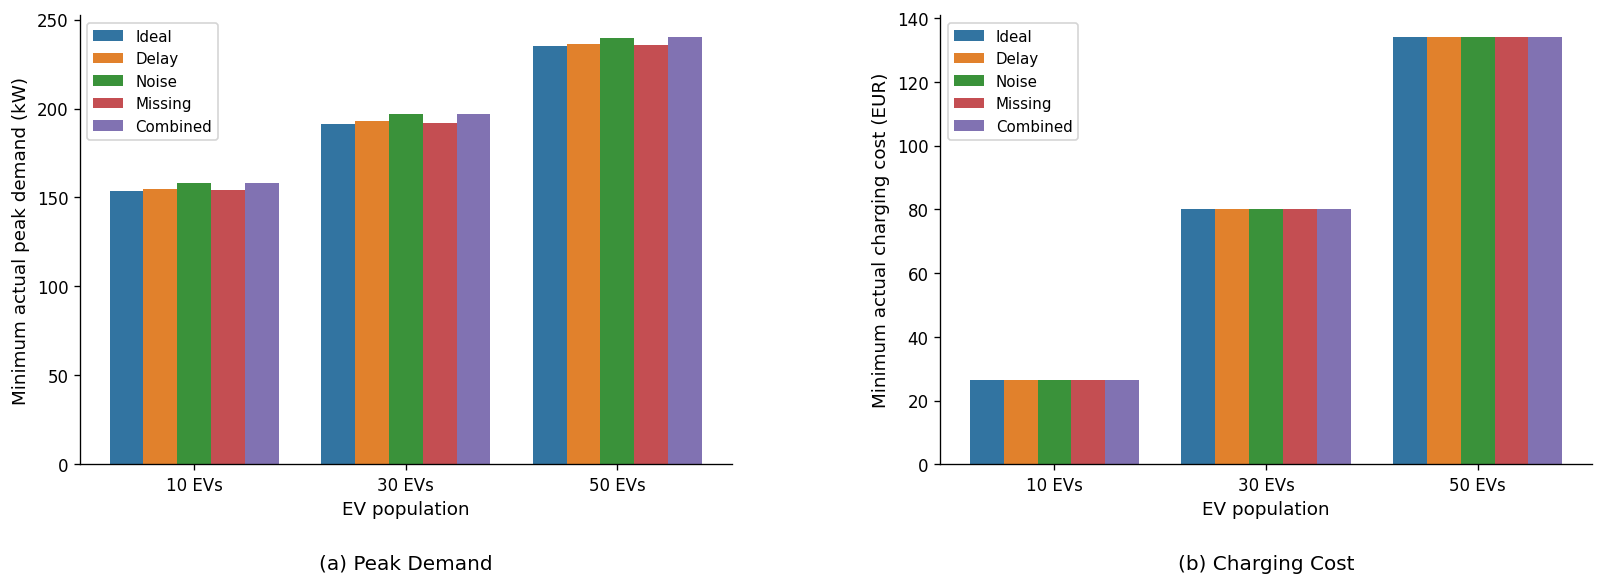


STEP 21.21A COMPLETED
Panels: (a) Peak Demand, (b) Charging Cost
Legends: Upper-left corner of each plot
Captions: Normal font weight
Gridlines: None
Saved: JPG, PDF, TIFF at 300 DPI
Output directory: /content/drive/MyDrive/IOEV_Ablation_Study/Results/Step21_Communication_Impairment/Full_Experiment/Figures/Composite


In [ ]:

# ============================================================
# STEP 21.21A: PEAK DEMAND AND CHARGING COST
# ============================================================
# (a) Peak Demand
# (b) Charging Cost
#
# Separate legends in upper-left corner
# Normal-weight panel captions
# No gridlines
# Save JPG, PDF and TIFF at 300 DPI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 75)
print("STEP 21.21A: PEAK DEMAND AND CHARGING COST")
print("=" * 75)

# 1. Define paths

ROOT = Path("/content/drive/MyDrive/IOEV_Ablation_Study")

FULL_DIR = (
    ROOT / "Results"
    / "Step21_Communication_Impairment"
    / "Full_Experiment"
)

FIG_DIR = FULL_DIR / "Figures" / "Composite"
FIG_DIR.mkdir(parents=True, exist_ok=True)

runs = pd.read_csv(
    FULL_DIR / "Validation"
    / "Step21_Validated_Run_Results.csv"
)

assert len(runs) == 450

# 2. Conditions and colours

conditions = [
    "ideal",
    "delayed_information",
    "measurement_noise",
    "missing_information",
    "combined_impairments"
]

labels = [
    "Ideal", "Delay", "Noise", "Missing", "Combined"
]

colors = [
    "#3274A1",
    "#E1812C",
    "#3A923A",
    "#C44E52",
    "#8172B2"
]

ev_counts = [10, 30, 50]

# 3. Figure formatting

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "savefig.dpi": 300
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5)
)

metrics = [
    (
        "best_actual_peak_kw",
        "Minimum actual peak demand (kW)",
        "(a) Peak Demand"
    ),
    (
        "best_actual_cost_eur",
        "Minimum actual charging cost (EUR)",
        "(b) Charging Cost"
    )
]

x = np.arange(len(ev_counts))
width = 0.16

# 4. Generate both panels

for ax, (metric, ylabel, caption) in zip(
    axes, metrics
):

    means = (
        runs.groupby(
            ["ev_count", "condition"]
        )[metric]
        .mean()
        .unstack()
        .reindex(
            index=ev_counts,
            columns=conditions
        )
    )

    for i, condition in enumerate(conditions):

        ax.bar(
            x + (i - 2) * width,
            means[condition].values,
            width=width,
            color=colors[i],
            label=labels[i],
            edgecolor="none"
        )

    ax.set_xticks(
        x,
        [f"{n} EVs" for n in ev_counts]
    )

    ax.set_xlabel("EV population")
    ax.set_ylabel(ylabel)

    # Remove all gridlines
    ax.grid(False)
    ax.xaxis.grid(False)
    ax.yaxis.grid(False)

    ax.tick_params(
        axis="both",
        direction="out",
        labelsize=10
    )

    # Separate legend in upper-left corner
    ax.legend(
        loc="upper left",
        fontsize=9,
        ncol=1,
        frameon=True,
        framealpha=0.95,
        facecolor="white",
        edgecolor="lightgray"
    )

    # Normal-weight caption below each plot
    ax.text(
        0.5,
        -0.20,
        caption,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=12,
        fontweight="normal"
    )

# 5. Adjust spacing

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.96,
    bottom=0.28,
    wspace=0.32
)

# 6. Save figures

output = FIG_DIR / "Step21_21A_Performance"

for extension in ["jpg", "pdf", "tiff"]:

    fig.savefig(
        f"{output}.{extension}",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()
plt.close(fig)

# 7. Completion

print("\nSTEP 21.21A COMPLETED")
print("Panels: (a) Peak Demand, (b) Charging Cost")
print("Legends: Upper-left corner of each plot")
print("Captions: Normal font weight")
print("Gridlines: None")
print("Saved: JPG, PDF, TIFF at 300 DPI")
print("Output directory:", FIG_DIR)


STEP 21.21B: STATISTICAL SENSITIVITY ANALYSIS


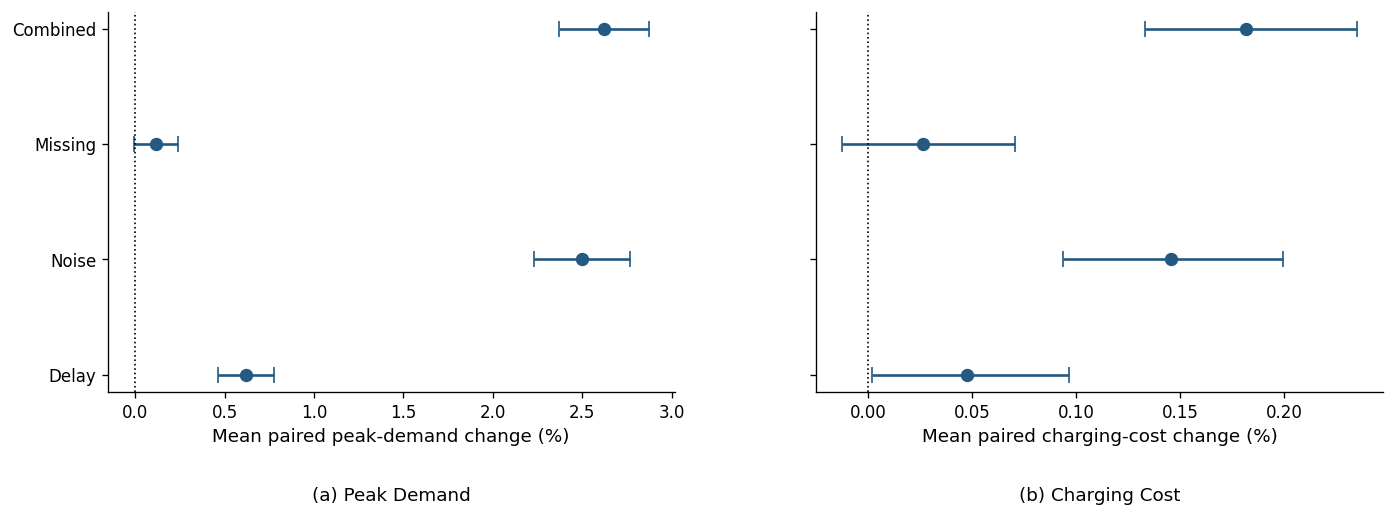


STEP 21.21B COMPLETED
Panels: (a) Peak Demand, (b) Charging Cost
Captions: Normal font weight
Gridlines: None
Confidence intervals: 95% bootstrap
Saved formats: JPG, PDF, TIFF
Resolution: 300 DPI
Output directory: /content/drive/MyDrive/IOEV_Ablation_Study/Results/Step21_Communication_Impairment/Full_Experiment/Figures/Composite


In [ ]:

# ============================================================
# STEP 21.21B: STATISTICAL SENSITIVITY ANALYSIS
# ============================================================
# (a) Peak Demand
# (b) Charging Cost
#
# 95% bootstrap confidence intervals
# No gridlines
# Normal-weight panel captions
# Outputs: JPG, PDF, TIFF at 300 DPI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 75)
print("STEP 21.21B: STATISTICAL SENSITIVITY ANALYSIS")
print("=" * 75)

ROOT = Path("/content/drive/MyDrive/IOEV_Ablation_Study")

FULL_DIR = (
    ROOT / "Results"
    / "Step21_Communication_Impairment"
    / "Full_Experiment"
)

FIG_DIR = FULL_DIR / "Figures" / "Composite"
FIG_DIR.mkdir(parents=True, exist_ok=True)

stats = pd.read_csv(
    FULL_DIR / "Statistical_Analysis"
    / "Step21_Paired_Statistical_Comparisons.csv"
)

overall = stats[
    stats["ev_population"] == "All EV populations"
].copy()

conditions = [
    "delayed_information",
    "measurement_noise",
    "missing_information",
    "combined_impairments"
]

labels = [
    "Delay",
    "Noise",
    "Missing",
    "Combined"
]

metrics = [
    (
        "best_actual_peak_kw",
        "(a) Peak Demand",
        "Mean paired peak-demand change (%)"
    ),
    (
        "best_actual_cost_eur",
        "(b) Charging Cost",
        "Mean paired charging-cost change (%)"
    )
]

# ============================================================
# FIGURE FORMATTING
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "savefig.dpi": 300
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.5, 4.8),
    sharey=True
)

# ============================================================
# GENERATE BOTH PANELS
# ============================================================

for ax, (metric, caption, xlabel) in zip(
    axes, metrics
):

    sub = (
        overall[overall["metric"] == metric]
        .set_index("condition")
        .loc[conditions]
    )

    values = sub[
        "mean_relative_change_pct"
    ].to_numpy()

    lower = sub[
        "relative_ci_lower_pct"
    ].to_numpy()

    upper = sub[
        "relative_ci_upper_pct"
    ].to_numpy()

    errors = np.vstack([
        values - lower,
        upper - values
    ])

    y = np.arange(4)

    ax.errorbar(
        values,
        y,
        xerr=errors,
        fmt="o",
        markersize=7,
        capsize=5,
        linewidth=1.6,
        color="#245A81",
        ecolor="#245A81"
    )

    # Reference line at zero
    ax.axvline(
        0,
        color="black",
        linestyle=":",
        linewidth=1
    )

    ax.set_yticks(y, labels)
    ax.invert_yaxis()

    ax.set_xlabel(xlabel)

    # Remove gridlines
    ax.grid(False)
    ax.xaxis.grid(False)
    ax.yaxis.grid(False)

    ax.tick_params(
        axis="both",
        direction="out",
        labelsize=10
    )

    # Normal-weight caption below each panel
    ax.text(
        0.5,
        -0.25,
        caption,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=11,
        fontweight="normal"
    )

# ============================================================
# ADJUST SPACING
# ============================================================

fig.subplots_adjust(
    left=0.13,
    right=0.98,
    top=0.96,
    bottom=0.30,
    wspace=0.25
)

# ============================================================
# SAVE FIGURES
# ============================================================

output = (
    FIG_DIR / "Step21_21B_Statistical_Sensitivity"
)

for extension in ["jpg", "pdf", "tiff"]:

    fig.savefig(
        f"{output}.{extension}",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()
plt.close(fig)

print("\n" + "=" * 75)
print("STEP 21.21B COMPLETED")
print("=" * 75)

print("Panels: (a) Peak Demand, (b) Charging Cost")
print("Captions: Normal font weight")
print("Gridlines: None")
print("Confidence intervals: 95% bootstrap")
print("Saved formats: JPG, PDF, TIFF")
print("Resolution: 300 DPI")
print("Output directory:", FIG_DIR)


STEP 21.21C: SCENARIO-LEVEL SENSITIVITY


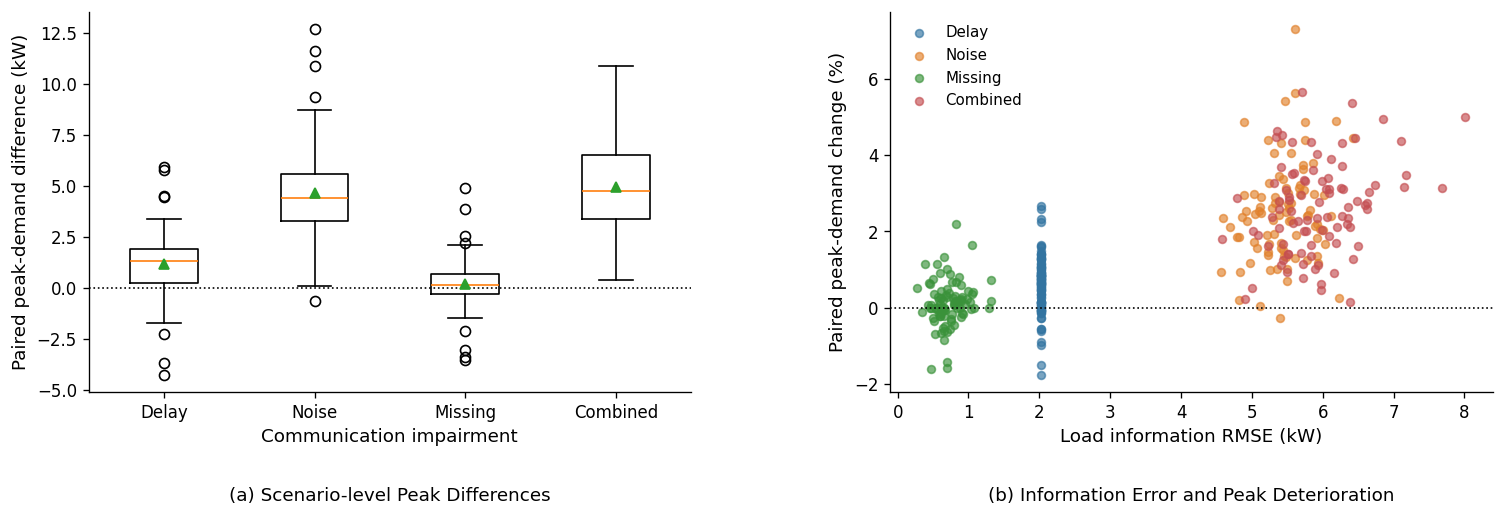


STEP 21.21C COMPLETED
Panel (a): Scenario-level Peak Differences
Panel (b): Information Error and Peak Deterioration
Captions: Normal font weight
Gridlines: None
Saved formats: JPG, PDF, TIFF
Resolution: 300 DPI
Output directory: /content/drive/MyDrive/IOEV_Ablation_Study/Results/Step21_Communication_Impairment/Full_Experiment/Figures/Composite


In [ ]:

# ============================================================
# STEP 21.21C: SCENARIO-LEVEL SENSITIVITY
# ============================================================
# (a) Scenario-level Peak Differences
# (b) Information Error and Peak Deterioration
#
# No gridlines
# Normal-weight captions
# Outputs: JPG, PDF, TIFF at 300 DPI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 75)
print("STEP 21.21C: SCENARIO-LEVEL SENSITIVITY")
print("=" * 75)

# 1. Define paths

ROOT = Path("/content/drive/MyDrive/IOEV_Ablation_Study")

FULL_DIR = (
    ROOT / "Results"
    / "Step21_Communication_Impairment"
    / "Full_Experiment"
)

FIG_DIR = FULL_DIR / "Figures" / "Composite"
FIG_DIR.mkdir(parents=True, exist_ok=True)

runs = pd.read_csv(
    FULL_DIR / "Validation"
    / "Step21_Validated_Run_Results.csv"
)

assert len(runs) == 450

# 2. Conditions, labels and colours

conditions = [
    "delayed_information",
    "measurement_noise",
    "missing_information",
    "combined_impairments"
]

labels = [
    "Delay",
    "Noise",
    "Missing",
    "Combined"
]

colors = [
    "#3274A1",
    "#E1812C",
    "#3A923A",
    "#C44E52"
]

# 3. Figure formatting

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "savefig.dpi": 300
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 4.8)
)

# ============================================================
# PANEL (a): PAIRED PEAK-DEMAND DIFFERENCES
# ============================================================

wide = runs.pivot(
    index=["ev_count", "run_index"],
    columns="condition",
    values="best_actual_peak_kw"
).sort_index()

assert len(wide) == 90
assert wide[["ideal"] + conditions].notna().all().all()

differences = [
    (
        wide[condition] - wide["ideal"]
    ).to_numpy()
    for condition in conditions
]

axes[0].boxplot(
    differences,
    tick_labels=labels,
    showmeans=True,
    patch_artist=False
)

axes[0].axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=1
)

axes[0].set_ylabel(
    "Paired peak-demand difference (kW)"
)

axes[0].set_xlabel(
    "Communication impairment"
)

# Remove all gridlines
axes[0].grid(False)
axes[0].xaxis.grid(False)
axes[0].yaxis.grid(False)

# Normal-weight panel caption
axes[0].text(
    0.5,
    -0.25,
    "(a) Scenario-level Peak Differences",
    transform=axes[0].transAxes,
    ha="center",
    va="top",
    fontsize=11,
    fontweight="normal"
)

# ============================================================
# PANEL (b): INFORMATION ERROR
# ============================================================

baseline = (
    runs[runs["condition"] == "ideal"]
    [
        [
            "ev_count",
            "run_index",
            "best_actual_peak_kw"
        ]
    ]
    .rename(columns={
        "best_actual_peak_kw": "ideal_peak_kw"
    })
)

impaired = runs[
    runs["condition"] != "ideal"
].merge(
    baseline,
    on=["ev_count", "run_index"],
    validate="many_to_one"
)

assert len(impaired) == 360

impaired["peak_change_pct"] = (
    100
    * (
        impaired["best_actual_peak_kw"]
        - impaired["ideal_peak_kw"]
    )
    / impaired["ideal_peak_kw"]
)

for condition, label, color in zip(
    conditions,
    labels,
    colors
):

    subset = impaired[
        impaired["condition"] == condition
    ]

    axes[1].scatter(
        subset["load_information_rmse_kw"],
        subset["peak_change_pct"],
        s=22,
        alpha=0.65,
        label=label,
        color=color
    )

axes[1].axhline(
    0,
    color="black",
    linestyle=":",
    linewidth=1
)

axes[1].set_xlabel(
    "Load information RMSE (kW)"
)

axes[1].set_ylabel(
    "Paired peak-demand change (%)"
)

# Legend in upper-left corner
axes[1].legend(
    loc="upper left",
    frameon=False,
    fontsize=9
)

# Remove all gridlines
axes[1].grid(False)
axes[1].xaxis.grid(False)
axes[1].yaxis.grid(False)

# Normal-weight panel caption
axes[1].text(
    0.5,
    -0.25,
    "(b) Information Error and Peak Deterioration",
    transform=axes[1].transAxes,
    ha="center",
    va="top",
    fontsize=11,
    fontweight="normal"
)

# ============================================================
# 4. ADJUST SPACING
# ============================================================

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.96,
    bottom=0.30,
    wspace=0.33
)

# ============================================================
# 5. SAVE FIGURES
# ============================================================

output = (
    FIG_DIR / "Step21_21C_Scenario_Sensitivity"
)

for extension in ["jpg", "pdf", "tiff"]:

    fig.savefig(
        f"{output}.{extension}",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()
plt.close(fig)

# ============================================================
# 6. COMPLETION
# ============================================================

print("\n" + "=" * 75)
print("STEP 21.21C COMPLETED")
print("=" * 75)

print("Panel (a): Scenario-level Peak Differences")
print("Panel (b): Information Error and Peak Deterioration")
print("Captions: Normal font weight")
print("Gridlines: None")
print("Saved formats: JPG, PDF, TIFF")
print("Resolution: 300 DPI")
print("Output directory:", FIG_DIR)


In [ ]:

# ============================================================
# STEP 21.22: PUBLICATION-READY RESULTS TABLES
# ============================================================
# Scientific Reports manuscript
#
# Inputs:
# Step 21.19 validated results
# Step 21.20 statistical comparisons
# Step 21.17 experiment configuration
#
# Outputs:
# Five CSV tables
# One Excel workbook
# One metadata JSON file
#
# No optimization runs.
# ============================================================

import json
import numpy as np
import pandas as pd

from pathlib import Path
from datetime import datetime, timezone

print("=" * 75)
print("STEP 21.22: PUBLICATION-READY RESULTS TABLES")
print("=" * 75)

# ============================================================
# 1. DEFINE PROJECT PATHS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/IOEV_Ablation_Study"
)

FULL_DIR = (
    ROOT / "Results"
    / "Step21_Communication_Impairment"
    / "Full_Experiment"
)

VALIDATION_DIR = FULL_DIR / "Validation"
STAT_DIR = FULL_DIR / "Statistical_Analysis"

TABLE_DIR = FULL_DIR / "Manuscript_Tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

RUNS_FILE = (
    VALIDATION_DIR /
    "Step21_Validated_Run_Results.csv"
)

STATS_FILE = (
    STAT_DIR /
    "Step21_Paired_Statistical_Comparisons.csv"
)

CONFIG_FILE = (
    FULL_DIR /
    "Step21_Full_Experiment_Config.json"
)

VALIDATION_FILE = (
    VALIDATION_DIR /
    "Step21_Validation_Report.json"
)

for path in [
    RUNS_FILE,
    STATS_FILE,
    CONFIG_FILE,
    VALIDATION_FILE
]:
    if not path.exists():
        raise FileNotFoundError(path)

runs = pd.read_csv(RUNS_FILE)
stats = pd.read_csv(STATS_FILE)

with open(CONFIG_FILE, "r", encoding="utf-8") as f:
    config = json.load(f)

with open(VALIDATION_FILE, "r", encoding="utf-8") as f:
    validation = json.load(f)

assert validation["status"] == "PASSED"
assert len(runs) == 450
assert runs["run_id"].is_unique
assert len(stats) == 32

print("\nInput files verified.")
print("Validated runs:", len(runs))
print("Statistical comparisons:", len(stats))

# ============================================================
# 2. DEFINE CONDITION LABELS AND ORDER
# ============================================================

CONDITION_ORDER = [
    "ideal",
    "delayed_information",
    "measurement_noise",
    "missing_information",
    "combined_impairments"
]

CONDITION_LABELS = {
    "ideal": "Ideal information",
    "delayed_information": "Delayed information",
    "measurement_noise": "Measurement noise",
    "missing_information": "Missing information",
    "combined_impairments": "Combined impairments"
}

POPULATIONS = [10, 30, 50]

def condition_label(condition):
    return CONDITION_LABELS.get(
        condition, str(condition)
    )

def format_mean_sd(values, digits=3):
    values = pd.Series(values).dropna()

    return (
        f"{values.mean():.{digits}f} "
        f"± {values.std(ddof=1):.{digits}f}"
    )

def format_ci(lower, upper, digits=3):
    return (
        f"[{lower:.{digits}f}, "
        f"{upper:.{digits}f}]"
    )

def format_p(p):
    p = float(p)

    if p < 0.001:
        return "<0.001"

    return f"{p:.3f}"

# ============================================================
# 3. TABLE 1: EXPERIMENTAL CONFIGURATION
# ============================================================

impairment_config = config[
    "communication_impairment_config"
]

configuration_rows = [
    ("EV populations", str(config["ev_counts"])),
    (
        "Independent scenarios per population",
        str(config["independent_runs"])
    ),
    (
        "Total paired scenarios",
        str(
            len(POPULATIONS)
            * config["independent_runs"]
        )
    ),
    ("Communication conditions", "5"),
    ("Total optimization runs", "450"),
    (
        "NSGA-II population size",
        str(config["population_size"])
    ),
    (
        "NSGA-II generations",
        str(config["generations"])
    ),
    (
        "Scheduling horizon",
        f"{config['slots']} time slots"
    ),
    (
        "Time-slot duration",
        "15 minutes"
    ),
    (
        "Total scheduling duration",
        "24 hours"
    ),
    (
        "Performance evaluation",
        "True load and electricity price"
    ),
    (
        "Baseline",
        "Ideal information (oracle)"
    ),
    (
        "Statistical unit",
        "Paired EV scenario"
    ),
    (
        "Bootstrap repetitions",
        "10,000"
    ),
    (
        "Confidence interval",
        "95%"
    ),
    (
        "Statistical test",
        "Two-sided Wilcoxon signed-rank"
    ),
    (
        "Multiple-testing correction",
        "Holm correction"
    )
]

# Include the actual saved impairment configuration
# rather than manually assuming its parameter names.
for key, value in impairment_config.items():

    if isinstance(value, (dict, list)):
        value = json.dumps(
            value,
            sort_keys=True
        )

    configuration_rows.append(
        (
            "Impairment parameter: " + str(key),
            str(value)
        )
    )

table1 = pd.DataFrame(
    configuration_rows,
    columns=[
        "Parameter",
        "Setting"
    ]
)

# ============================================================
# 4. TABLE 2: PEAK DEMAND AND CHARGING COST
# ============================================================

table2_rows = []

for ev_count in POPULATIONS:

    subset = runs[
        runs["ev_count"] == ev_count
    ]

    for condition in CONDITION_ORDER:

        group = subset[
            subset["condition"] == condition
        ]

        assert len(group) == 30

        table2_rows.append({
            "EV population": ev_count,
            "Communication condition":
                condition_label(condition),
            "Scenarios": len(group),
            "Minimum peak demand (kW), mean ± SD":
                format_mean_sd(
                    group["best_actual_peak_kw"]
                ),
            "Minimum charging cost (EUR), mean ± SD":
                format_mean_sd(
                    group["best_actual_cost_eur"]
                ),
            "Mean peak demand (kW)":
                round(
                    group["best_actual_peak_kw"].mean(),
                    3
                ),
            "Mean charging cost (EUR)":
                round(
                    group["best_actual_cost_eur"].mean(),
                    3
                )
        })

table2 = pd.DataFrame(table2_rows)

# ============================================================
# 5. TABLE 3: OVERALL PAIRED STATISTICAL RESULTS
# ============================================================

overall_stats = stats[
    stats["ev_population"]
    == "All EV populations"
].copy()

metric_labels = {
    "best_actual_peak_kw":
        "Minimum peak demand (kW)",
    "best_actual_cost_eur":
        "Minimum charging cost (EUR)"
}

table3_rows = []

for metric in metric_labels:

    for condition in CONDITION_ORDER[1:]:

        matching = overall_stats[
            (overall_stats["metric"] == metric)
            & (overall_stats["condition"] == condition)
        ]

        assert len(matching) == 1

        row = matching.iloc[0]

        table3_rows.append({
            "Performance metric":
                metric_labels[metric],
            "Communication impairment":
                condition_label(condition),
            "Paired scenarios":
                int(row["paired_scenarios"]),
            "Mean absolute difference":
                round(
                    row["mean_difference"], 4
                ),
            "95% CI, absolute difference":
                format_ci(
                    row["difference_ci_lower"],
                    row["difference_ci_upper"],
                    4
                ),
            "Mean relative change (%)":
                round(
                    row["mean_relative_change_pct"],
                    4
                ),
            "95% CI, relative change (%)":
                format_ci(
                    row["relative_ci_lower_pct"],
                    row["relative_ci_upper_pct"],
                    4
                ),
            "Holm-adjusted p-value":
                format_p(
                    row["wilcoxon_p_holm"]
                ),
            "Statistically significant (0.05)":
                (
                    "Yes"
                    if row["significant_holm_005"]
                    else "No"
                )
        })

table3 = pd.DataFrame(table3_rows)

# ============================================================
# 6. TABLE 4: EV POPULATION SENSITIVITY
# ============================================================

table4_rows = []

for ev_count in POPULATIONS:

    population_label = f"{ev_count} EVs"

    for metric in metric_labels:

        for condition in CONDITION_ORDER[1:]:

            matching = stats[
                (
                    stats["ev_population"]
                    == population_label
                )
                & (stats["metric"] == metric)
                & (stats["condition"] == condition)
            ]

            assert len(matching) == 1

            row = matching.iloc[0]

            table4_rows.append({
                "EV population": ev_count,
                "Performance metric":
                    metric_labels[metric],
                "Communication impairment":
                    condition_label(condition),
                "Mean relative change (%)":
                    round(
                        row["mean_relative_change_pct"],
                        4
                    ),
                "95% CI, relative change (%)":
                    format_ci(
                        row["relative_ci_lower_pct"],
                        row["relative_ci_upper_pct"],
                        4
                    ),
                "Holm-adjusted p-value":
                    format_p(
                        row["wilcoxon_p_holm"]
                    ),
                "Significant at 0.05":
                    (
                        "Yes"
                        if row["significant_holm_005"]
                        else "No"
                    )
            })

table4 = pd.DataFrame(table4_rows)

# ============================================================
# 7. TABLE 5: FEASIBILITY AND COMPUTATIONAL PERFORMANCE
# ============================================================

table5_rows = []

for ev_count in POPULATIONS:

    for condition in CONDITION_ORDER:

        group = runs[
            (runs["ev_count"] == ev_count)
            & (runs["condition"] == condition)
        ]

        assert len(group) == 30

        table5_rows.append({
            "EV population": ev_count,
            "Communication condition":
                condition_label(condition),
            "Scenarios": len(group),
            "Operational feasibility (%)":
                round(
                    group[
                        "operational_feasibility_pct"
                    ].mean(),
                    3
                ),
            "Mean target satisfaction (%)":
                round(
                    group[
                        "mean_target_success_pct"
                    ].mean(),
                    3
                ),
            "Mean unmet energy (kWh)":
                round(
                    group[
                        "mean_unmet_energy_kwh"
                    ].mean(),
                    3
                ),
            "Runtime (s), mean ± SD":
                format_mean_sd(
                    group["runtime_seconds"],
                    digits=2
                ),
            "Load information RMSE (kW)":
                round(
                    group[
                        "load_information_rmse_kw"
                    ].mean(),
                    3
                ),
            "Price information RMSE":
                round(
                    group[
                        "price_information_rmse"
                    ].mean(),
                    5
                )
        })

table5 = pd.DataFrame(table5_rows)

# ============================================================
# 8. SAVE FIVE TABLES AS CSV
# ============================================================

tables = {
    "Table_1_Experimental_Configuration": table1,
    "Table_2_Optimization_Performance": table2,
    "Table_3_Paired_Statistical_Results": table3,
    "Table_4_EV_Population_Sensitivity": table4,
    "Table_5_Feasibility_and_Runtime": table5
}

for filename, table in tables.items():

    path = TABLE_DIR / f"{filename}.csv"

    table.to_csv(
        path,
        index=False
    )

    print(
        f"Saved: {path.name} "
        f"({len(table)} rows)"
    )

# ============================================================
# 9. SAVE COMBINED EXCEL WORKBOOK
# ============================================================

excel_path = (
    TABLE_DIR /
    "Step21_Manuscript_Results_Tables.xlsx"
)

with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    for sheet_name, table in zip(
        [
            "Table 1 Configuration",
            "Table 2 Performance",
            "Table 3 Statistics",
            "Table 4 Sensitivity",
            "Table 5 Feasibility"
        ],
        tables.values()
    ):

        table.to_excel(
            writer,
            sheet_name=sheet_name,
            index=False
        )

        worksheet = writer.sheets[sheet_name]

        worksheet.freeze_panes = "A2"
        worksheet.auto_filter.ref = (
            worksheet.dimensions
        )

        from openpyxl.styles import (
            Font,
            PatternFill,
            Alignment
        )

        for cell in worksheet[1]:

            cell.font = Font(
                bold=True,
                color="FFFFFF"
            )

            cell.fill = PatternFill(
                fill_type="solid",
                fgColor="24476B"
            )

            cell.alignment = Alignment(
                wrap_text=True,
                vertical="center"
            )

        worksheet.row_dimensions[1].height = 42

        for column_cells in worksheet.columns:

            letter = column_cells[0].column_letter

            max_length = max(
                len(str(cell.value))
                if cell.value is not None else 0
                for cell in column_cells
            )

            worksheet.column_dimensions[
                letter
            ].width = min(
                max(max_length + 3, 15),
                48
            )

# ============================================================
# 10. SAVE TABLE METADATA
# ============================================================

metadata = {
    "step": "21.22",
    "status": "COMPLETED",
    "source_runs": 450,
    "paired_scenarios": 90,
    "statistical_comparisons": 32,
    "tables_generated": len(tables),
    "table_row_counts": {
        name: len(table)
        for name, table in tables.items()
    },
    "baseline":
        "Ideal information using true load and price",
    "important_note":
        (
            "Minimum peak demand and minimum charging "
            "cost may correspond to different Pareto "
            "solutions. Operational feasibility does "
            "not imply complete charging target "
            "satisfaction."
        ),
    "generated_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

metadata_path = (
    TABLE_DIR /
    "Step21_Manuscript_Tables_Metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=2
    )

# ============================================================
# 11. PRINT TABLE PREVIEWS
# ============================================================

for name, table in tables.items():

    print("\n" + "=" * 75)
    print(name.replace("_", " ").upper())
    print("=" * 75)

    print(
        table.head(15).to_string(
            index=False
        )
    )

# ============================================================
# 12. FINAL VERIFICATION
# ============================================================

assert len(table1) >= 18
assert len(table2) == 15
assert len(table3) == 8
assert len(table4) == 24
assert len(table5) == 15

assert excel_path.exists()

csv_files = list(
    TABLE_DIR.glob("Table_*.csv")
)

assert len(csv_files) == 5

print("\n" + "=" * 75)
print("STEP 21.22 COMPLETED")
print("=" * 75)

print("Publication tables:", len(tables))
print("CSV files:", len(csv_files))
print("Excel workbook:", excel_path.name)
print("Optimization runs performed: 0")

print("\nOutput directory:")
print(TABLE_DIR)

print(
    "\nSUCCESS: Manuscript results tables "
    "generated and verified."
)


STEP 21.22: PUBLICATION-READY RESULTS TABLES

Input files verified.
Validated runs: 450
Statistical comparisons: 32
Saved: Table_1_Experimental_Configuration.csv (27 rows)
Saved: Table_2_Optimization_Performance.csv (15 rows)
Saved: Table_3_Paired_Statistical_Results.csv (8 rows)
Saved: Table_4_EV_Population_Sensitivity.csv (24 rows)
Saved: Table_5_Feasibility_and_Runtime.csv (15 rows)

TABLE 1 EXPERIMENTAL CONFIGURATION
                           Parameter                         Setting
                      EV populations                    [10, 30, 50]
Independent scenarios per population                              30
              Total paired scenarios                              90
            Communication conditions                               5
             Total optimization runs                             450
             NSGA-II population size                              50
                 NSGA-II generations                              30
                  Sched

In [ ]:

# ============================================================
# CHECK GOOGLE DRIVE AND EXISTING PROJECT FILES
# ============================================================

from pathlib import Path
import os

print("=" * 70)
print("GOOGLE DRIVE AND PROJECT DIAGNOSTIC")
print("=" * 70)

locations = [
    Path("/content/drive"),
    Path("/content/drive/MyDrive"),
    Path("/content/google_drive_new"),
    Path("/content/google_drive_new/MyDrive")
]

for path in locations:
    print(f"\nLocation: {path}")
    print("Exists:", path.exists())
    print("Mounted:", os.path.ismount(path))

    if path.is_dir():
        print("Contents:", [p.name for p in list(path.iterdir())[:15]])

print("\n" + "=" * 70)
print("CHECKING PROJECT FOLDER")
print("=" * 70)

for base in [
    Path("/content/drive/MyDrive"),
    Path("/content/google_drive_new/MyDrive")
]:
    project = base / "IOEV_Ablation_Study"

    print(f"\nProject: {project}")
    print("Exists:", project.exists())

    if project.is_dir():
        print("Contents:", [p.name for p in project.iterdir()])


GOOGLE DRIVE AND PROJECT DIAGNOSTIC

Location: /content/drive
Exists: True
Mounted: False
Contents: ['MyDrive']

Location: /content/drive/MyDrive
Exists: True
Mounted: False
Contents: ['IOEV_Ablation_Study']

Location: /content/google_drive_new
Exists: False
Mounted: False

Location: /content/google_drive_new/MyDrive
Exists: False
Mounted: False

CHECKING PROJECT FOLDER

Project: /content/drive/MyDrive/IOEV_Ablation_Study
Exists: True
Contents: ['Results']

Project: /content/google_drive_new/MyDrive/IOEV_Ablation_Study
Exists: False


In [ ]:

# ============================================================
# STEP 2: RESTORE GOOGLE DRIVE CONNECTION SAFELY
# ============================================================

from google.colab import drive
from pathlib import Path
import os

print("=" * 70)
print("RESTORING GOOGLE DRIVE CONNECTION")
print("=" * 70)

# Use a new location to avoid the existing local folder.
MOUNT_POINT = "/content/drive_reconnected"

if not os.path.ismount(MOUNT_POINT):
    drive.mount(MOUNT_POINT)

ROOT = (
    Path(MOUNT_POINT)
    / "MyDrive"
    / "IOEV_Ablation_Study"
)

print("\nGoogle Drive mounted:",
      os.path.ismount(MOUNT_POINT))

print("Project folder exists:", ROOT.exists())
print("Project directory:", ROOT)

if ROOT.is_dir():
    print("\nProject contents:")
    for item in ROOT.iterdir():
        print(" ", item.name)

    stats_file = (
        ROOT
        / "Results"
        / "Step21_Communication_Impairment"
        / "Full_Experiment"
        / "Statistical_Analysis"
        / "Step21_Paired_Statistical_Comparisons.csv"
    )

    print("\nStatistical CSV exists:",
          stats_file.is_file())

    if stats_file.is_file():
        print("Statistical results located successfully!")
        print("File:", stats_file)


RESTORING GOOGLE DRIVE CONNECTION
Mounted at /content/drive_reconnected

Google Drive mounted: True
Project folder exists: True
Project directory: /content/drive_reconnected/MyDrive/IOEV_Ablation_Study

Project contents:
  Configuration
  Data
  Scenarios
  Results
  Figures
  Statistics
  Benchmarks
  Logs
  EnergyStreams
  JourneyCharge
  AblationStudyIOEV.ipynb
  Communication_Impairment_Study.ipynb

Statistical CSV exists: True
Statistical results located successfully!
File: /content/drive_reconnected/MyDrive/IOEV_Ablation_Study/Results/Step21_Communication_Impairment/Full_Experiment/Statistical_Analysis/Step21_Paired_Statistical_Comparisons.csv


STEP 21.21B: STATISTICAL SENSITIVITY ANALYSIS


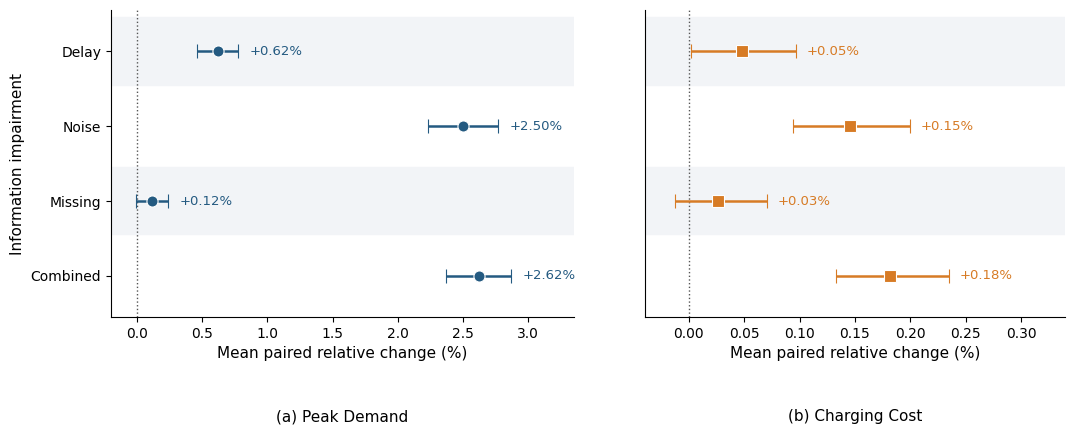


STEP 21.21B COMPLETED
Panels: (a) Peak Demand, (b) Charging Cost
Y-axis labels: Delay, Noise, Missing, Combined
Panel captions: Below x-axis, normal weight
Legend: None
Gridlines: None
Confidence intervals: 95% bootstrap
Saved formats: JPG, PDF, TIFF
Resolution: 300 DPI
Output directory: /content/drive_reconnected/MyDrive/IOEV_Ablation_Study/Results/Step21_Communication_Impairment/Full_Experiment/Figures/Composite


In [10]:

# ============================================================
# STEP 21.21B: STATISTICAL SENSITIVITY ANALYSIS
# ============================================================
# (a) Peak Demand
# (b) Charging Cost
#
# Shortened y-axis labels
# Panel captions below the x-axis, normal font weight
# No legend and no gridlines
# 95% bootstrap confidence intervals
# JPG, PDF and TIFF at 300 DPI
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 75)
print("STEP 21.21B: STATISTICAL SENSITIVITY ANALYSIS")
print("=" * 75)

# ============================================================
# 1. DEFINE PATHS
# ============================================================

ROOT = Path(
    "/content/drive_reconnected/MyDrive/IOEV_Ablation_Study"
)

FULL_DIR = (
    ROOT / "Results"
    / "Step21_Communication_Impairment"
    / "Full_Experiment"
)

STATS_FILE = (
    FULL_DIR / "Statistical_Analysis"
    / "Step21_Paired_Statistical_Comparisons.csv"
)

FIG_DIR = FULL_DIR / "Figures" / "Composite"
FIG_DIR.mkdir(parents=True, exist_ok=True)

if not STATS_FILE.is_file():
    raise FileNotFoundError(
        f"Statistical results not found: {STATS_FILE}"
    )

stats = pd.read_csv(STATS_FILE)

# ============================================================
# 2. SELECT OVERALL RESULTS
# ============================================================

overall = stats[
    stats["ev_population"].astype(str)
    == "All EV populations"
].copy()

conditions = [
    "delayed_information",
    "measurement_noise",
    "missing_information",
    "combined_impairments"
]

# Shortened labels
labels = [
    "Delay",
    "Noise",
    "Missing",
    "Combined"
]

metrics = [
    {
        "column": "best_actual_peak_kw",
        "caption": "(a) Peak Demand",
        "color": "#245A81",
        "marker": "o",
        "xlim": (-0.20, 3.35),
        "ticks": np.arange(0, 3.5, 0.5)
    },
    {
        "column": "best_actual_cost_eur",
        "caption": "(b) Charging Cost",
        "color": "#D77B25",
        "marker": "s",
        "xlim": (-0.04, 0.34),
        "ticks": np.arange(0, 0.35, 0.05)
    }
]

# ============================================================
# 3. FIGURE FORMATTING
# ============================================================

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "savefig.dpi": 300
})

fig, axes = plt.subplots(
    1, 2,
    figsize=(11.5, 4.8),
    sharey=True,
    gridspec_kw={"width_ratios": [1.1, 1]}
)

y = np.arange(len(conditions))

# ============================================================
# 4. GENERATE BOTH PANELS
# ============================================================

for ax, metric in zip(axes, metrics):

    sub = (
        overall[
            overall["metric"] == metric["column"]
        ]
        .set_index("condition")
        .loc[conditions]
    )

    values = sub[
        "mean_relative_change_pct"
    ].to_numpy(dtype=float)

    lower = sub[
        "relative_ci_lower_pct"
    ].to_numpy(dtype=float)

    upper = sub[
        "relative_ci_upper_pct"
    ].to_numpy(dtype=float)

    errors = np.vstack([
        values - lower,
        upper - values
    ])

    # Alternating row shading
    for i in range(len(conditions)):
        if i % 2 == 0:
            ax.axhspan(
                i - 0.45,
                i + 0.45,
                color="#F2F4F7",
                zorder=0
            )

    # Reference line at zero
    ax.axvline(
        0,
        color="#555555",
        linestyle=":",
        linewidth=1.0,
        zorder=1
    )

    # Confidence intervals
    ax.errorbar(
        values,
        y,
        xerr=errors,
        fmt=metric["marker"],
        markersize=8,
        color=metric["color"],
        ecolor=metric["color"],
        markeredgecolor="white",
        markeredgewidth=0.8,
        elinewidth=1.8,
        capsize=5,
        capthick=1.6,
        linestyle="none",
        zorder=3
    )

    # Numerical percentage labels
    span = metric["xlim"][1] - metric["xlim"][0]
    offset = span * 0.025

    for i, value in enumerate(values):
        ax.text(
            upper[i] + offset,
            y[i],
            f"{value:+.2f}%",
            ha="left",
            va="center",
            fontsize=9.5,
            color=metric["color"],
            fontweight="normal"
        )

    ax.set_xlim(*metric["xlim"])
    ax.set_xticks(metric["ticks"])

    ax.set_ylim(-0.55, 3.55)
    ax.invert_yaxis()

    ax.set_xlabel(
        "Mean paired relative change (%)",
        fontsize=11
    )

    # Panel caption below x-axis
    ax.text(
        0.5,
        -0.30,
        metric["caption"],
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=11,
        fontweight="normal"
    )

    ax.tick_params(
        axis="both",
        direction="out",
        labelsize=10
    )

    ax.grid(False)

# ============================================================
# 5. Y-AXIS LABELS
# ============================================================

axes[0].set_yticks(y)
axes[0].set_yticklabels(
    labels,
    fontsize=10
)

axes[0].set_ylabel(
    "Information impairment",
    fontsize=11
)

axes[0].tick_params(
    axis="y",
    labelleft=True
)

axes[1].tick_params(
    axis="y",
    left=False,
    labelleft=False
)

# ============================================================
# 6. SPACING
# ============================================================

fig.subplots_adjust(
    left=0.14,
    right=0.97,
    top=0.96,
    bottom=0.32,
    wspace=0.16
)

# ============================================================
# 7. SAVE FIGURE
# ============================================================

output = (
    FIG_DIR /
    "Step21_21B_Final_Statistical_Sensitivity"
)

for extension in ["jpg", "pdf", "tiff"]:

    fig.savefig(
        f"{output}.{extension}",
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

plt.show()
plt.close(fig)

# ============================================================
# 8. FINAL CONFIRMATION
# ============================================================

print("\n" + "=" * 75)
print("STEP 21.21B COMPLETED")
print("=" * 75)

print("Panels: (a) Peak Demand, (b) Charging Cost")
print("Y-axis labels: Delay, Noise, Missing, Combined")
print("Panel captions: Below x-axis, normal weight")
print("Legend: None")
print("Gridlines: None")
print("Confidence intervals: 95% bootstrap")
print("Saved formats: JPG, PDF, TIFF")
print("Resolution: 300 DPI")
print("Output directory:", FIG_DIR)
